# Court Referral Decision Model for Unsecured Overdue Loans

## Business problem

The decision to refer a case to court is made at the client level, not at the level of an individual loan. If legal proceedings start against a client, all of that client's relevant loans go into the process together. Note that we are only talking about unsecured loans.

The court process comes with significant costs, and resources are limited. So the task is not only about predicting whether the client will pay. The business goal of the model is to:

* identify the clients from whom the expected recovery is high enough;
* give priority to the clients who are financially the most profitable;
* reduce court referrals of clients where the cost incurred is higher than the expected recovery;
* at the same time, not miss the clients from whom a significant amount could really be recovered.

The final result should be a product that estimates, for each client, the expected recovery, the court cost and the expected net financial result, on the basis of which the clients to be referred to court can be prioritized.

### Selection bias

The historical data only contains the clients for whom the court referral decision had already been made in the past. This selection was not random and was based on expert rules and business decisions. So we do not know what the outcome would have been for the clients who were not sent to court under the expert rules.

To assess this problem fully, a controlled, small sample would have to be drawn from the clients rejected by the expert and, with the consent of the business, part of it would be referred to court at random, or reject inference would have to be done. We do not have such data at this stage, and I think the assignment does not expect this kind of analysis at this point.

## Initial configuration

Libraries, data paths and the main constants of the project: the monthly payment columns, the court cost parameters and the random seed.

In [70]:
%matplotlib inline

import hashlib
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier, XGBRegressor

DATA_RAW = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
OUTPUTS_DIR = Path("outputs")

PAY_COLS = [f"M{k:02d}_PAID" for k in range(1, 25)]
COST_FIXED, COST_PCT = 500, 0.10
BREAK_EVEN = COST_FIXED / (1 - COST_PCT)
SEED = 42

## 1. Data overview

Let's look at the datasets.

In [19]:
RECOVERY_PATH = DATA_RAW / "loan_month_recovery.csv"
FEATURES_PATH = DATA_RAW / "Features.csv"
DICT_PATH = next(DATA_RAW.glob("feature_dictionary*.csv"))


def load_raw(path: Path) -> pd.DataFrame:
    """Read a raw CSV as-is: no renaming, no cleaning, PERIOD kept as text (yyyy/MM)."""
    return pd.read_csv(path, dtype={"PERIOD": str})


def size_summary(df: pd.DataFrame) -> dict:
    """Shape of one table."""
    return {
        "rows": len(df),
        "columns": df.shape[1],
        "numeric columns": df.select_dtypes("number").shape[1],
        "non-numeric columns": df.select_dtypes(exclude="number").shape[1],
        "fully duplicated rows": int(df.duplicated().sum()),
    }


def recovery_basics(rec: pd.DataFrame) -> dict:
    """Keys, time span and granularity of the loan-level recovery file."""
    loans_per_cp = rec.groupby(["CLIENT_KEY", "PERIOD"]).size()
    return {
        "LOAN_KEY unique": bool(rec["LOAN_KEY"].is_unique),
        "distinct loans": rec["LOAN_KEY"].nunique(),
        "distinct clients": rec["CLIENT_KEY"].nunique(),
        "distinct client-periods": len(loans_per_cp),
        "PERIOD first": rec["PERIOD"].min(),
        "PERIOD last": rec["PERIOD"].max(),
        "distinct PERIODs (cohorts)": rec["PERIOD"].nunique(),
        "loans per client-period: mean": round(loans_per_cp.mean(), 2),
        "loans per client-period: median": float(loans_per_cp.median()),
        "loans per client-period: max": int(loans_per_cp.max()),
        "monthly payment columns": len(PAY_COLS),
        "MONTHS_OBSERVED min": int(rec["MONTHS_OBSERVED"].min()),
        "MONTHS_OBSERVED max": int(rec["MONTHS_OBSERVED"].max()),
    }


def features_basics(feat: pd.DataFrame, cols: list[str]) -> dict:
    """Keys, time span and completeness of the client-period feature file."""
    return {
        "(client_key, PERIOD) unique": bool(not feat.duplicated(["client_key", "PERIOD"]).any()),
        "distinct clients": feat["client_key"].nunique(),
        "distinct client-periods": len(feat[["client_key", "PERIOD"]].drop_duplicates()),
        "PERIOD first": feat["PERIOD"].min(),
        "PERIOD last": feat["PERIOD"].max(),
        "distinct PERIODs": feat["PERIOD"].nunique(),
        "feature columns": len(cols),
        "features with any NaN": int(feat[cols].isna().any().sum()),
        "features with a single value": int((feat[cols].nunique(dropna=False) == 1).sum()),
        "binary features (2 values)": int((feat[cols].nunique(dropna=True) == 2).sum()),
    }


def feature_ranges(columns: pd.Series) -> str:
    """Compress feature names into ranges of consecutive numbers, e.g. 'feature_001-feature_009'."""
    nums = pd.Series(sorted(int(c.split("_")[1]) for c in columns))
    runs = nums.groupby(nums.diff().ne(1).cumsum()).agg(["min", "max"])
    return ", ".join(
        f"feature_{a:03d}" if a == b else f"feature_{a:03d}-feature_{b:03d}"
        for a, b in runs.itertuples(index=False)
    )


def dictionary_by_group(fd: pd.DataFrame) -> pd.DataFrame:
    """Number of features and the feature columns covered by each dictionary group."""
    return (fd.assign(num=fd["column"].str.split("_").str[1].astype(int))
              .groupby("group", sort=False)
              .agg(features=("column", "size"), columns=("column", feature_ranges), first=("num", "min"))
              .sort_values("first")
              .drop(columns="first"))


recovery = load_raw(RECOVERY_PATH)
features = load_raw(FEATURES_PATH)
feat_dict = pd.read_csv(DICT_PATH)
FEATURE_COLS = [c for c in features.columns if c.startswith("feature_")]

display(pd.DataFrame.from_dict({
    RECOVERY_PATH.name: size_summary(recovery),
    FEATURES_PATH.name: size_summary(features),
    DICT_PATH.name: size_summary(feat_dict),
}, orient="index"))

display(pd.Series(recovery_basics(recovery), dtype="object").to_frame("recovery file"))
display(pd.Series(features_basics(features, FEATURE_COLS), dtype="object").to_frame("features file"))
display(dictionary_by_group(feat_dict))

for name, df in {RECOVERY_PATH.name: recovery, FEATURES_PATH.name: features, DICT_PATH.name: feat_dict}.items():
    print(name)
    display(df.head())

,rows,columns,numeric columns,non-numeric columns,fully duplicated rows
loan_month_recovery.csv,70173,33,30,3,0
Features.csv,29763,52,51,1,0
feature_dictionary.csv,50,4,0,4,0


,recovery file
LOAN_KEY unique,True
distinct loans,70173
distinct clients,22000
distinct client-periods,29763
PERIOD first,2023/01
PERIOD last,2026/02
distinct PERIODs (cohorts),38
loans per client-period: mean,2.36
loans per client-period: median,2.0
loans per client-period: max,7


,features file
"(client_key, PERIOD) unique",True
distinct clients,22000
distinct client-periods,29763
PERIOD first,2023/01
PERIOD last,2026/02
distinct PERIODs,38
feature columns,50
features with any NaN,2
features with a single value,1
binary features (2 values),4


,features,columns
group,,
transaction activity,9,feature_001-feature_009
account balances,7,feature_010-feature_016
repayment history on other loans,8,feature_017-feature_024
digital channel usage,6,feature_025-feature_030
credit bureau history,8,feature_031-feature_038
declared income,4,feature_039-feature_042
recent credit applications,8,feature_043-feature_050


loan_month_recovery.csv


,LOAN_KEY,CLIENT_KEY,PERIOD,DEAL_CCY,OUTST_AT_TRIAL,DEAL_PRINCIPAL_IN_GEL,HAS_COLLATERAL,COLLATERAL_TYPE,M01_PAID,M02_PAID,...,M16_PAID,M17_PAID,M18_PAID,M19_PAID,M20_PAID,M21_PAID,M22_PAID,M23_PAID,M24_PAID,MONTHS_OBSERVED
0,4100000,709054,2026/02,GEL,3946.08,4348.87,1,VEHICLE,0.56,1.61,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
1,4100001,709054,2026/02,GEL,7158.17,11464.70,1,VEHICLE,1.01,2.91,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
2,4100002,709054,2026/02,GEL,244.06,376.16,1,VEHICLE,0.03,0.10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
3,4100003,709054,2026/02,GEL,417.98,430.70,0,NONE,0.06,0.17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
4,4100004,715760,2024/12,GEL,515.65,637.88,0,NONE,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,20


Features.csv


,client_key,PERIOD,feature_001,feature_002,feature_003,feature_004,feature_005,feature_006,feature_007,feature_008,...,feature_041,feature_042,feature_043,feature_044,feature_045,feature_046,feature_047,feature_048,feature_049,feature_050
0,709054,2026/02,2,7,225.82,4693.15,5,0.5583,83.52,2,...,0.8379,1,5,3,2,6,0.9083,0,1,1
1,715760,2024/12,1,5,177.10,4183.20,1,0.3151,67.14,1,...,0.4687,0,2,4,2,4,0.4599,0,1,1
2,704166,2025/11,2,12,226.99,10442.48,1,0.7014,103.44,2,...,0.2919,0,9,0,3,1,0.8243,4,0,1
3,703464,2025/12,0,3,434.08,18686.29,3,0.4870,323.74,0,...,0.4377,0,7,0,1,5,0.7497,10,1,1
4,717952,2024/09,0,6,93.13,191.17,4,0.6814,40.09,2,...,0.5589,0,8,1,0,1,0.4547,0,0,1


feature_dictionary.csv


,column,group,unit,description
0,feature_001,transaction activity,count,"Number of incoming transfers received, 3 month..."
1,feature_002,transaction activity,count,"Number of card transactions, 6 months before e..."
2,feature_003,transaction activity,GEL,"Total credit turnover across all accounts, mon..."
3,feature_004,transaction activity,GEL,"Largest single incoming transfer, 12 months be..."
4,feature_005,transaction activity,count,"Number of distinct merchant categories used, 6..."


### Initial findings

**A significant share of clients have more than one loan.** One client-period covers 2.36 loans on average, the median is 2 and the maximum is 7. Since the court referral decision is made at the client level, for modelling we have to aggregate at the client level the total debt at the moment the court process starts, the payments received on the different loans, the final recovery and the court cost. In addition we need to check how recovery is distributed across loans: if proportionally, an individual loan-level record gives us no additional independent information.

**The same client can appear in more than one period.** The data has 29,763 client-periods and about 22,000 unique clients, so about 7,763 records fall on a repeated period. For modelling this means that different periods of one client must not end up in the training and test data at the same time, otherwise the model already partly knows the test client and the evaluation improves artificially. Separately we need to check how long the gap between two court processes is on average.

**For the clients of the latest periods we do not yet have the full 24-month outcome.** The data contains the payments of the 24 months following the start of the court process, which matches the recovery horizon defined in the task, but `MONTHS_OBSERVED` ranges from 6 to 24 months. So directly summing 24 months of payments for all clients is wrong: for a client with only 6 observed months, the empty values of the next 18 months cannot automatically be treated as zero payments. We need to check how stable the pace of recovery accumulation is across cohorts and whether the 24-month outcome can be reliably estimated for partially observed cases.

**The features cover seven areas of client behavior:** transaction activity, account balances, payment history on other loans, use of digital channels, credit bureau information, declared income and credit applications made in the recent period.

In [20]:
def allocation_check(rec: pd.DataFrame) -> dict:
    """For client-periods with 2+ loans, does each loan's paid amount equal
    client_paid x (loan_outstanding / client_outstanding)?"""
    df = rec[["CLIENT_KEY", "PERIOD", "MONTHS_OBSERVED", "OUTST_AT_TRIAL"]].copy()
    df["paid"] = rec[PAY_COLS].sum(axis=1)

    g = df.groupby(["CLIENT_KEY", "PERIOD"])
    df["n_loans"] = g["paid"].transform("size")
    df["client_paid"] = g["paid"].transform("sum")
    df["client_outstanding"] = g["OUTST_AT_TRIAL"].transform("sum")

    multi = df[(df["n_loans"] > 1) & (df["client_paid"] > 0) & (df["client_outstanding"] > 0)]
    expected_paid = multi["client_paid"] * multi["OUTST_AT_TRIAL"] / multi["client_outstanding"]
    deviation = (multi["paid"] - expected_paid).abs()

    within_rounding = deviation <= 0.01 * multi["MONTHS_OBSERVED"]
    per_client_period = within_rounding.groupby([multi["CLIENT_KEY"], multi["PERIOD"]]).all()

    return {
        "multi-loan client-periods checked": int(per_client_period.size),
        "consistent with proportional split (%)": round(100 * per_client_period.mean(), 2),
    }


display(pd.Series(allocation_check(recovery), dtype="object").to_frame("proportional allocation check"))

,proportional allocation check
multi-loan client-periods checked,12719
consistent with proportional split (%),100.0


The total amount recovered from a client is allocated to each loan in proportion to the share of that loan's balance in the client's total debt. So the loan-level records carry no additional information in terms of recovery, and aggregating at the client level is justified.

In [21]:
def month_index(period: pd.Series) -> pd.Series:
    """'yyyy/MM' -> running month number, so gaps can be measured in months."""
    parts = period.str.split("/", expand=True).astype(int)
    return parts[0] * 12 + parts[1] - 1


def repeat_client_gaps(rec: pd.DataFrame) -> pd.Series:
    """Months between a repeat client's consecutive enforcement cases (one value per repeat)."""
    cases = rec[["CLIENT_KEY", "PERIOD"]].drop_duplicates()
    cases = cases.assign(month=month_index(cases["PERIOD"])).sort_values(["CLIENT_KEY", "month"])
    return cases.groupby("CLIENT_KEY")["month"].diff().dropna()


gaps = repeat_client_gaps(recovery)
print(f"clients with 2+ cases: {gaps.shape[0]:,}")
print(f"minimum gap between a client's cases: {int(gaps.min())} months")
print(f"maximum gap between a client's cases: {int(gaps.max())} months")
print(f"median gap: {gaps.median():.0f} months")
print(f"mean gap: {gaps.mean():.0f} months")

clients with 2+ cases: 7,763
minimum gap between a client's cases: 1 months
maximum gap between a client's cases: 37 months
median gap: 11 months
mean gap: 13 months


According to the data, a client can be sued again after as little as 1 month or as much as 37 months.

In [22]:
def collateral_class(n_secured: pd.Series, n_loans: pd.Series) -> np.ndarray:
    """all_unsecured / all_secured / mixed, from the secured loan count of a client-period."""
    return np.select([n_secured == 0, n_secured == n_loans], ["all_unsecured", "all_secured"], default="mixed")


def classify_collateral(rec: pd.DataFrame) -> pd.DataFrame:
    """Loan counts, outstanding and collateral class per client-period."""
    secured = rec["HAS_COLLATERAL"] == 1
    loans = rec.assign(is_secured=secured, secured_outstanding=rec["OUTST_AT_TRIAL"].where(secured, 0.0))
    cp = loans.groupby(["CLIENT_KEY", "PERIOD"]).agg(
        n_loans=("LOAN_KEY", "size"),
        n_secured=("is_secured", "sum"),
        outstanding=("OUTST_AT_TRIAL", "sum"),
        secured_outstanding=("secured_outstanding", "sum"),
    )
    cp["klass"] = collateral_class(cp["n_secured"], cp["n_loans"])
    return cp


label_consistency = ((recovery["HAS_COLLATERAL"] == 0) == (recovery["COLLATERAL_TYPE"] == "NONE")).mean()
print(f"HAS_COLLATERAL==0 matches COLLATERAL_TYPE=='NONE' for {label_consistency:.1%} of loans")

cp_class = classify_collateral(recovery)
summary = cp_class.groupby("klass").agg(client_periods=("n_loans", "size"), outstanding=("outstanding", "sum"))
summary["client_periods (%)"] = (100 * summary["client_periods"] / len(cp_class)).round(1)
summary["outstanding (%)"] = (100 * summary["outstanding"] / summary["outstanding"].sum()).round(1)
display(summary)

mixed = cp_class[cp_class["klass"] == "mixed"]
print(f"inside mixed client-periods, secured share of outstanding: {mixed['secured_outstanding'].sum() / mixed['outstanding'].sum():.1%}")

HAS_COLLATERAL==0 matches COLLATERAL_TYPE=='NONE' for 100.0% of loans


,client_periods,outstanding,client_periods (%),outstanding (%)
klass,,,,
all_secured,2732,1.385189e+07,9.2,6.2
all_unsecured,23170,1.721872e+08,77.8,77.6
mixed,3861,3.572116e+07,13.0,16.1


inside mixed client-periods, secured share of outstanding: 50.4%


`HAS_COLLATERAL` and `COLLATERAL_TYPE` are fully consistent, there is not a single contradictory case. In terms of information they describe the same fact, and using one of them is enough in the rest of the analysis.

The mixed group is especially important. For these clients the secured loans are not a negligible addition: they account for about 50.4% of the outstanding of the mixed client-periods. So in the case of a mixed client it is impossible to look at the unsecured part in isolation: all of the client's loans go into the process together and the recovery is a single result, where we cannot separate which part comes from court enforcement and which part from the realization of the collateral.

Keeping such clients in the model would mean that the model learns not only the effect of the court process on unsecured debt, but partly also the effect of the collateral. As a result, the target would no longer cleanly match the business process in which the model is actually supposed to be used.

That is why the modelling population was defined only by the client-periods in which all loans are unsecured. Mixed and all-secured clients stay outside the scope of this model and go through the separate process run by the department responsible for managing secured liabilities.

In [23]:
def censoring_example(rec: pd.DataFrame) -> pd.DataFrame:
    """One loan per distinct MONTHS_OBSERVED value, so the NaN cut-off is visible directly."""
    sample = rec.sort_values("LOAN_KEY").groupby("MONTHS_OBSERVED", as_index=False).first()
    return sample.sort_values("MONTHS_OBSERVED").set_index("MONTHS_OBSERVED")[["LOAN_KEY"] + PAY_COLS]


def data_quality_check(rec: pd.DataFrame) -> dict:
    """Rows with non-positive outstanding or principal, and currency mix."""
    bad_outst = rec["OUTST_AT_TRIAL"] <= 0
    bad_princ = rec["DEAL_PRINCIPAL_IN_GEL"] <= 0
    return {
        "loans": len(rec),
        "outstanding <= 0": int(bad_outst.sum()),
        "principal <= 0": int(bad_princ.sum()),
        "either bad": int((bad_outst | bad_princ).sum()),
        "currencies": rec["DEAL_CCY"].nunique(),
        "non-GEL loans": int((rec["DEAL_CCY"] != "GEL").sum()),
    }


display(censoring_example(recovery))
display(pd.Series(data_quality_check(recovery), dtype="object").to_frame("data quality"))

vc = recovery["DEAL_CCY"].value_counts()
display(pd.DataFrame({"loans": vc, "share (%)": (100 * vc / len(recovery)).round(3)}))

,LOAN_KEY,M01_PAID,M02_PAID,M03_PAID,M04_PAID,M05_PAID,M06_PAID,M07_PAID,M08_PAID,M09_PAID,...,M15_PAID,M16_PAID,M17_PAID,M18_PAID,M19_PAID,M20_PAID,M21_PAID,M22_PAID,M23_PAID,M24_PAID
MONTHS_OBSERVED,,,,,,,,,,,,,,,,,,,,,
6,4100000,0.56,1.61,0.58,0.57,1.67,0.72,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,4100039,0.78,0.78,0.30,0.75,0.91,1.00,0.72,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,4100008,4.56,20.26,6.53,20.20,11.58,6.16,3.53,2.90,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,4100005,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,4100012,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,4100022,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,4100046,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,4100048,2.02,5.81,3.45,4.73,8.56,1.78,1.62,1.32,3.82,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,4100110,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,data quality
loans,70173
outstanding <= 0,40
principal <= 0,0
either bad,40
currencies,2
non-GEL loans,18


,loans,share (%)
DEAL_CCY,,
GEL,70155,99.974
USD,18,0.026


One of the important questions was to find out what the `NaN` values in the payment columns mean. The check showed a clear structure: inside the `MONTHS_OBSERVED` window every month has a real value, including zero, while the months after the end of the observation are shown as `NaN`.

`0` means that the month was already observed but no payment was made. `NaN` means that the month has not yet come at all in the observation window of the given client. Keeping this difference is critical: if a client has only 6 observed months, turning the `NaN` values from month 7 to month 24 into zero effectively means assuming that the client will pay nothing more in the next 18 months.

Checking the debt at the moment of referral to court, out of 70,173 loan-level records only 40 loans, about 0.057%, have `OUTST_AT_TRIAL <= 0`. A zero or negative outstanding is illogical: if there is no amount left to pay at the moment of referral, then neither the recovery rate nor the expected financial result of the court process can be meaningfully defined for such a record. So they are excluded before the target is built.

The number of loans denominated in foreign currency is very small: only 18 loans are in USD, about 0.026% of the loan-level data. Given that a USD outstanding converted to GEL would be much higher than the original amount, we can assume that `OUTST_AT_TRIAL` is already converted to GEL and there is no need to delete or correct these records.

### Decisions that follow from the analysis

1. The model will be built only on fully unsecured client-periods.
2. The cost is 500 GEL once per client-period, plus 10% of the total debt. The task statement defines the case at the client level, so the cost calculated per loan is kept only as a sensitivity analysis.
3. The same client must not end up in train and test at the same time.
4. The 40 loans with negative or zero debt will be removed. USD loans stay, because the debt is most likely in GEL.

In [24]:
def join_check(rec: pd.DataFrame, feat: pd.DataFrame) -> dict:
    """Do the two files describe the same client-periods, in both directions?"""
    rec_cp = set(rec[["CLIENT_KEY", "PERIOD"]].itertuples(index=False, name=None))
    feat_cp = set(feat[["client_key", "PERIOD"]].itertuples(index=False, name=None))
    both = rec_cp & feat_cp
    return {
        "recovery client-periods": len(rec_cp),
        "features client-periods": len(feat_cp),
        "matched both ways": len(both),
        "recovery client-periods matched in features (%)": round(100 * len(both) / len(rec_cp), 2),
        "features client-periods matched in recovery (%)": round(100 * len(both) / len(feat_cp), 2),
    }


display(pd.Series(join_check(recovery, features), dtype="object").to_frame("join check"))

,join check
recovery client-periods,29763
features client-periods,29763
matched both ways,29763
recovery client-periods matched in features (%),100.0
features client-periods matched in recovery (%),100.0


Both sources describe exactly the same population: both tables have 29,763 client-periods and the match is 100% in both directions. There is no case that has recovery information but is missing features, and no case the other way round.

This is an important precondition, because it lets us combine the recovery outcomes and the client's explanatory variables without losing data or creating artificial duplicates. The client identifier is written in different case in the two files (`CLIENT_KEY` and `client_key`), but at the business level the key is uniquely identified by the combination of client and period, which also becomes the basis of the merge.

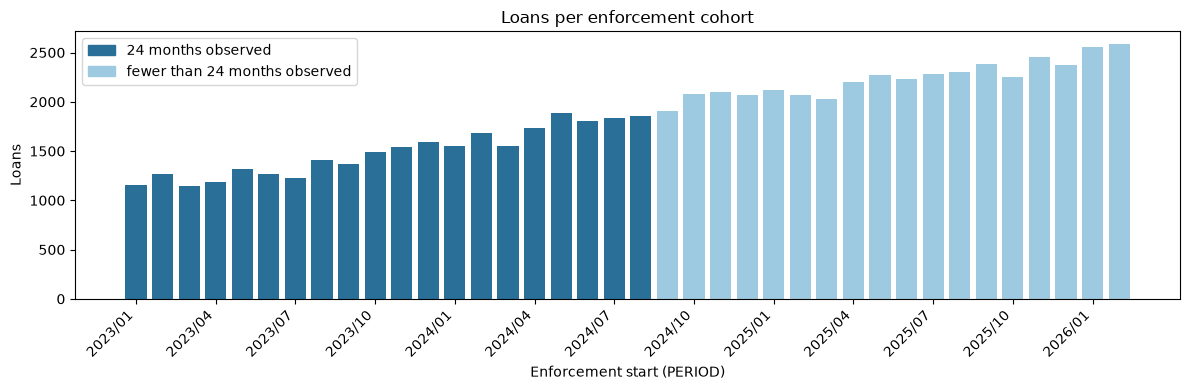

client-periods with complete 24 months: 12,697 (42.7%)
client-periods with fewer than 24 months: 17,066 (57.3%)
loans with complete 24 months: 29,886 (42.6%)
loans with fewer than 24 months: 40,287 (57.4%)


In [25]:
def plot_cohorts(rec: pd.DataFrame) -> None:
    """Loans per enforcement start month, split into cohorts with 24 months of history and younger ones."""
    cohorts = (rec.groupby("PERIOD")
                  .agg(loans=("LOAN_KEY", "size"),
                       client_periods=("CLIENT_KEY", "nunique"),
                       months_observed=("MONTHS_OBSERVED", "min")))
    full = cohorts["months_observed"] == 24
    full_color, partial_color = "#2A6F97", "#9ECAE1"

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(cohorts.index, cohorts["loans"], color=np.where(full, full_color, partial_color))
    ax.set_xticks(range(0, len(cohorts), 3))
    ax.set_xticklabels(cohorts.index[::3], rotation=45, ha="right")
    ax.set_xlabel("Enforcement start (PERIOD)")
    ax.set_ylabel("Loans")
    ax.set_title("Loans per enforcement cohort")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=full_color),
                       plt.Rectangle((0, 0), 1, 1, color=partial_color)],
              labels=["24 months observed", "fewer than 24 months observed"], loc="upper left")
    plt.tight_layout()
    plt.show()

    for unit in ["client_periods", "loans"]:
        total = cohorts[unit].sum()
        complete, incomplete = cohorts.loc[full, unit].sum(), cohorts.loc[~full, unit].sum()
        name = unit.replace("_", "-")
        print(f"{name} with complete 24 months: {complete:,} ({complete / total:.1%})")
        print(f"{name} with fewer than 24 months: {incomplete:,} ({incomplete / total:.1%})")


plot_cohorts(recovery)

By the length of the observation period, we have the full 24-month history for 42.7% of the cases, while for the remaining 57.3% the observation starts from 6 months and does not cover the full 24 months.

Since the share of cases with incomplete observation is high, simply excluding them would cause a significant loss of data. So we need to find out how stable the dynamics of recovery accumulation are over time and whether the final 24-month outcome can be reliably estimated for partially observed clients.

## 2. Building the target variable

Here the loan-level data is aggregated to the client-period level, the recovery curve is built, the 24-month outcome is estimated for partially observed cases, and the court cost and the net financial result are calculated.

In [26]:
def aggregate_client_period(rec: pd.DataFrame) -> pd.DataFrame:
    """One row per (client, period): loan/secured counts, total outstanding, and each
    month's paid amount summed across the client's loans, with NaN preserved wherever
    every one of the client's loans is beyond its own observation window."""
    g = rec.groupby(["CLIENT_KEY", "PERIOD"])
    base = g.agg(
        n_loans=("LOAN_KEY", "size"),
        n_secured=("HAS_COLLATERAL", "sum"),
        outstanding=("OUTST_AT_TRIAL", "sum"),
        months_observed=("MONTHS_OBSERVED", "min"),
        months_observed_spread=("MONTHS_OBSERVED", lambda s: s.max() - s.min()),
    )
    return base.join(g[PAY_COLS].sum(min_count=1))


def build_target_base(rec: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Drop loans with non-positive outstanding, aggregate to client-period level and
    keep the all-unsecured population as the modelling scope."""
    cp = aggregate_client_period(rec[rec["OUTST_AT_TRIAL"] > 0])

    assert (cp["months_observed_spread"] == 0).all(), "a client-period must have one MONTHS_OBSERVED value"
    cp = cp.drop(columns="months_observed_spread")

    cp["klass"] = collateral_class(cp["n_secured"], cp["n_loans"])
    cp["paid_observed"] = cp[PAY_COLS].sum(axis=1)

    unsecured = cp[cp["klass"] == "all_unsecured"].drop(columns="klass").copy()
    return cp, unsecured


cp_all, unsecured = build_target_base(recovery)
print(f"client-periods after dropping bad-outstanding loans: {len(cp_all):,}")
print(f"all-unsecured client-periods in scope: {len(unsecured):,}")
print(f"fully observed (24m): {(unsecured['months_observed'] == 24).sum():,}")
print(f"partially observed (<24m): {(unsecured['months_observed'] < 24).sum():,}")

client-periods after dropping bad-outstanding loans: 29,763
all-unsecured client-periods in scope: 23,171
fully observed (24m): 9,897
partially observed (<24m): 13,274


month 3: 0.2177
month 6: 0.4125
month 9: 0.5756
month 12: 0.7139
month 15: 0.8235
month 18: 0.9121
month 21: 0.9707
month 24: 1.0000


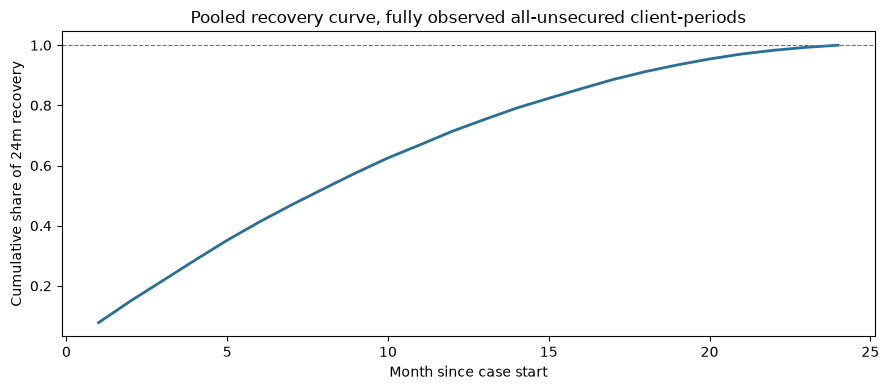

In [27]:
def cohort_curve(cp: pd.DataFrame) -> pd.Series:
    """Pooled cumulative share of the eventual 24-month total reached by each month."""
    monthly = cp.loc[cp["months_observed"] == 24, PAY_COLS].sum(axis=0)
    cum = monthly.cumsum()
    share = cum / cum.iloc[-1]
    share.index = range(1, 25)
    return share


curve = cohort_curve(unsecured)
for m in [3, 6, 9, 12, 15, 18, 21, 24]:
    print(f"month {m}: {curve.loc[m]:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve.index, curve.values, color="#2A6F97", linewidth=2)
ax.axhline(1, color="#6C757D", linewidth=0.8, linestyle="--")
ax.set_xlabel("Month since case start")
ax.set_ylabel("Cumulative share of 24m recovery")
ax.set_title("Pooled recovery curve, fully observed all-unsecured client-periods")
plt.tight_layout()
plt.show()

Recovery starts to accumulate quickly, but it takes a long time to reach the full result: only 41.3% of the final 24-month recovery accumulates in 6 months, 71.4% in 12 months and 91.2% in 18 months.

This means that for cases with a short observation, using only the amount already received would significantly understate recovery, and for partially observed clients the 24-month outcome has to be estimated based on the recovery curve.

In [28]:
def loco_backtest(cp: pd.DataFrame, horizons=(6, 9, 12, 15, 18, 21)) -> pd.DataFrame:
    """Leave-one-cohort-out check: truncate a fully observed cohort at h months, rebuild its
    24-month total with a curve fitted on the other cohorts, and compare with the truth."""
    full = cp[cp["months_observed"] == 24].reset_index()
    cohort_month = full.groupby("PERIOD")[PAY_COLS].sum()
    grand_monthly = cohort_month.sum(axis=0)

    rows = []
    for h in horizons:
        preds, actuals, outst = [], [], []
        for period, cohort_rows in full.groupby("PERIOD"):
            loco_cum = (grand_monthly - cohort_month.loc[period]).cumsum()
            share_at_h = loco_cum.iloc[h - 1] / loco_cum.iloc[-1]
            truncated_paid = cohort_rows[PAY_COLS[:h]].sum(axis=1)
            preds.append((truncated_paid / share_at_h).to_numpy())
            actuals.append(cohort_rows["paid_observed"].to_numpy())
            outst.append(cohort_rows["outstanding"].to_numpy())

        pred, actual, out = np.concatenate(preds), np.concatenate(actuals), np.concatenate(outst)
        pred_rate_raw = pred / out
        pred_rate, actual_rate = np.clip(pred_rate_raw, 0, 1), actual / out
        cost = COST_FIXED + COST_PCT * out
        pred_net, actual_net = pred_rate * out - cost, actual_rate * out - cost

        rows.append({
            "horizon (months)": h, "cases": len(pred),
            "rate MAE": round(np.mean(np.abs(pred_rate - actual_rate)), 4),
            "rate correlation": round(np.corrcoef(pred_rate, actual_rate)[0, 1], 4),
            "profitability flags flipped (%)": round(100 * ((pred_net > 0) != (actual_net > 0)).mean(), 2),
            "cap binds (%)": round(100 * (pred_rate_raw > 1).mean(), 2),
            "refer-all net, predicted": round(pred_net.sum(), 0),
            "refer-all net, actual": round(actual_net.sum(), 0),
        })
    return pd.DataFrame(rows).set_index("horizon (months)")


display(loco_backtest(unsecured))

,cases,rate MAE,rate correlation,profitability flags flipped (%),cap binds (%),"refer-all net, predicted","refer-all net, actual"
horizon (months),,,,,,,
6,9897,0.0157,0.9805,1.22,0.46,-4267753.0,-4234810.0
9,9897,0.0115,0.9892,0.82,0.28,-4242687.0,-4234810.0
12,9897,0.0086,0.9938,0.54,0.17,-4237827.0,-4234810.0
15,9897,0.0065,0.9965,0.43,0.11,-4239214.0,-4234810.0
18,9897,0.0042,0.9985,0.26,0.07,-4236972.0,-4234810.0
21,9897,0.0022,0.9996,0.16,0.00,-4234895.0,-4234810.0


The backtest results show that the error decreases steadily as the observation period grows. At 6 months the MAE of the recovery rate is about 1.6 percentage points and the profitability decision changes in 1.2% of the cases, while at 12 months these numbers are already 0.86 pp and 0.54%.

So we chose 12 months as the minimum threshold for training: at this stage the extrapolation of the target is already stable enough, while using only fully observed cases would cost us a significant part of the data.

An important caveat: the full 24-month outcome of the OOT cohorts observed for 6 to 11 months is not yet known, so their evaluation is also based on an extrapolated label and is not full ground truth. To balance this, Layer C is used separately, where the evaluation relies only on actually observed short-term outcomes, and the final validation should be done with a prospective pilot.

In [29]:
def extrapolate(cp: pd.DataFrame, curve: pd.Series) -> pd.DataFrame:
    """24-month recovery: the observed value if fully observed, else observed-so-far
    divided by the curve's share at that horizon, with the rate capped at 1."""
    cp = cp.copy()
    share_at_horizon = cp["months_observed"].map(curve)
    cp["paid_24m_est"] = np.where(cp["months_observed"] == 24, cp["paid_observed"],
                                  cp["paid_observed"] / share_at_horizon)
    rate_uncapped = cp["paid_24m_est"] / cp["outstanding"]
    cp["cap_bound"] = rate_uncapped > 1
    cp["rate"] = rate_uncapped.clip(upper=1.0)
    cp["paid_24m_est"] = cp["rate"] * cp["outstanding"]
    return cp


target = extrapolate(unsecured, curve)
print(f"cap binds: {target['cap_bound'].sum()} of {len(target):,} ({target['cap_bound'].mean():.2%})")

cap binds: 14 of 23,171 (0.06%)


The recovery rate is capped at a maximum of 1.0, because the amount recovered from a client cannot exceed the client's total outstanding. This cap is active in only 0.06% of the cases, so the effect on the results is negligible.

In [30]:
target["cost"] = COST_FIXED + COST_PCT * target["outstanding"]
target["cost_per_loan"] = COST_FIXED * target["n_loans"] + COST_PCT * target["outstanding"]
target["net"] = target["rate"] * target["outstanding"] - target["cost"]
target["profitable"] = target["net"] > 0

print(f"profitable share: {target['profitable'].mean():.1%}")
print(f"refer-all net (GEL): {target['net'].sum():,.0f}")
print(f"oracle net (GEL): {target.loc[target['profitable'], 'net'].sum():,.0f}")

per_loan_net = target["rate"] * target["outstanding"] - target["cost_per_loan"]
print(f"per-loan-cost sensitivity: profitable share {(per_loan_net > 0).mean():.1%}, refer-all net {per_loan_net.sum():,.0f}")

profitable share: 15.9%
refer-all net (GEL): -11,187,960
oracle net (GEL): 10,773,204
per-loan-cost sensitivity: profitable share 12.1%, refer-all net -26,947,960


Looking at the full in-scope population, only 15.9% of the client-periods are financially profitable. If all cases are referred to court, the total net result is -11.19 million GEL, while with ideal selection the maximum possible net result reaches +10.77 million GEL. This difference clearly shows that the main business value comes not from predicting recovery, but from selecting the right cases.

Under a stricter court cost scenario, where the fixed cost of 500 GEL is counted per loan and not per client-period, the share of profitable cases goes down to 12.1%, and the refer-all result gets worse, down to -26.95 million GEL. This is expected, because 74.4% of the client-periods have two or more loans and the per-loan assumption multiplies the fixed cost several times for most clients.

,"paid GEL, fully observed (24m)"
count,9897.00
mean,814.71
std,2830.15
min,0.00
50%,0.00
75%,282.51
90%,2364.94
99%,11992.18
max,117016.66
skew,12.95


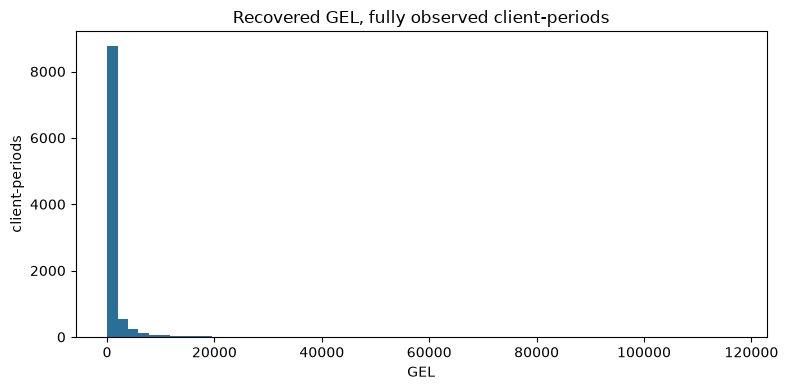

In [31]:
def recovery_shape(paid: pd.Series) -> pd.DataFrame:
    """Distribution of 24m recovered GEL, fully observed client-periods only."""
    stats = paid.describe(percentiles=[.5, .75, .9, .99])
    stats["skew"] = paid.skew()
    return stats.to_frame("paid GEL, fully observed (24m)")


paid_full = unsecured.loc[unsecured["months_observed"] == 24, "paid_observed"]
display(recovery_shape(paid_full).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(paid_full, bins=60, color="#2A6F97")
ax.set_title("Recovered GEL, fully observed client-periods")
ax.set_xlabel("GEL")
ax.set_ylabel("client-periods")
plt.tight_layout()
plt.show()

### Defining the target variable

We build the recovery **rate** instead of the GEL amount, because recovery is very heavy-tailed and full of zeros.

More than half (13,274) of the client-periods do not yet have the full 24-month outcome, so using paid_observed directly would be wrong. Instead, for each row the scheme uses as many months as really exist and fills the missing part with the curve. Otherwise the model would learn which features predict early payment, and not which features predict the overall 24-month value.

So for training we take the client-periods with **12 months or more** of observation (18,341, or 79%), and we keep those observed for 6 to 11 months (4,830, or 21%) as the out-of-time test.

In [32]:
target_train = target[target["months_observed"] >= 12].copy()

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
target.to_csv(PROCESSED_DIR / "target_client_period.csv")
curve.rename("cumulative_share").to_csv(PROCESSED_DIR / "recovery_curve.csv", index_label="month")

## 3. Feature analysis

### Data leakage

Based on the meaning of the variables and the time at which they are recorded, three features stand out whose use in modelling would cause data leakage:

`feature_045` is available during the 12 months following the start of the court process;

`feature_018` is recorded at the moment enforcement starts;

`feature_027` is recorded at the moment enforcement starts.

These variables have to be excluded from modelling, because our goal is to make the decision before the court process starts, while this information becomes available either right after the decision or in the period after the court process has already started.

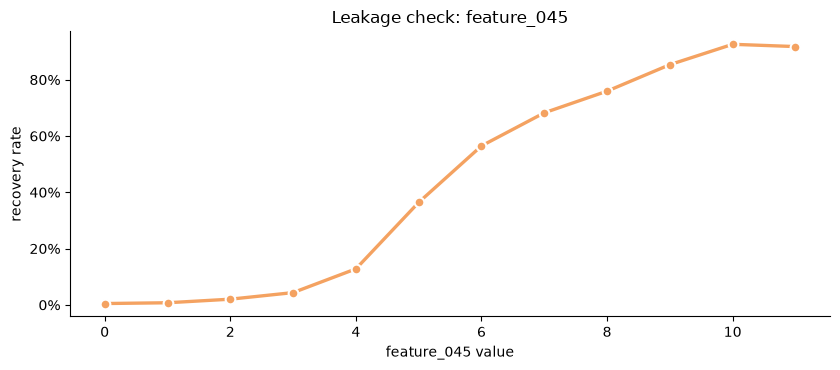

In [33]:
full_obs = unsecured[unsecured["months_observed"] == 24]


def pooled_rate_by_value(col: str) -> pd.Series:
    """Pooled recovery rate per feature value (sum paid / sum outstanding), fully observed rows only."""
    labels = (full_obs.reset_index()[["CLIENT_KEY", "PERIOD", "paid_observed", "outstanding"]]
                      .rename(columns={"CLIENT_KEY": "client_key"}))
    merged = features[["client_key", "PERIOD", col]].merge(labels, on=["client_key", "PERIOD"])
    g = merged.groupby(col)
    return g["paid_observed"].sum() / g["outstanding"].sum()


leak_045 = pooled_rate_by_value("feature_045")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(leak_045.index, leak_045.values, marker="o", ms=7, color="#F4A261", lw=2.4,
        markeredgecolor="white", markeredgewidth=1.5)
ax.set_xlabel("feature_045 value")
ax.set_ylabel("recovery rate")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("Leakage check: feature_045")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [34]:
in_scope_keys = unsecured.reset_index()[["CLIENT_KEY", "PERIOD"]].rename(columns={"CLIENT_KEY": "client_key"})
feat_scope = features.merge(in_scope_keys, on=["client_key", "PERIOD"])


def missingness_table(feat: pd.DataFrame, cols: list[str], fd: pd.DataFrame) -> pd.DataFrame:
    """Share of missing values per feature, with its dictionary entry."""
    miss = feat[cols].isna().mean()
    miss = miss[miss > 0].sort_values(ascending=False)
    return miss.to_frame("missing_share").join(fd.set_index("column")[["group", "unit", "description"]])


miss_table = missingness_table(feat_scope, FEATURE_COLS, feat_dict)
print(f"features with any missing value: {len(miss_table)} of {len(FEATURE_COLS)}")
display(miss_table.round(4))

features with any missing value: 2 of 50


,missing_share,group,unit,description
feature_011,0.8611,account balances,GEL,Average end-of-month savings and deposit balan...
feature_039,0.3069,declared income,GEL,Declared monthly income stated at the client's...


Missing values appear in only two features. `feature_011` is 86.1% missing and reflects the average balance on savings or deposit accounts, so it is filled only for the clients who have such a product. `feature_039` is 30.7% missing and reflects the declared income recorded in the latest credit application.

In both cases the missing value has a natural business explanation and does not look much like randomly lost data. So missingness may itself contain predictive information: for example, not having a deposit may point to a different financial profile of the client.

In [35]:
def missing_vs_target(df_target: pd.DataFrame, feat: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Missing vs non-missing comparison against the target."""
    df = (df_target.reset_index().rename(columns={"CLIENT_KEY": "client_key"})
                   .merge(feat[["client_key", "PERIOD"] + cols], on=["client_key", "PERIOD"]))
    rows = []
    for col in cols:
        for status, g in df.groupby(np.where(df[col].isna(), "missing", "non-missing")):
            rows.append({
                "feature": col, "status": status,
                "pooled_rate": g["paid_24m_est"].sum() / g["outstanding"].sum(),
                "profitable_share": g["profitable"].mean(),
                "net_value": g["net"].mean(),
            })
    return pd.DataFrame(rows).set_index(["feature", "status"])


miss_target = missing_vs_target(target_train, features, miss_table.index.tolist())
display(miss_target.style.format({"pooled_rate": "{:.1%}", "profitable_share": "{:.1%}", "net_value": "{:,.0f}"}))

The analysis was done only on the training rows, because the results of the out-of-time test must not influence the modelling decisions. Otherwise the test would no longer be independent and the results would improve artificially.

In [36]:
def value_overview(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Non-null count, distinct value count, and share of zeros per feature."""
    rows = [{"feature": c, "non_null": df[c].notna().sum(), "n_unique": df[c].nunique(),
             "zero_share": df[c].eq(0).sum() / df[c].notna().sum()} for c in cols]
    return pd.DataFrame(rows).set_index("feature").sort_values("n_unique")


overview = value_overview(feat_scope, FEATURE_COLS)
display(overview.head(20).round(4))

categorical_cols = overview.index[overview["n_unique"] == 2].tolist()
constant_cols = overview.index[overview["n_unique"] <= 1].tolist()
continuous_cols = [c for c in FEATURE_COLS if c not in categorical_cols + constant_cols]

print(f"categorical (n_unique == 2): {categorical_cols}")
print(f"constant (excluded from both): {constant_cols}")
print(f"continuous/count, kept for distribution plots: {len(continuous_cols)} features")

,non_null,n_unique,zero_share
feature,,,
feature_050,23171,1,0.0000
feature_027,23171,2,0.7244
feature_042,23171,2,0.7373
feature_030,23171,2,0.9959
feature_049,23171,2,0.5767
feature_033,23171,9,0.6628
feature_024,23171,9,0.6086
feature_017,23171,9,0.6628
feature_038,23171,11,0.3318


categorical (n_unique == 2): ['feature_027', 'feature_042', 'feature_030', 'feature_049']
constant (excluded from both): ['feature_050']
continuous/count, kept for distribution plots: 45 features


`feature_050` turned out to be constant, so using it in modelling makes no sense and we remove the variable.

feature_001
Mean: 2.11
Std Dev: 2.18
Min: 0
Q1: 0.0
Median: 2.0
Q3: 3.0
Max: 18


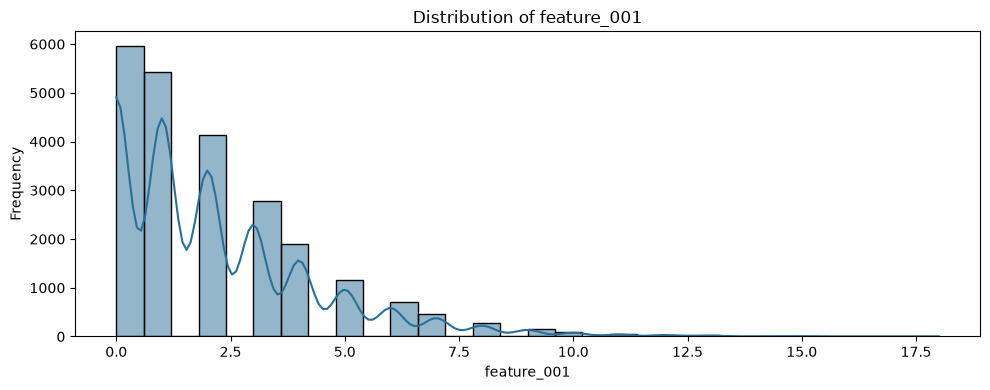



feature_002
Mean: 4.97
Std Dev: 3.38
Min: 0
Q1: 2.0
Median: 4.0
Q3: 7.0
Max: 32


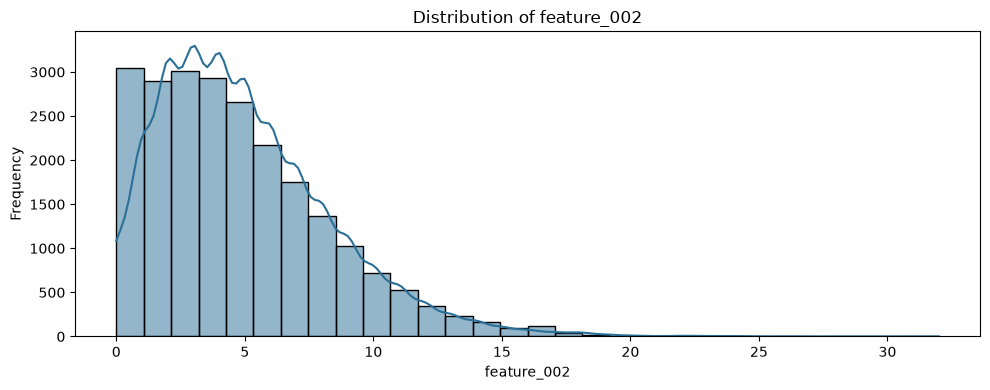



feature_003
Mean: 294.71
Std Dev: 410.21
Min: 2.41
Q1: 83.88
Median: 167.84
Q3: 346.45
Max: 8548.12


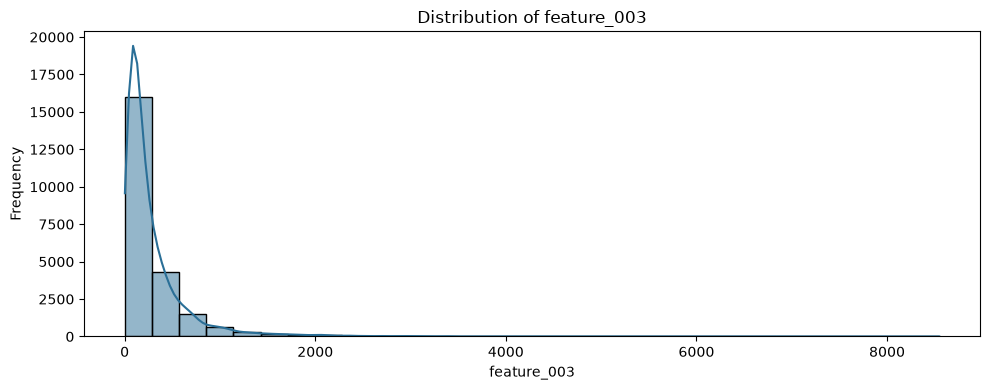



feature_004
Mean: 3582.67
Std Dev: 8346.2
Min: 3.66
Q1: 539.88
Median: 1389.16
Q3: 3469.38
Max: 265437.76


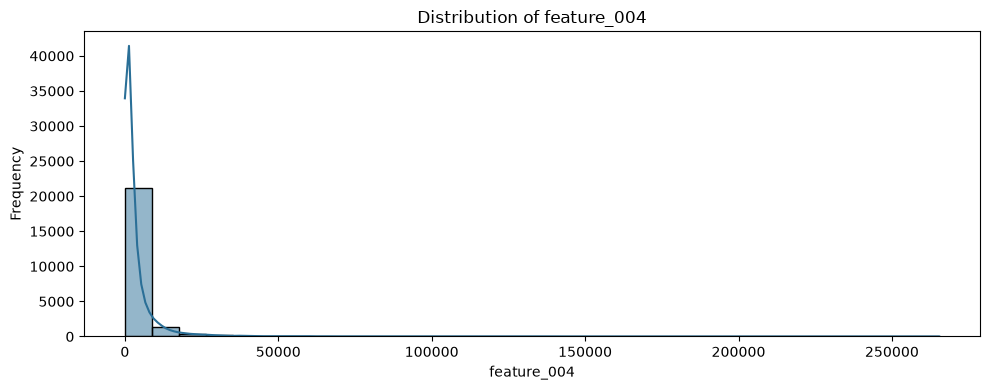



feature_005
Mean: 2.05
Std Dev: 1.73
Min: 0
Q1: 1.0
Median: 2.0
Q3: 3.0
Max: 13


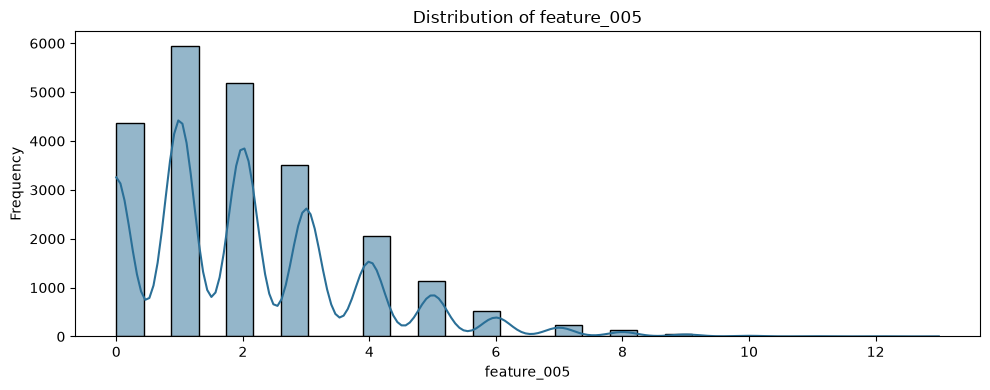



feature_006
Mean: 0.35
Std Dev: 0.19
Min: 0.0
Q1: 0.19
Median: 0.33
Q3: 0.49
Max: 0.97


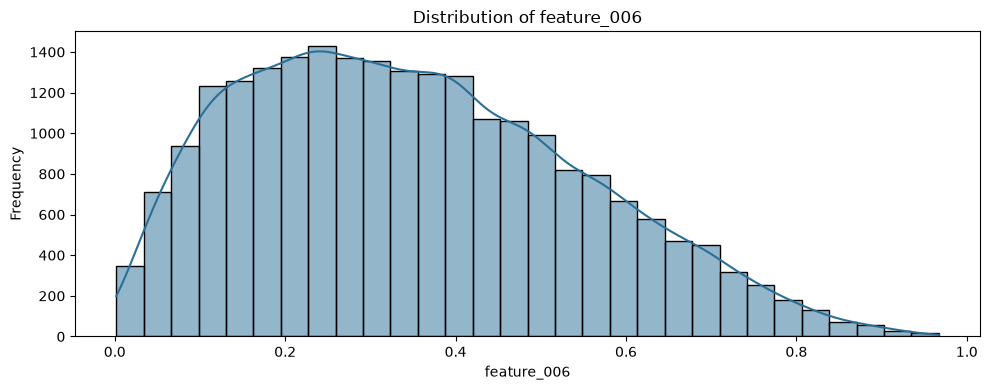



feature_007
Mean: 102.62
Std Dev: 132.22
Min: 1.04
Q1: 32.25
Median: 62.55
Q3: 121.85
Max: 3701.3


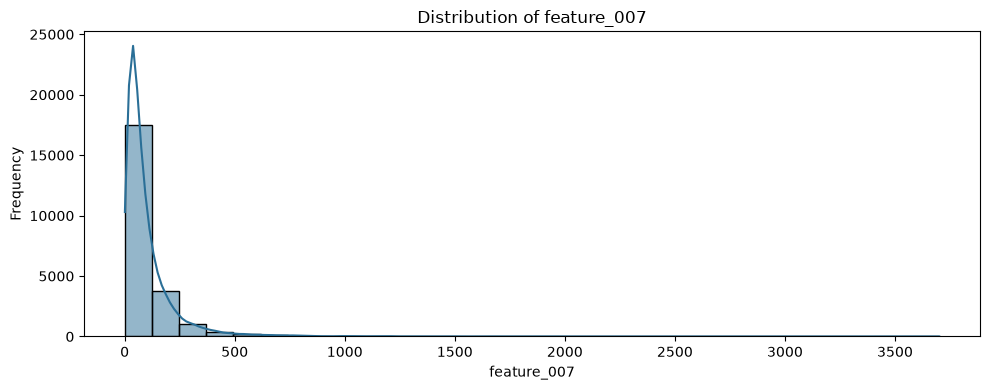



feature_008
Mean: 1.33
Std Dev: 1.37
Min: 0
Q1: 0.0
Median: 1.0
Q3: 2.0
Max: 11


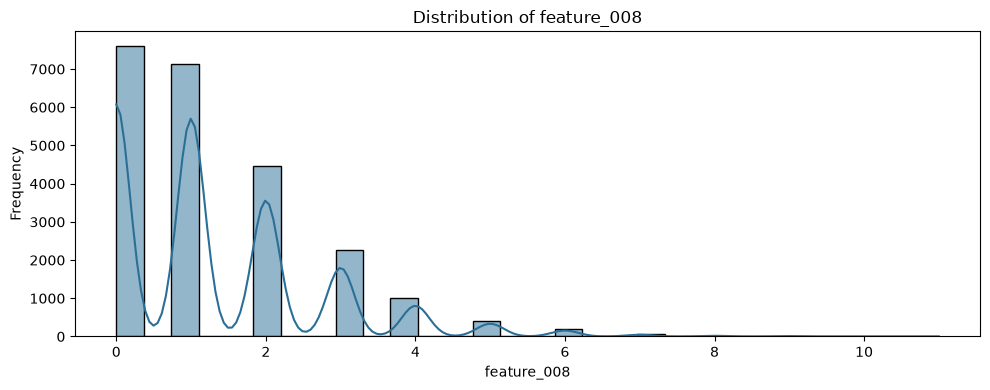



feature_009
Mean: 20.17
Std Dev: 10.45
Min: 0
Q1: 13.0
Median: 19.0
Q3: 26.0
Max: 94


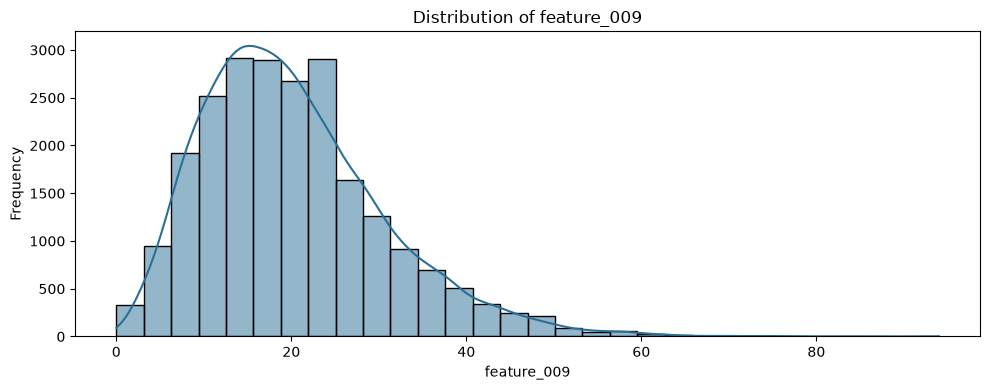



feature_010
Mean: 3008.81
Std Dev: 5200.54
Min: 16.47
Q1: 677.3
Median: 1479.49
Q3: 3300.37
Max: 237984.9


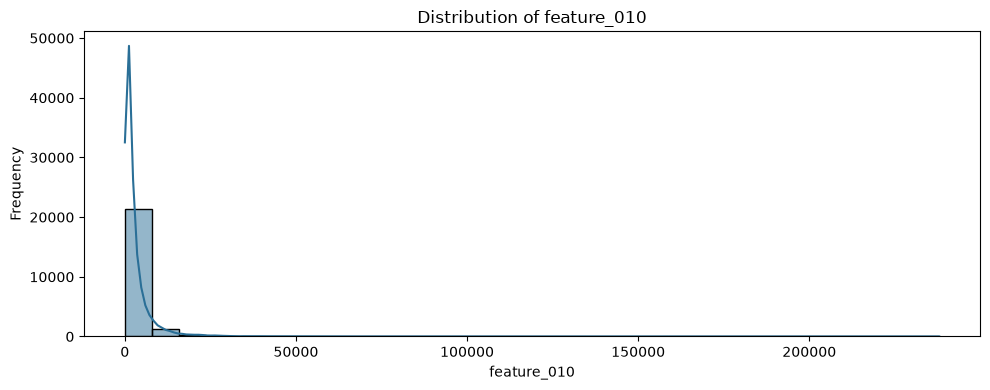



feature_011
Mean: 146.11
Std Dev: 218.83
Min: 5.2
Q1: 54.7
Median: 97.52
Q3: 174.58
Max: 8848.4


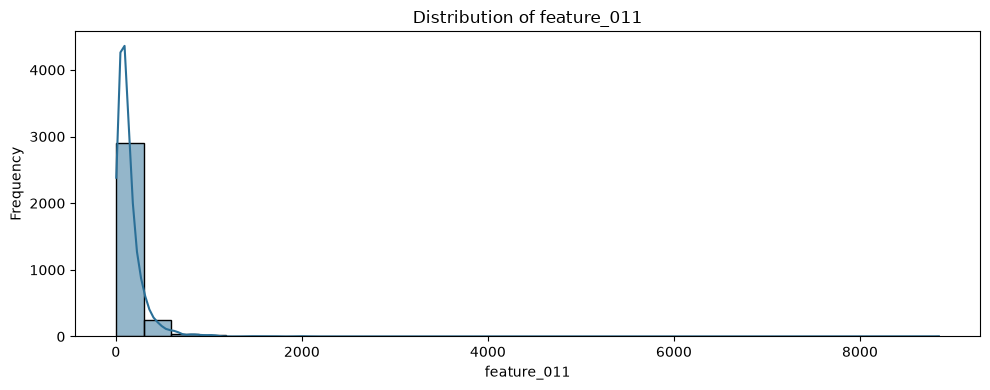



feature_012
Mean: 113.23
Std Dev: 406.7
Min: 0.04
Q1: 10.93
Median: 30.71
Q3: 91.27
Max: 22462.41


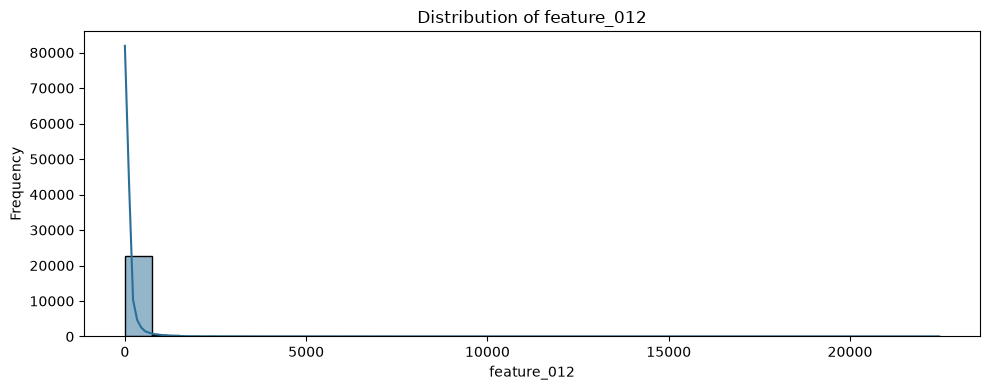



feature_013
Mean: 0.54
Std Dev: 0.18
Min: 0.02
Q1: 0.41
Median: 0.54
Q3: 0.67
Max: 0.99


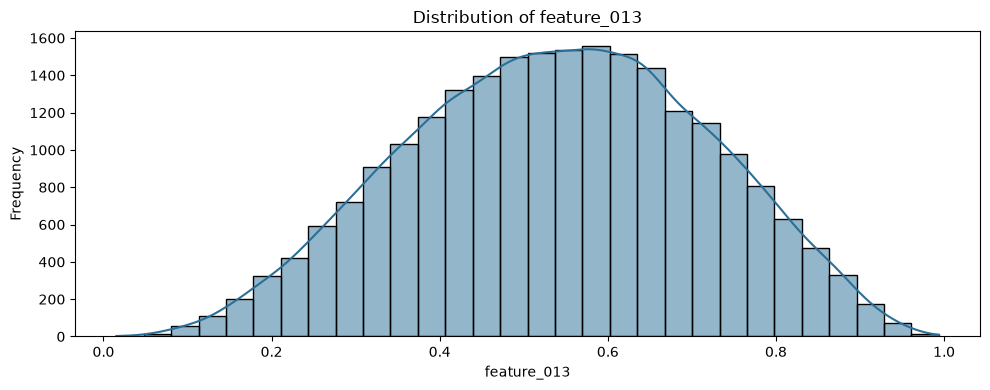



feature_014
Mean: 553.63
Std Dev: 971.01
Min: 2.64
Q1: 130.93
Median: 283.35
Q3: 612.8
Max: 29551.47


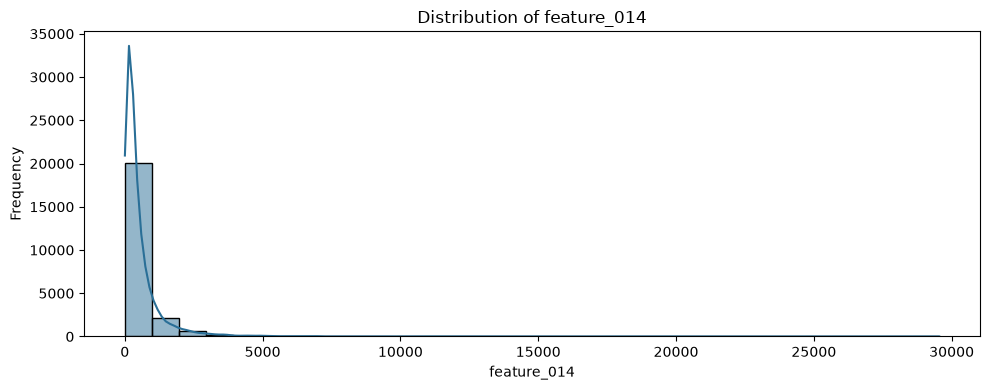



feature_015
Mean: 4718.81
Std Dev: 5050.61
Min: 128.41
Q1: 1817.46
Median: 3253.51
Q3: 5777.64
Max: 113747.69


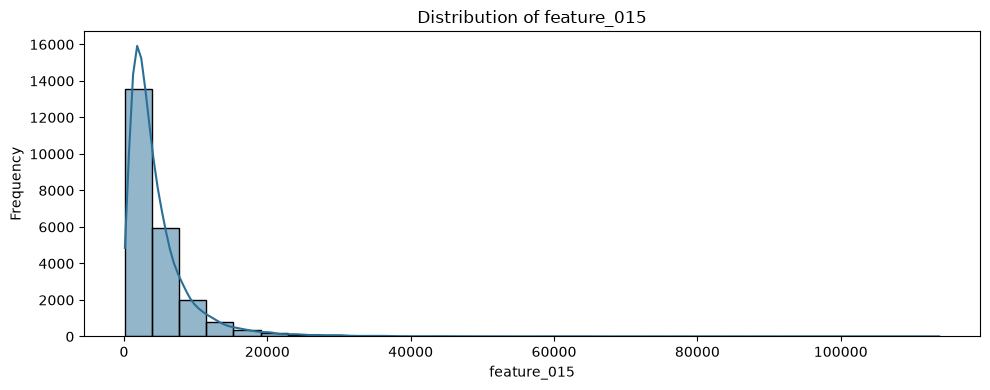



feature_016
Mean: 3608.97
Std Dev: 5173.72
Min: 25.4
Q1: 1032.06
Median: 2113.57
Q3: 4209.04
Max: 157108.77


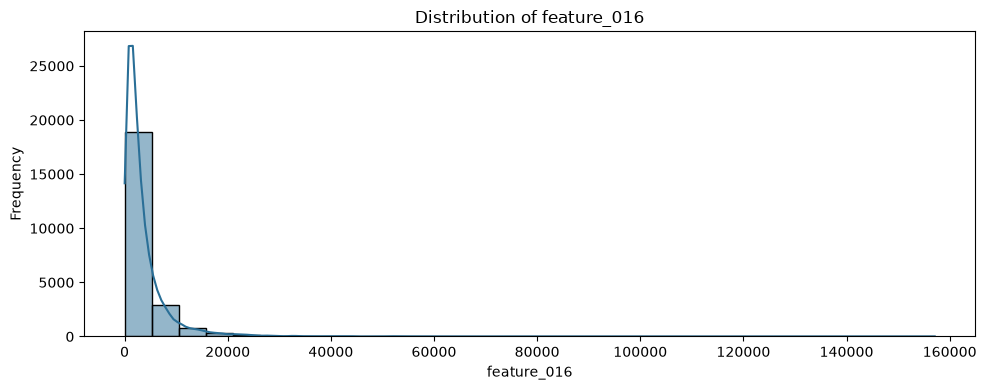



feature_017
Mean: 0.5
Std Dev: 0.85
Min: 0
Q1: 0.0
Median: 0.0
Q3: 1.0
Max: 10


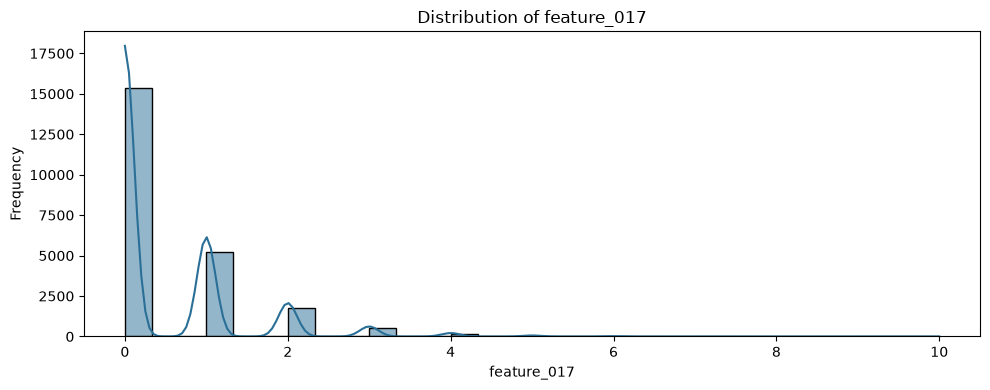



feature_018
Mean: 6.78
Std Dev: 4.16
Min: 0
Q1: 4.0
Median: 6.0
Q3: 9.0
Max: 32


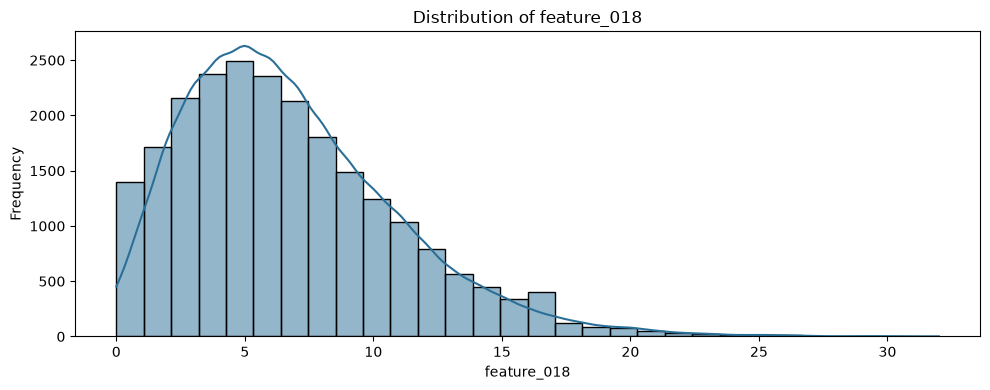



feature_019
Mean: 0.41
Std Dev: 0.15
Min: 0.02
Q1: 0.3
Median: 0.4
Q3: 0.51
Max: 0.92


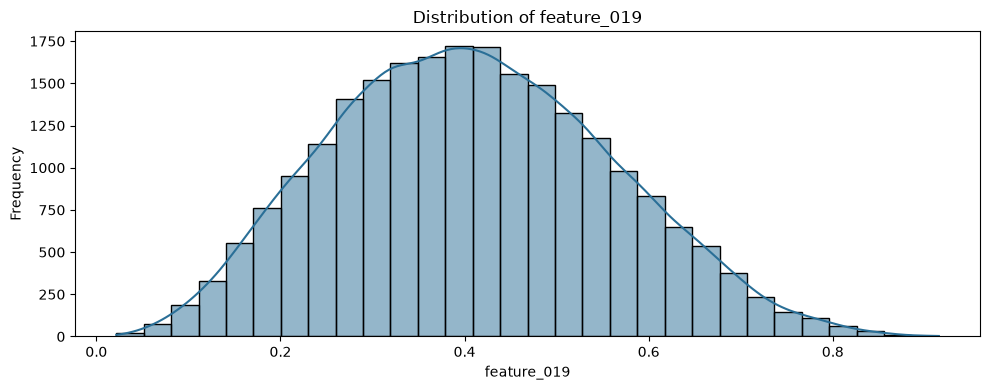



feature_020
Mean: 0.45
Std Dev: 0.19
Min: 0.0
Q1: 0.3
Median: 0.44
Q3: 0.58
Max: 0.99


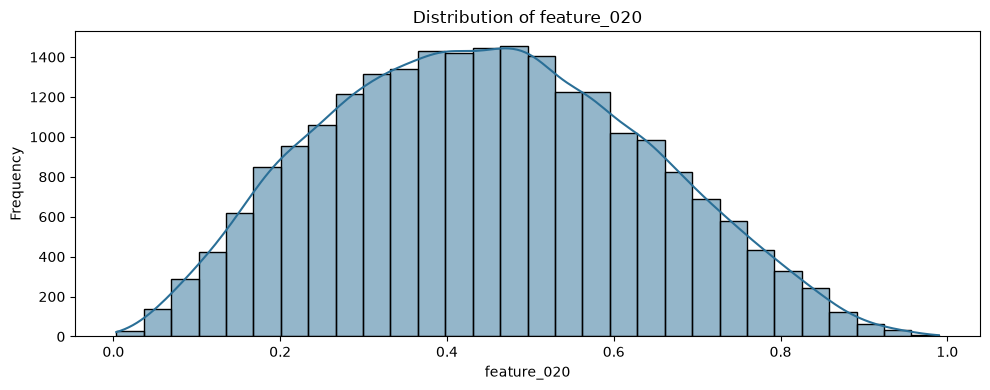



feature_021
Mean: 7.61
Std Dev: 4.8
Min: 0
Q1: 4.0
Median: 7.0
Q3: 10.0
Max: 43


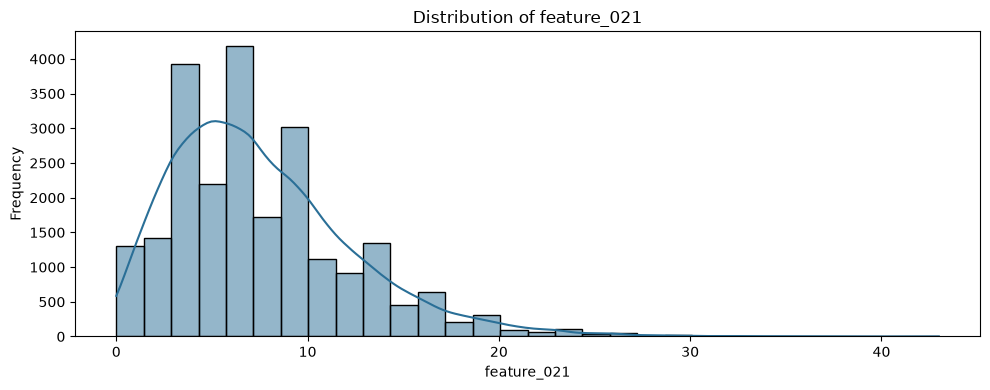



feature_022
Mean: 12.86
Std Dev: 7.82
Min: 0
Q1: 7.0
Median: 11.0
Q3: 17.0
Max: 70


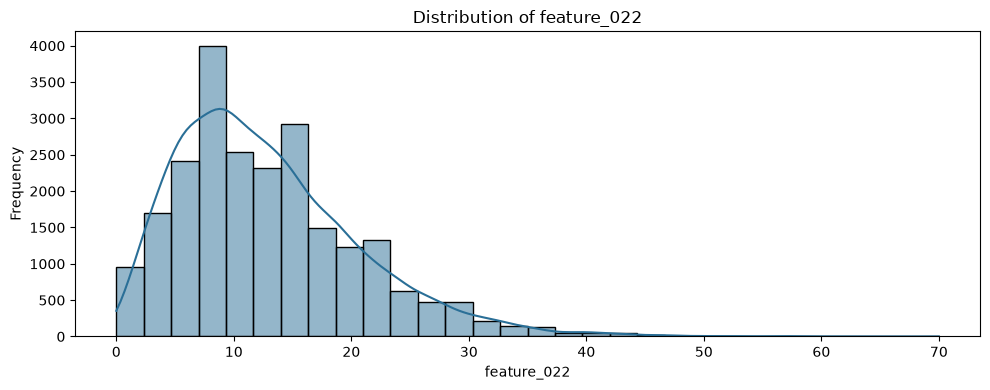



feature_023
Mean: 0.49
Std Dev: 0.17
Min: 0.04
Q1: 0.37
Median: 0.49
Q3: 0.61
Max: 0.97


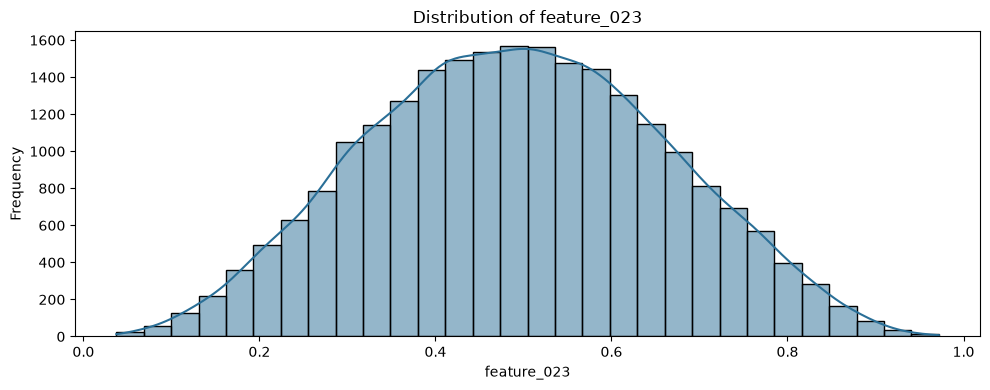



feature_024
Mean: 0.58
Std Dev: 0.9
Min: 0
Q1: 0.0
Median: 0.0
Q3: 1.0
Max: 9


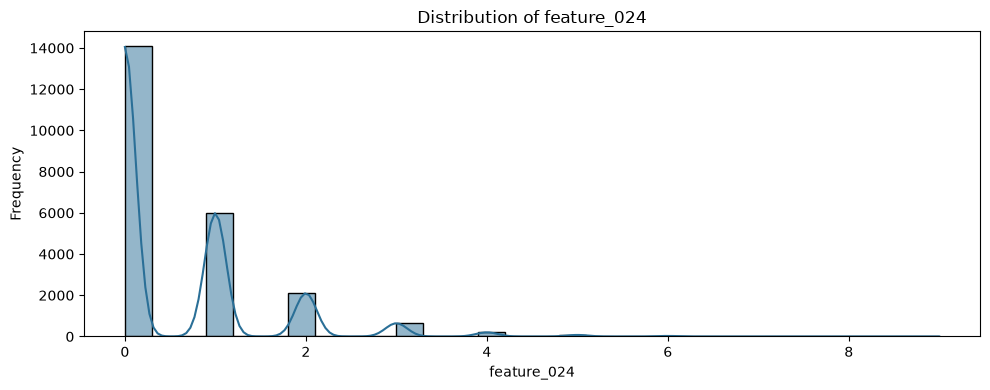



feature_025
Mean: 17.73
Std Dev: 9.39
Min: 0
Q1: 11.0
Median: 16.0
Q3: 23.0
Max: 87


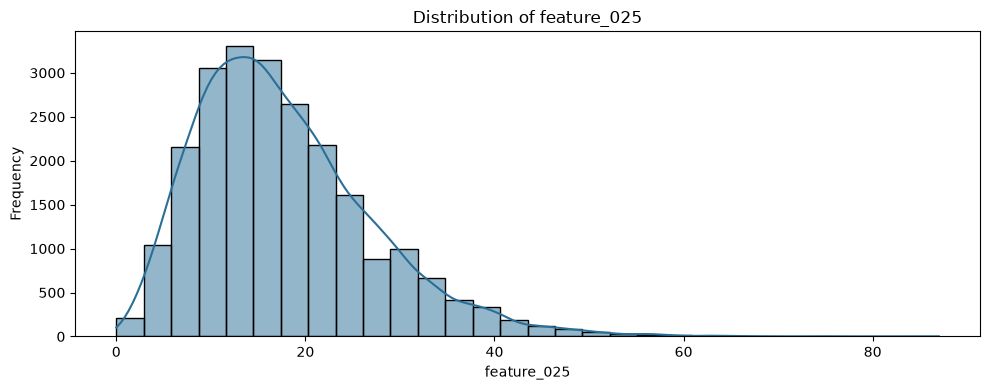



feature_026
Mean: 29.7
Std Dev: 13.84
Min: 1
Q1: 20.0
Median: 28.0
Q3: 38.0
Max: 110


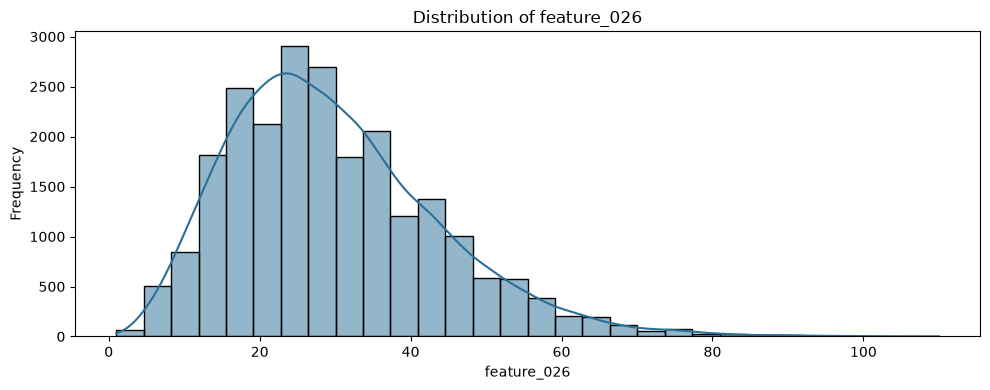



feature_028
Mean: 9.44
Std Dev: 6.52
Min: 0
Q1: 5.0
Median: 8.0
Q3: 13.0
Max: 55


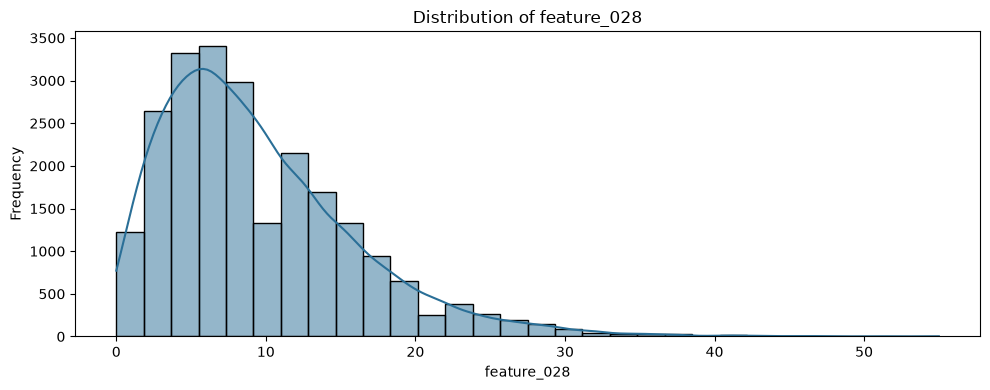



feature_029
Mean: 0.37
Std Dev: 0.17
Min: 0.01
Q1: 0.24
Median: 0.36
Q3: 0.48
Max: 0.95


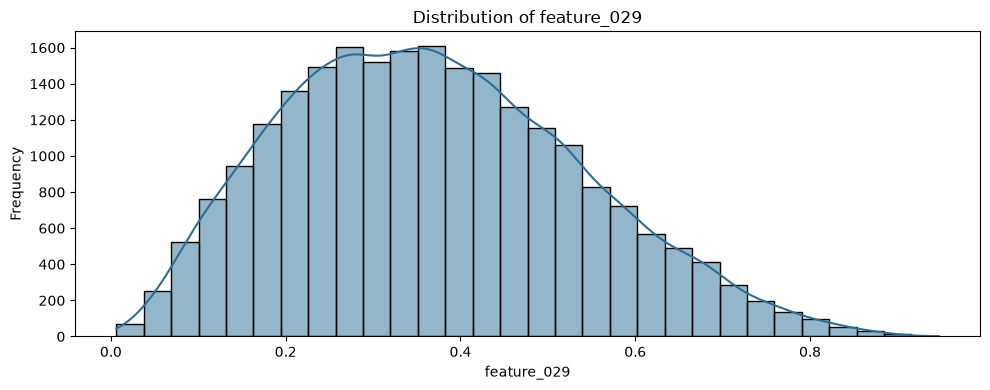



feature_031
Mean: 324.39
Std Dev: 48.0
Min: 117
Q1: 292.0
Median: 324.0
Q3: 357.0
Max: 509


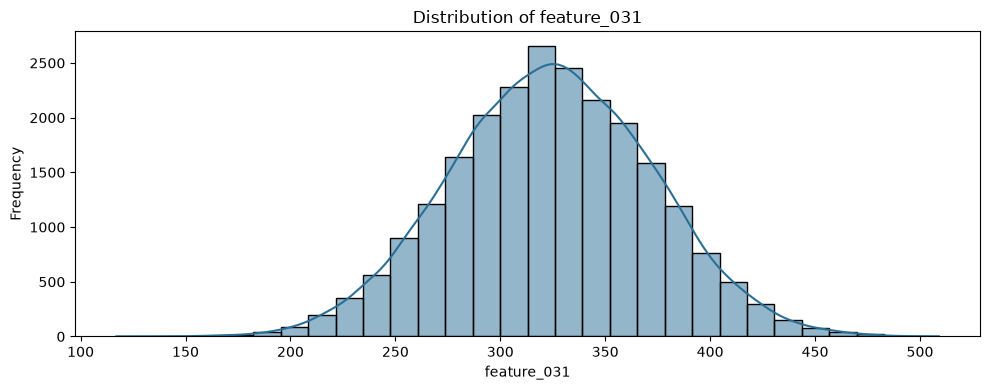



feature_032
Mean: 4.9
Std Dev: 3.09
Min: 0
Q1: 3.0
Median: 4.0
Q3: 7.0
Max: 31


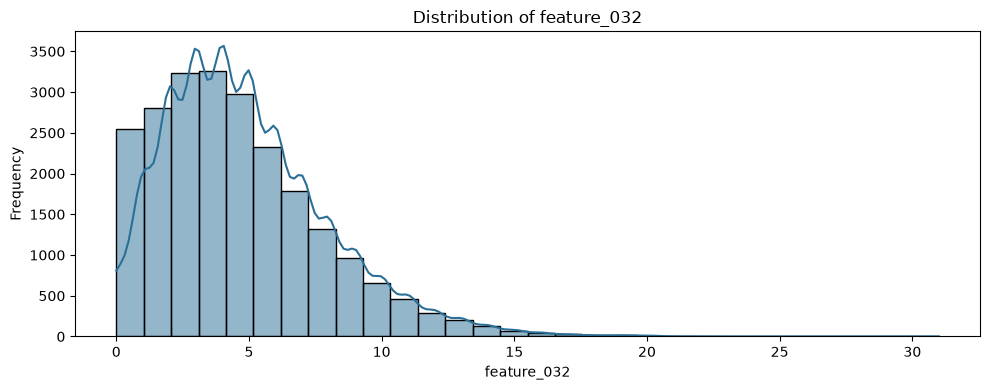



feature_033
Mean: 0.5
Std Dev: 0.85
Min: 0
Q1: 0.0
Median: 0.0
Q3: 1.0
Max: 10


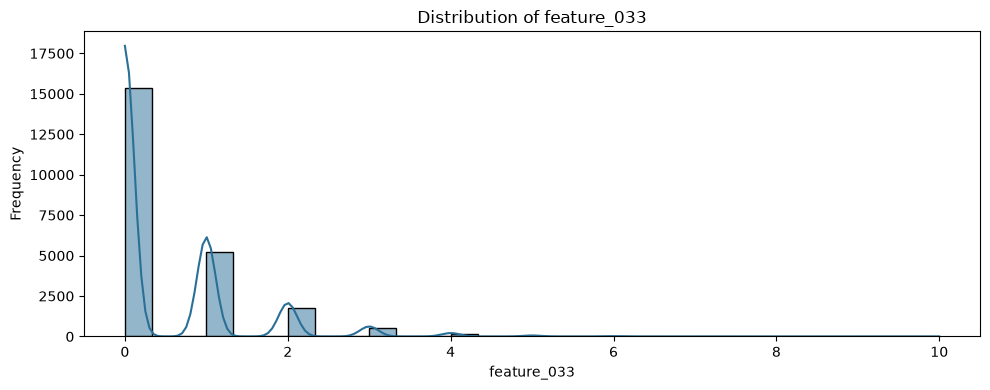



feature_034
Mean: 469.96
Std Dev: 45.16
Min: 279
Q1: 439.0
Median: 470.0
Q3: 500.0
Max: 659


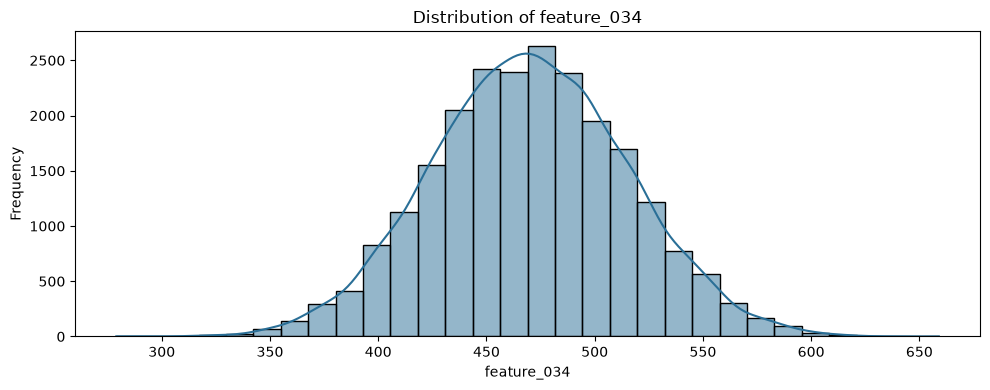



feature_035
Mean: 6.54
Std Dev: 6.16
Min: 0
Q1: 2.0
Median: 5.0
Q3: 9.0
Max: 57


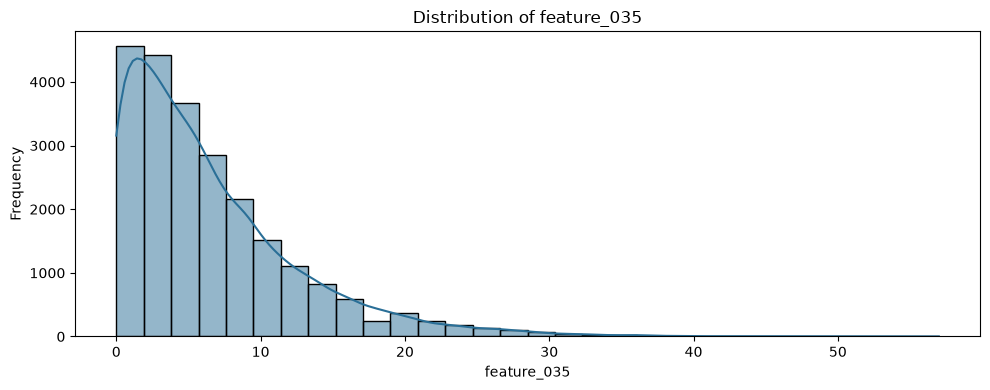



feature_036
Mean: 0.46
Std Dev: 0.16
Min: 0.03
Q1: 0.34
Median: 0.46
Q3: 0.58
Max: 0.95


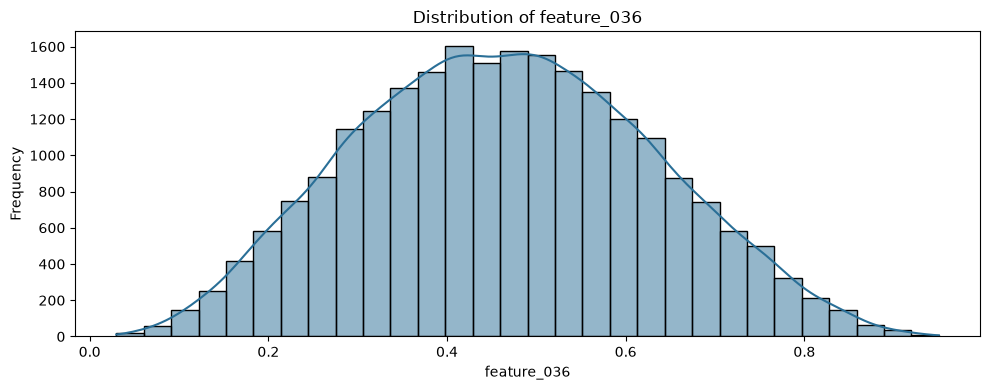



feature_037
Mean: 2.18
Std Dev: 1.86
Min: 0
Q1: 1.0
Median: 2.0
Q3: 3.0
Max: 19


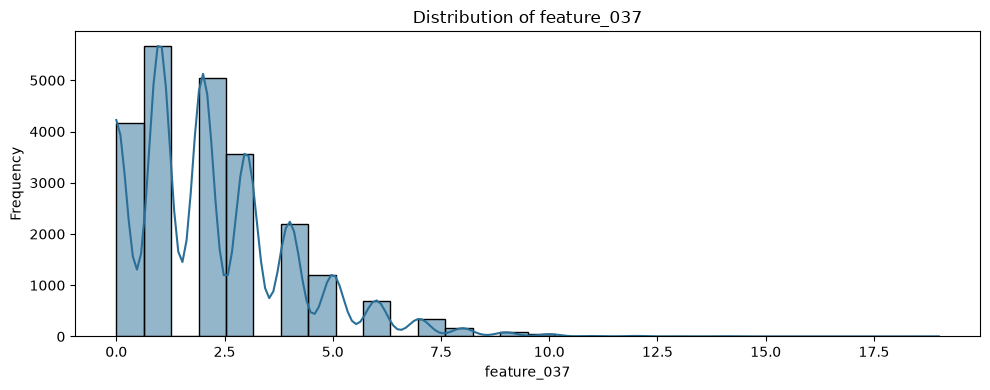



feature_038
Mean: 1.31
Std Dev: 1.35
Min: 0
Q1: 0.0
Median: 1.0
Q3: 2.0
Max: 10


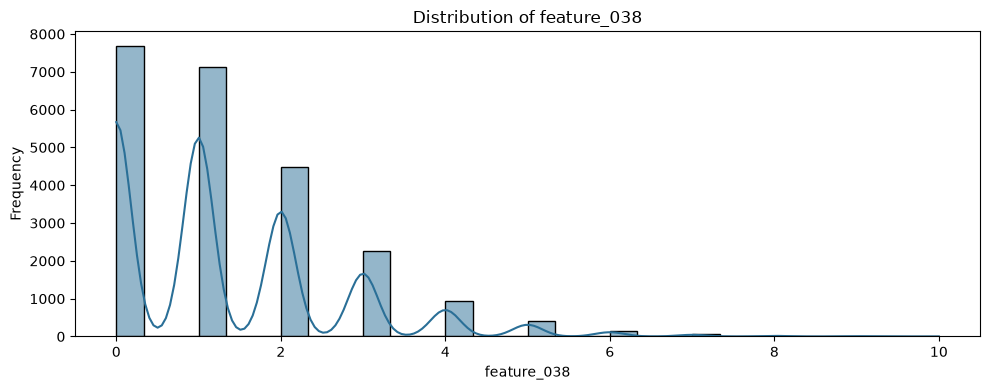



feature_039
Mean: 8944.17
Std Dev: 19679.98
Min: 15.85
Q1: 1367.58
Median: 3518.24
Q3: 8798.04
Max: 619327.81


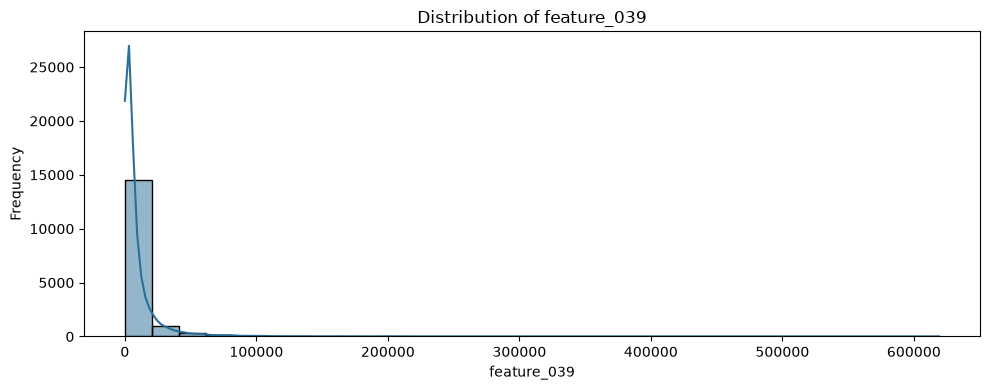



feature_040
Mean: 111.34
Std Dev: 111.51
Min: 2.28
Q1: 44.01
Median: 77.59
Q3: 138.93
Max: 2078.37


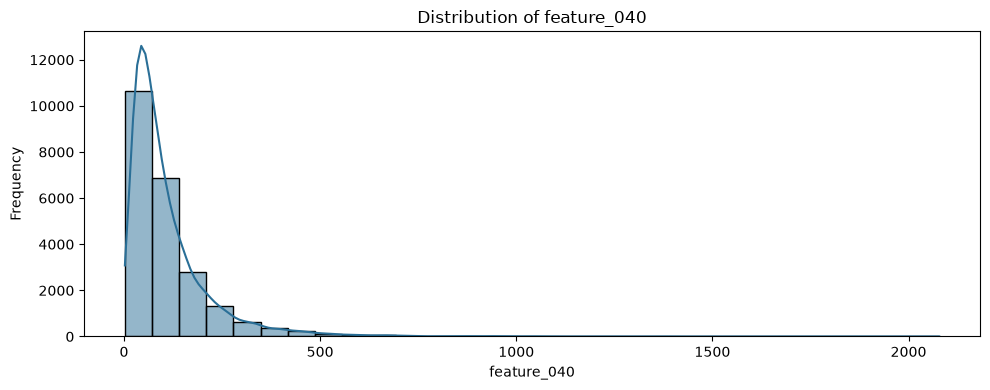



feature_041
Mean: 0.5
Std Dev: 0.17
Min: 0.04
Q1: 0.37
Median: 0.49
Q3: 0.62
Max: 0.97


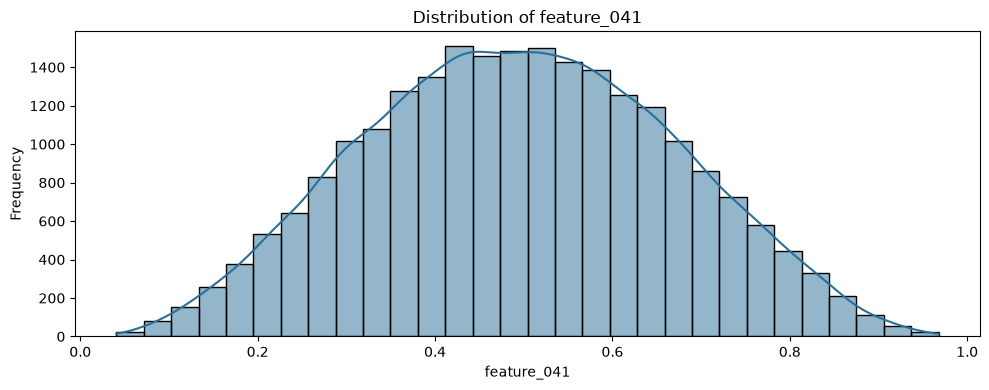



feature_043
Mean: 5.38
Std Dev: 3.62
Min: 0
Q1: 3.0
Median: 5.0
Q3: 7.0
Max: 31


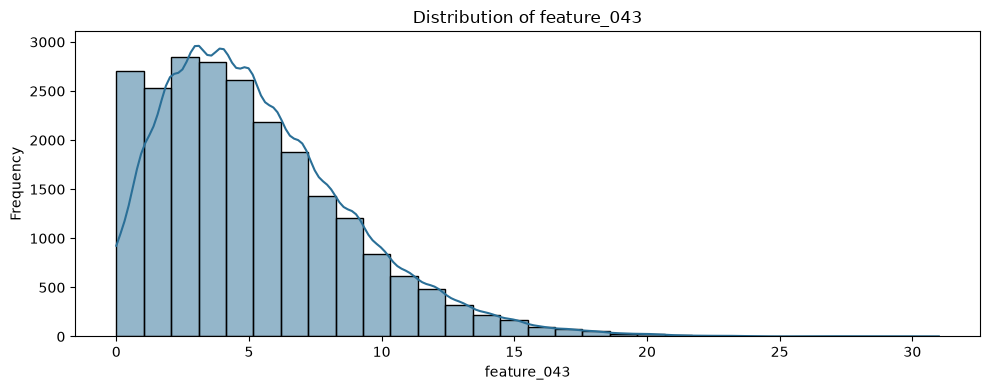



feature_044
Mean: 1.64
Std Dev: 2.09
Min: 0
Q1: 0.0
Median: 1.0
Q3: 2.0
Max: 21


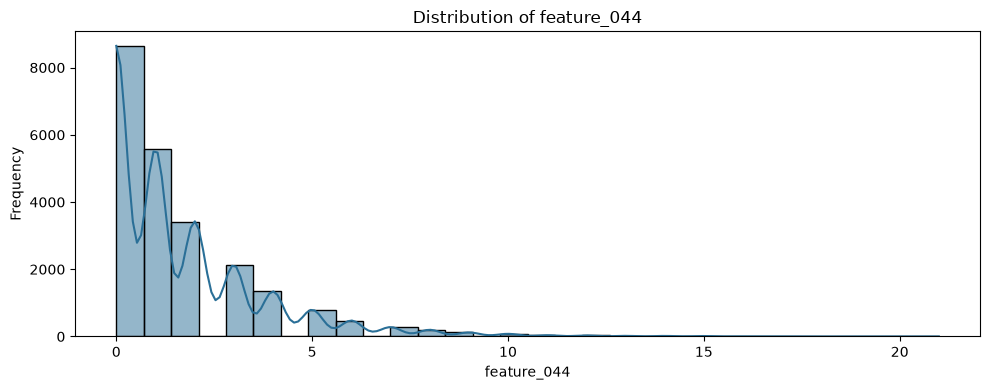



feature_045
Mean: 2.81
Std Dev: 1.65
Min: 0
Q1: 2.0
Median: 3.0
Q3: 4.0
Max: 11


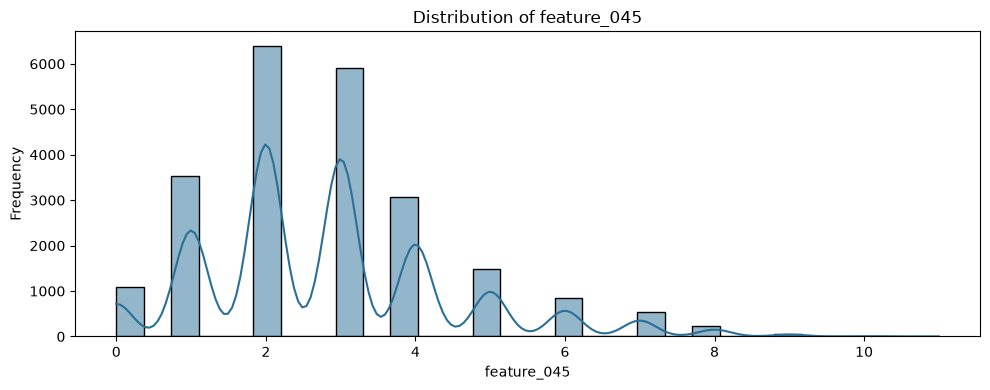



feature_046
Mean: 1.37
Std Dev: 1.55
Min: 0
Q1: 0.0
Median: 1.0
Q3: 2.0
Max: 15


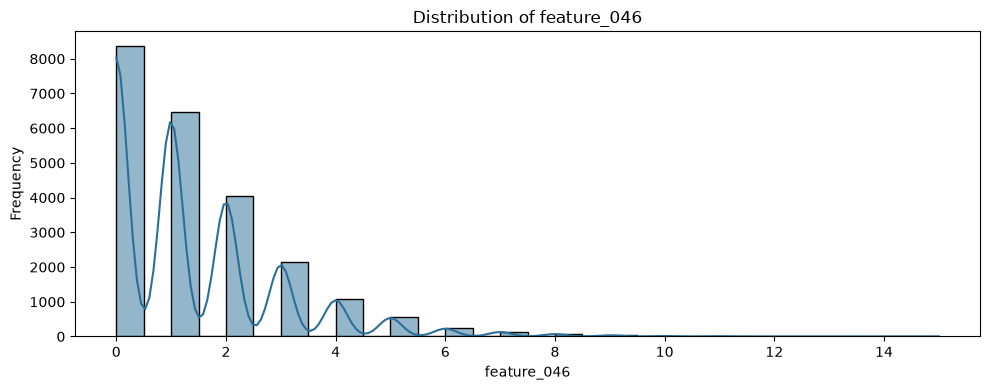



feature_047
Mean: 0.6
Std Dev: 0.2
Min: 0.02
Q1: 0.45
Median: 0.61
Q3: 0.75
Max: 1.0


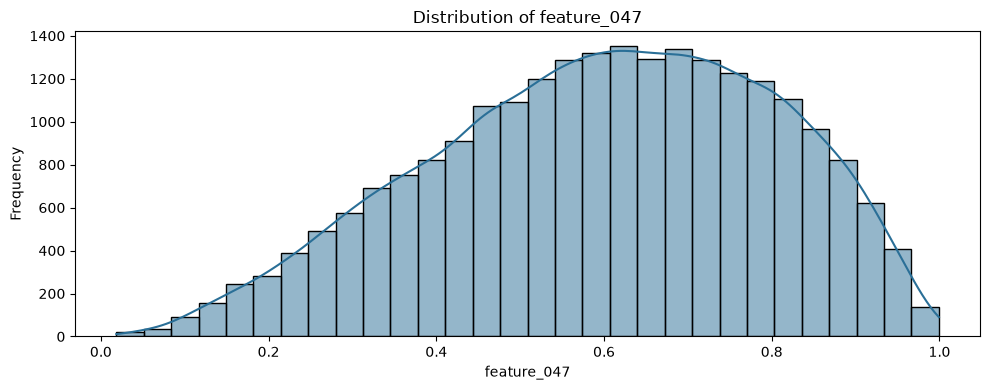



feature_048
Mean: 2.73
Std Dev: 3.05
Min: 0
Q1: 1.0
Median: 2.0
Q3: 4.0
Max: 29


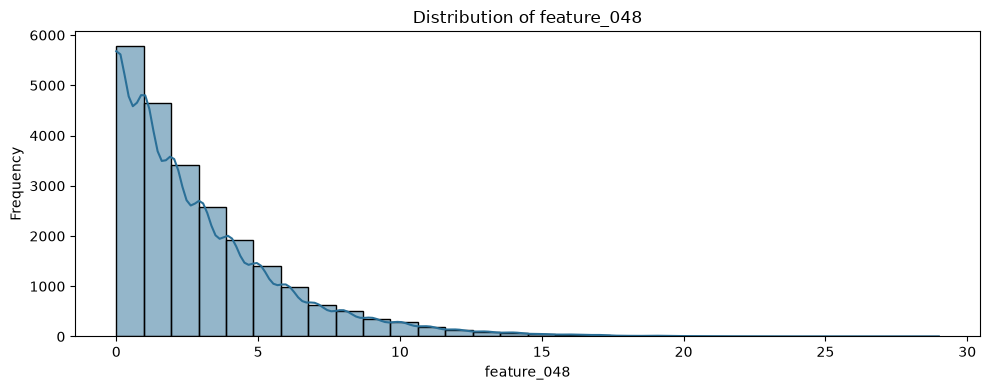

In [37]:
def univariate_report(df: pd.DataFrame, columns: list[str], bins: int = 30, decimals: int = 2) -> None:
    """Summary stats + histogram/KDE for each column, one at a time."""
    for column in columns:
        s = df[column].dropna()
        stats = {"Mean": s.mean(), "Std Dev": s.std(), "Min": s.min(), "Q1": s.quantile(0.25),
                 "Median": s.median(), "Q3": s.quantile(0.75), "Max": s.max()}

        print(column)
        for label, value in stats.items():
            print(f"{label}: {round(value, decimals)}")

        plt.figure(figsize=(10, 4))
        sns.histplot(s, bins=bins, kde=True, color="#2A6F97")
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()
        print("\n")


univariate_report(feat_scope, continuous_cols)

Out of 45 continuous variables, 41 have a right skewed distribution, meaning the mean is higher than the median. The strongest asymmetry is in the account balances, declared income and transaction activity groups, where the skewness is very high in some cases. This points to the presence of outliers and of a small number of very high values.

With this kind of distribution the mean does not always reflect the behavior of the typical client, so the median is a more reliable measure in the descriptive analysis.

feature_027
0: 72.44%
1: 27.56%


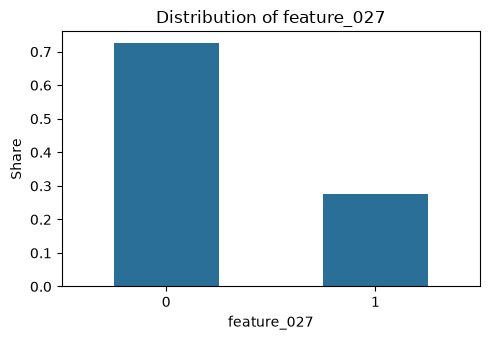



feature_042
0: 73.73%
1: 26.27%


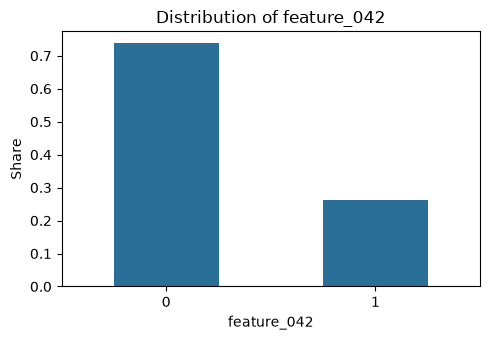



feature_030
0: 99.59%
1: 0.41%


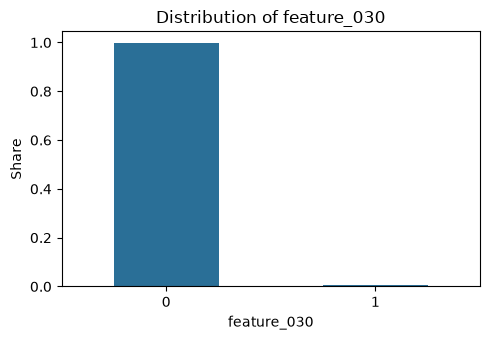



feature_049
0: 57.67%
1: 42.33%


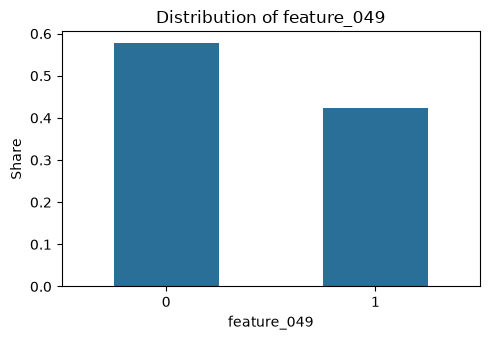

In [38]:
def categorical_report(df: pd.DataFrame, columns: list[str]) -> None:
    """Share table + bar chart for each binary (0/1) feature."""
    for column in columns:
        vc = df[column].value_counts(normalize=True, dropna=False).sort_index()
        print(column)
        for val, share in vc.items():
            print(f"{val}: {share:.2%}")

        plt.figure(figsize=(5, 3.5))
        vc.plot(kind="bar", color="#2A6F97")
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Share")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()
        print("\n")


categorical_report(feat_scope, categorical_cols)

`feature_030` is interesting: about 99.6% of its values are zero and only 0.4% are one. Out of the total 23,171 client-periods a positive value is recorded in only 95 cases. So although the variable is formally not constant, in practice it has very little variability.

In [39]:
def outliers_share(df: pd.DataFrame, decimals: int = 0) -> pd.DataFrame:
    """IQR-rule outlier share per numeric column, split into lower/upper tail counts."""
    rows = []
    for column in df.select_dtypes(include="number").columns:
        q1, q3 = df[column].quantile(0.25), df[column].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        below, above = int((df[column] < lower).sum()), int((df[column] > upper).sum())
        rows.append({
            "Feature": column, "Outlier_Percentage": round(100 * (below + above) / len(df), 2),
            "Lower Bound": round(lower, decimals), "Lower Outliers": below,
            "Upper Bound": round(upper, decimals), "Upper Outliers": above,
        })
    return pd.DataFrame(rows).sort_values("Outlier_Percentage", ascending=False)


display(outliers_share(feat_scope[continuous_cols]))

,Feature,Outlier_Percentage,Lower Bound,Lower Outliers,Upper Bound,Upper Outliers
11,feature_012,11.53,-110.0,0,212.0,2672
3,feature_004,10.44,-3854.0,0,7864.0,2419
9,feature_010,9.16,-3257.0,0,7235.0,2122
13,feature_014,8.64,-592.0,0,1336.0,2002
15,feature_016,7.88,-3733.0,0,8974.0,1827
2,feature_003,7.79,-310.0,0,740.0,1805
6,feature_007,7.73,-102.0,0,256.0,1790
36,feature_039,7.18,-9778.0,0,19944.0,1664
14,feature_015,6.78,-4123.0,0,11718.0,1570
37,feature_040,6.59,-98.0,0,281.0,1527


Given the right skewed distribution of the variables, it is natural that most of the detected outliers are on the upper side. By the IQR method the highest outlier share is in `feature_012`, `feature_004`, `feature_010`, `feature_014` and `feature_016`, which matches the high skewness seen in the same features.

Lower outliers practically do not occur, because GEL and count type variables are naturally non-negative and the lower bound of the IQR often falls into negative values. The exceptions are the credit bureau score type `feature_031` and `feature_034`, where very low values are real and meaningful outliers. For the ratio type variables a 0 percent outlier share does not mean that they have no extreme behavior: their values are in a range that is bounded in advance, so the IQR method is less sensitive on them.

In general, outliers are looked at in two directions. Univariate outliers are observations in one specific variable that differ sharply from the rest of the values, which is exactly what we assessed above with the IQR method. Multivariate outliers are cases that may not be extreme in any single feature, but differ significantly from typical behavior in the combination of several variables. They can be found with methods like Isolation Forest, but the business interpretation of the resulting cases requires a separate and detailed study, so we do not go deeper in this direction within this task.

We chose IQR because it is less sensitive to asymmetric distributions. The mean ± 3σ approach is especially natural in the case of a normal distribution, where about 99.7% of the observations fall into this interval. For any other distribution, Chebyshev's inequality only gives the minimum guarantee that at least 88.89% of the observations fall within 3 standard deviations.

We do not automatically delete records because of outliers. A high balance, income or transaction amount can be a real and economically important client and not a data error. In linear models, high skewness and extreme values need a suitable transformation and scaling, because they can have a significant effect on the coefficients and the residuals. Tree based models are relatively robust to outliers in the independent variables, but extreme values in the target can still significantly affect the loss of the model and the final prediction.

## 4. Analysis of the dependent variable

training client-periods: 18,341
rate
Mean: 0.1045
Std Dev: 0.2114
Min: 0.0
Q1: 0.0
Median: 0.0
Q3: 0.0613
Max: 1.0


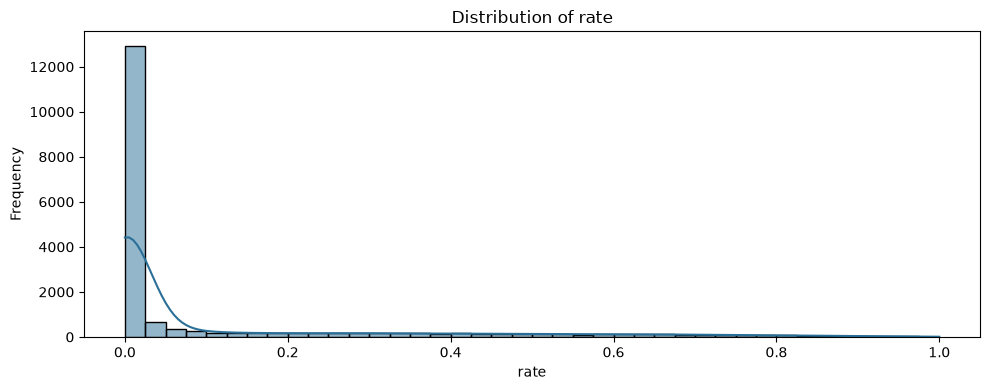



net
Mean: -457.0298
Std Dev: 2524.7084
Min: -16898.219
Q1: -1208.738
Median: -788.0814
Q3: -533.614
Max: 100379.023


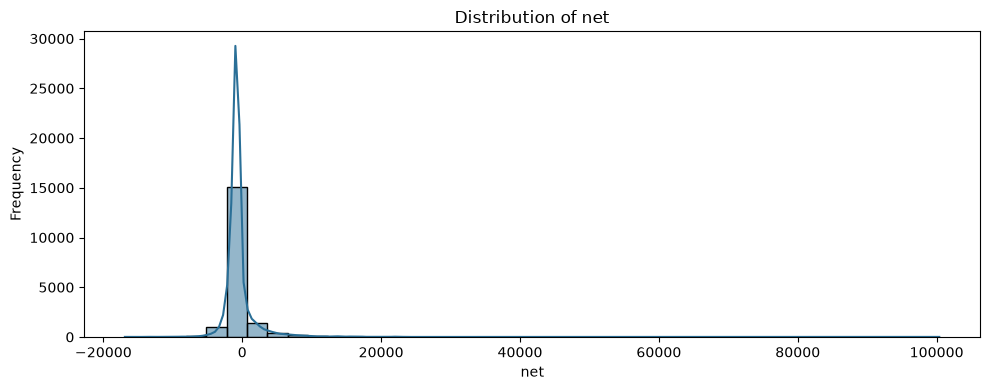



cost
Mean: 1246.0279
Std Dev: 884.1204
Min: 502.519
Q1: 722.786
Median: 989.422
Q3: 1444.046
Max: 18554.279


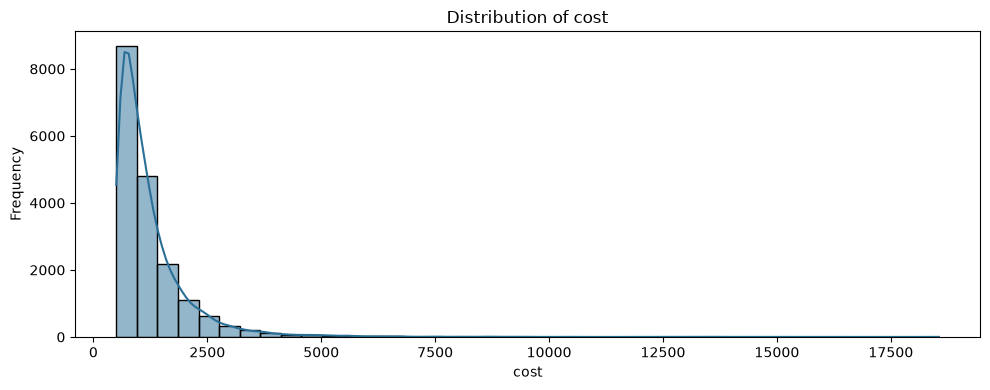

,Feature,Outlier_Percentage,Lower Bound,Lower Outliers,Upper Bound,Upper Outliers
0,rate,20.45,-0.09,0,0.15,3750
1,net,19.14,-2221.42,1161,479.07,2350
2,cost,6.43,-359.10,0,2525.94,1180


profitable
False    0.8371
True     0.1629
Name: proportion, dtype: float64

,actual (24m),extrapolated (12-23m)
mean rate,10.8%,10.0%
median,0.00,0.00
75th percentile,7.4%,5.2%
zero recovery,54.5%,55.2%
profitable,16.8%,15.7%
max,0.98,1.00


In [40]:
print(f"training client-periods: {len(target_train):,}")

univariate_report(target_train, ["rate", "net", "cost"], bins=40, decimals=4)
display(outliers_share(target_train[["rate", "net", "cost"]], decimals=2))
display(target_train["profitable"].value_counts(normalize=True).sort_index().round(4))


def label_comparison(df: pd.DataFrame) -> pd.DataFrame:
    """Actual 24-month outcomes vs extrapolated (12-23 months) outcomes, side by side."""
    groups = {
        "actual (24m)": df[df["months_observed"] == 24],
        "extrapolated (12-23m)": df[df["months_observed"] < 24],
    }
    return pd.DataFrame({
        name: {
            "mean rate": g["rate"].mean(),
            "median": g["rate"].median(),
            "75th percentile": g["rate"].quantile(0.75),
            "zero recovery": (g["rate"] == 0).mean(),
            "profitable": g["profitable"].mean(),
            "max": g["rate"].max(),
        }
        for name, g in groups.items()
    })


label_summary = label_comparison(target_train)
pct_rows = ["mean rate", "75th percentile", "zero recovery", "profitable"]
display(label_summary.style
        .format("{:.1%}", subset=pd.IndexSlice[pct_rows, :])
        .format("{:.2f}", subset=pd.IndexSlice[["median", "max"], :]))

The training data has 18,341 client-periods.

The recovery rate is strongly asymmetric and concentrated at zero values: the median is 0 percent, the mean is 10.5 percent, and the 75th percentile is only 6.1 percent. This means that nothing at all is recovered from a large part of the clients, and recovery is concentrated in a relatively small group.

The distribution of the net result confirms the same picture. The median result is -788 GEL, the mean is -457 GEL, and only 16.3 percent of the client-periods are profitable. The median court cost is 989 GEL, and because of the fixed component of 500 GEL the clients with a small outstanding are especially unfavorable: with a debt below 556 GEL even a 100 percent recovery does not cover the cost.

By the IQR method, 20.5 percent of the recovery rate and 19.1 percent of the net result are classified as outliers, but removing them automatically would be wrong. High recovery and large losses are real and economically important cases, and they are exactly what determines the final business result.

In the training sample 9,897 client-periods have an actual 24-month outcome, while for 8,444 cases the target is estimated based on the recovery curve. The distributions of the two groups are close to each other, which indicates that adding the extrapolated cases does not significantly change the overall shape of the target.

Because of the high share of zero recovery, a natural alternative alongside direct regression is the hurdle approach, where we estimate separately whether the client will pay at all and, if so, what recovery rate is expected.

In [41]:
def recovery_by_group(df: pd.DataFrame, group: pd.Series) -> pd.DataFrame:
    """Recovery and profitability per group of client-periods."""
    g = df.groupby(group, observed=True)
    return pd.DataFrame({
        "client_periods": g.size(),
        "share": g.size() / len(df),
        "mean_outstanding": g["outstanding"].mean(),
        "pooled_rate": g["paid_24m_est"].sum() / g["outstanding"].sum(),
        "mean_rate": g["rate"].mean(),
        "profitable_share": g["profitable"].mean(),
    })


GROUP_FMT = {"share": "{:.1%}", "mean_outstanding": "{:,.0f}", "pooled_rate": "{:.1%}",
             "mean_rate": "{:.1%}", "profitable_share": "{:.1%}"}

balance_quintile = pd.qcut(target_train["outstanding"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
display(recovery_by_group(target_train, balance_quintile).style.format(GROUP_FMT))

loan_count = target_train["n_loans"].clip(upper=4).map(lambda n: "4+" if n == 4 else str(n))
display(recovery_by_group(target_train, loan_count).style.format(GROUP_FMT))

below = target_train["outstanding"] < BREAK_EVEN
print(f"break-even outstanding: {BREAK_EVEN:,.0f} GEL")
print(f"client-periods below it: {below.sum():,} ({below.mean():.1%}), of which profitable: {target_train.loc[below, 'profitable'].sum()}")

,client_periods,share,mean_outstanding,pooled_rate,mean_rate,profitable_share
outstanding,,,,,,
Q1,3669,20.0%,979,10.7%,10.7%,5.6%
Q2,3668,20.0%,"2,701",10.2%,10.2%,15.1%
Q3,3668,20.0%,"4,919",9.9%,10.0%,18.0%
Q4,3668,20.0%,"8,342",10.7%,10.7%,20.8%
Q5,3668,20.0%,"20,362",10.7%,10.6%,21.9%


,client_periods,share,mean_outstanding,pooled_rate,mean_rate,profitable_share
n_loans,,,,,,
1,4667,25.4%,"3,042",10.2%,10.2%,9.9%
2,6457,35.2%,"6,348",10.6%,10.7%,17.1%
3,4353,23.7%,"9,464",11.0%,10.4%,19.4%
4+,2864,15.6%,"14,122",10.2%,10.4%,20.2%


break-even outstanding: 556 GEL
client-periods below it: 868 (4.7%), of which profitable: 0


When we compare the behavior of groups, at least 5% of the data has to fall into a group for it to be statistically assessable.

The recovery rate practically does not depend on the size of the debt. Across the balance quintiles the average recovery ranges from 9.9% to 10.7%, so small and large debts are recovered in roughly the same proportion. Outstanding does have a strong effect on profitability though: the share of profitable cases is 5.6% in the first quintile and 22.0% in the fifth. The reason is the fixed cost of 500 GEL, which is a much heavier burden for a small debt.

A case with an outstanding below 556 GEL cannot become profitable even with 100% recovery. We have 868 such client-periods, 4.7% of the training data, and not a single one of them was actually profitable.

The relationship between the number of loans and profitability is also mostly explained by outstanding: as the number of loans grows, the client's total debt grows, while the recovery rate stays stable between 10% and 11%.

It is also important that the average net result is negative in every balance group, including the clients with the highest outstanding. So selecting only clients with a large debt is not enough. That is why the main task of the model remains predicting the recovery rate, and in the final decision the predicted rate is combined with the outstanding and the court cost. Outstanding stays as a feature of the model.

,n,spearman_rate,auc_profitable,direction,group
feature,,,,,
feature_031,"18,341",0.185,0.645,+,credit bureau history
feature_034,"18,341",0.183,0.643,+,credit bureau history
feature_019,"18,341",-0.157,0.624,-,repayment history on other loans
feature_012,"18,341",0.133,0.602,+,account balances
feature_021,"18,341",-0.131,0.591,-,repayment history on other loans
feature_023,"18,341",-0.115,0.584,-,repayment history on other loans
feature_017,"18,341",0.117,0.580,+,repayment history on other loans
feature_033,"18,341",0.117,0.580,+,credit bureau history
feature_014,"18,341",0.101,0.579,+,account balances


,features,max_auc,mean_auc,no_signal
group,,,,
credit bureau history,8,0.645,0.570,1
repayment history on other loans,7,0.624,0.578,0
account balances,7,0.602,0.568,0
declared income,4,0.574,0.526,3
transaction activity,9,0.564,0.523,7
digital channel usage,5,0.543,0.513,4
recent credit applications,6,0.520,0.510,6


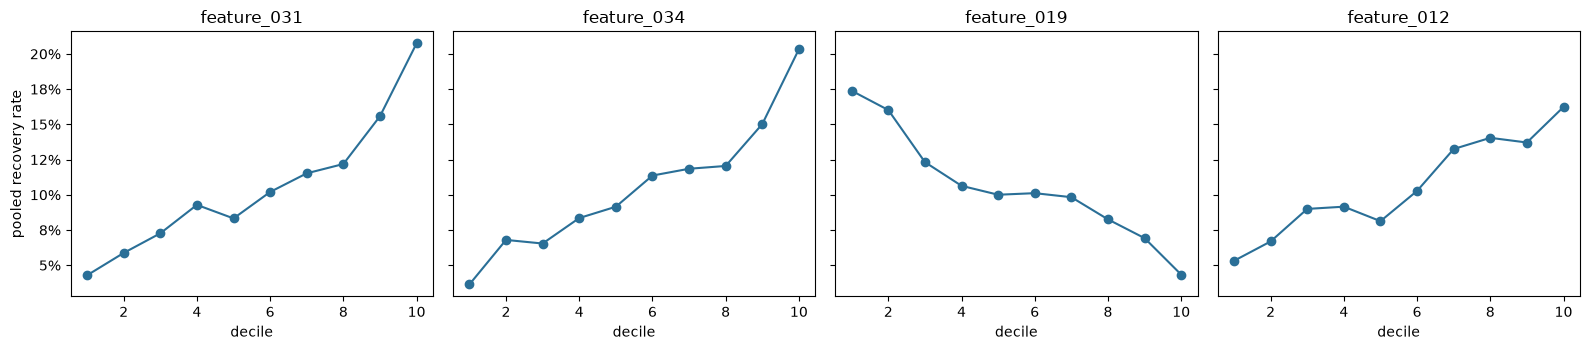

In [42]:
EXCLUDED = ["feature_045", "feature_018", "feature_027", "feature_050"]
signal_cols = [c for c in FEATURE_COLS if c not in EXCLUDED]

train_frame = (target_train.reset_index()
               .rename(columns={"CLIENT_KEY": "client_key"})
               [["client_key", "PERIOD", "rate", "profitable", "outstanding", "paid_24m_est"]]
               .merge(features[["client_key", "PERIOD"] + signal_cols], on=["client_key", "PERIOD"]))


def single_feature_signal(df: pd.DataFrame, cols: list[str], fd: pd.DataFrame) -> pd.DataFrame:
    """Spearman with the recovery rate and one-feature AUC for the profitable flag.
    AUC is shown as max(auc, 1 - auc); direction says whether higher values mean more (+) or less (-) recovery."""
    rows = []
    for col in cols:
        d = df[[col, "rate", "profitable"]].dropna()
        auc = roc_auc_score(d["profitable"], d[col])
        rows.append({"feature": col, "n": len(d),
                     "spearman_rate": d[col].corr(d["rate"], method="spearman"),
                     "auc_profitable": max(auc, 1 - auc),
                     "direction": "+" if auc >= 0.5 else "-"})
    out = pd.DataFrame(rows).set_index("feature").join(fd.set_index("column")[["group"]])
    return out.sort_values("auc_profitable", ascending=False)


def binned_rate(df: pd.DataFrame, col: str, bins: int = 10) -> pd.Series:
    """Pooled recovery rate by feature decile."""
    d = df[[col, "paid_24m_est", "outstanding"]].dropna()
    decile = pd.qcut(d[col].rank(method="first"), bins, labels=range(1, bins + 1))
    g = d.groupby(decile, observed=True)
    return g["paid_24m_est"].sum() / g["outstanding"].sum()


signal = single_feature_signal(train_frame, signal_cols, feat_dict)
display(signal.style.format({"n": "{:,}", "spearman_rate": "{:.3f}", "auc_profitable": "{:.3f}"}))

group_signal = (signal.groupby("group")
                .agg(features=("auc_profitable", "size"),
                     max_auc=("auc_profitable", "max"),
                     mean_auc=("auc_profitable", "mean"),
                     no_signal=("auc_profitable", lambda s: (s < 0.53).sum()))
                .sort_values("max_auc", ascending=False))
display(group_signal.style.format({"max_auc": "{:.3f}", "mean_auc": "{:.3f}"}))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, col in zip(axes, signal.index[:4]):
    r = binned_rate(train_frame, col)
    ax.plot(r.index.astype(int), r.values, marker="o", color="#2A6F97")
    ax.set_title(col)
    ax.set_xlabel("decile")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel("pooled recovery rate")
plt.tight_layout()
plt.show()

The analysis of the individual variables shows that most of the signal comes from the credit bureau history, the payment behavior on other loans and the account balances. The strongest feature is `feature_031`, with a univariate AUC of 0.645. Only 4 variables have an AUC above 0.60, and 21 features have an AUC below 0.53.

It should be noted that the individual analysis is important for a general picture, but it does not translate directly into the strength of the variables: tree-based models look at the variables in combination, and a variable that is weak on its own can still turn out to be strong in the model.

At the next stage we check for strong relationships between the features and possible redundancy. For this we look at the pairs whose absolute Spearman correlation is 0.8 or more, and in parallel we also compare the Pearson correlation. This is especially important for a linear model, where strongly correlated variables can affect the stability of the coefficients, and also for the correct interpretation of feature importance, because several features carrying the same information can split the importance between them.

In [43]:
def correlated_pairs(df: pd.DataFrame, cols: list[str], fd: pd.DataFrame, threshold: float = 0.8) -> pd.DataFrame:
    """Feature pairs whose Spearman or Pearson correlation is at least `threshold` in absolute value."""
    spearman = df[cols].corr(method="spearman")
    pearson = df[cols].corr(method="pearson")
    desc = fd.set_index("column")["description"]
    rows = []
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            if max(abs(spearman.loc[a, b]), abs(pearson.loc[a, b])) >= threshold:
                rows.append({"feature_a": a, "feature_b": b,
                             "spearman": spearman.loc[a, b], "pearson": pearson.loc[a, b],
                             "description_a": desc[a], "description_b": desc[b]})
    return pd.DataFrame(rows).sort_values("spearman", key=abs, ascending=False).reset_index(drop=True)


pairs = correlated_pairs(feat_scope, signal_cols, feat_dict)
display(pairs.style.format({"spearman": "{:.3f}", "pearson": "{:.3f}"}))

,feature_a,feature_b,spearman,pearson,description_a,description_b
0,feature_017,feature_033,1.000,1.000,"Number of credit facilities closed with no delinquency, internal records.","Number of credit facilities closed with no delinquency, as reported by the credit bureau."
1,feature_003,feature_007,0.926,0.901,"Total credit turnover across all accounts, monthly average over 3 months.","Total debit turnover across all accounts, monthly average over 6 months."
2,feature_031,feature_034,0.924,0.929,Credit bureau score at the last refresh before enforcement.,Internal behavioural score at the last monthly refresh before enforcement.


In the previous analyses `feature_017` and `feature_033` show exactly the same result on all the main measures: both have 9 unique values, 66.28% zero records, 3.42% outliers, a Spearman correlation of 0.117 with the recovery rate and a profitability AUC of 0.580.

Although in the dictionary these variables are in different business groups and are described with different sources, the full match of the results raises a suspicion of duplication. So we check directly whether they are equal in every client-period.

In [44]:
def duplicate_check(df: pd.DataFrame, col_a: str, col_b: str) -> dict:
    """Do two features hold the same value in every row?"""
    a, b = df[col_a], df[col_b]
    return {
        "rows compared": len(df),
        "identical values (%)": round(100 * (a == b).mean(), 2),
        "mismatched rows": int((a != b).sum()),
        "correlation": round(a.corr(b), 4),
        "max absolute difference": (a - b).abs().max(),
    }


display(pd.Series(duplicate_check(feat_scope, "feature_017", "feature_033"), dtype="object")
        .to_frame("feature_017 vs feature_033"))

,feature_017 vs feature_033
rows compared,23171
identical values (%),100.0
mismatched rows,0
correlation,1.0
max absolute difference,0


The two variables are identical and carry the same information in terms of content, even though they come from different sources. So one of them is excluded from modelling.

In [45]:
def psi(reference: pd.Series, current: pd.Series, bins: int = 10, eps: float = 1e-4) -> float:
    """Population Stability Index. Bins come from the reference period (deciles, or exact values
    for low-cardinality features); missing values get their own bin."""
    ref, cur = reference.dropna(), current.dropna()
    if ref.nunique() <= 20:
        cats = sorted(set(ref.unique()) | set(cur.unique()))
        ref_share = ref.value_counts().reindex(cats, fill_value=0).to_numpy() / len(reference)
        cur_share = cur.value_counts().reindex(cats, fill_value=0).to_numpy() / len(current)
    else:
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        ref_share = np.histogram(ref, edges)[0] / len(reference)
        cur_share = np.histogram(cur, edges)[0] / len(current)
    ref_share = np.append(ref_share, reference.isna().mean()) + eps
    cur_share = np.append(cur_share, current.isna().mean()) + eps
    return float(np.sum((cur_share - ref_share) * np.log(cur_share / ref_share)))


periods = sorted(feat_scope["PERIOD"].unique())
early = feat_scope[feat_scope["PERIOD"].isin(periods[:6])]
late = feat_scope[feat_scope["PERIOD"].isin(periods[-6:])]
print(f"reference: {periods[0]}-{periods[5]} ({len(early):,} rows)  |  current: {periods[-6]}-{periods[-1]} ({len(late):,} rows)")

psi_table = (pd.DataFrame({"psi": {c: psi(early[c], late[c]) for c in signal_cols}})
             .join(feat_dict.set_index("column")[["group"]])
             .sort_values("psi", ascending=False))
psi_table["status"] = np.select([psi_table["psi"] >= 0.25, psi_table["psi"] >= 0.10], ["red", "amber"], default="stable")
display(psi_table.head(10).style.format({"psi": "{:.4f}"}))
print(psi_table["status"].value_counts().to_dict())

drift_col = "feature_007"
median_by_period = feat_scope.groupby("PERIOD")[drift_col].median()
print(f"{drift_col} median: {periods[0]} {median_by_period.iloc[0]:.1f} -> {periods[-1]} {median_by_period.iloc[-1]:.1f}")
rank = feat_scope.groupby("PERIOD")[drift_col].rank(pct=True)
print(f"PSI of within-period percentile rank: {psi(rank[early.index], rank[late.index]):.4f}")

reference: 2023/01-2023/06 (2,431 rows)  |  current: 2025/09-2026/02 (4,830 rows)


,psi,group,status
feature_007,0.3264,transaction activity,red
feature_043,0.0139,recent credit applications,stable
feature_006,0.0113,transaction activity,stable
feature_046,0.0105,recent credit applications,stable
feature_002,0.0100,transaction activity,stable
feature_005,0.0097,transaction activity,stable
feature_003,0.0094,transaction activity,stable
feature_020,0.0086,repayment history on other loans,stable
feature_032,0.0084,credit bureau history,stable
feature_031,0.0082,credit bureau history,stable


{'stable': 45, 'red': 1}
feature_007 median: 2023/01 46.6 -> 2026/02 78.3
PSI of within-period percentile rank: 0.0000


We assessed the stability of the variables over time with the PSI method. For the comparison we took the early period from 2023/01 to 2023/06 and the most recent period from 2025/09 to 2026/02.

Out of 46 features, 45 are practically stable. The exception is `feature_007`, whose PSI is 0.326 and well above the 0.25 threshold. Over the same period its median grew from 46.6 to 78.3, which points to a clear distribution shift. Interestingly, `feature_003`, which is strongly correlated with it, stayed stable and has a PSI of only 0.009, so we can leave `feature_007` out.

,count,mean,std,min,max
label,,,,,
actual,20,11.1%,1.9%,7.8%,16.1%
extrapolated,12,10.1%,1.5%,7.2%,12.4%


first 6 cohorts: 12.3%  |  last 6 cohorts: 9.8%


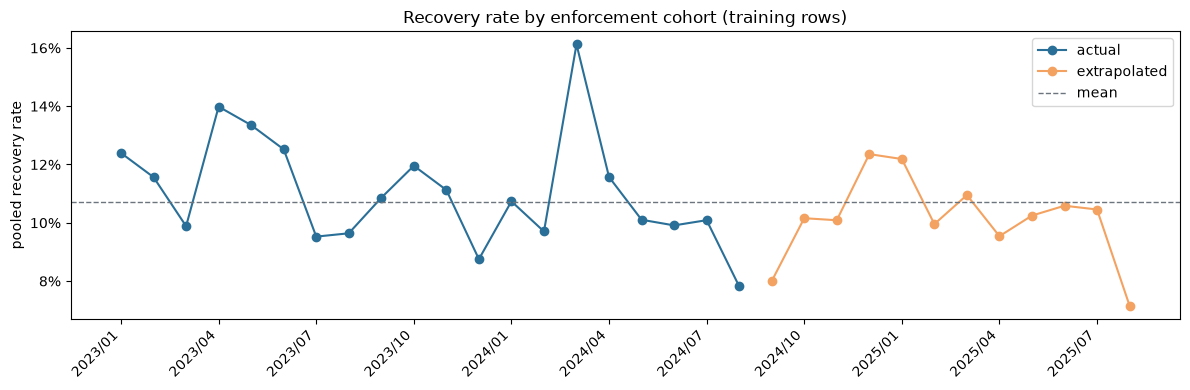

In [46]:
def recovery_by_cohort(df: pd.DataFrame) -> pd.DataFrame:
    """Pooled recovery rate and profitable share per enforcement cohort."""
    g = df.groupby("PERIOD")
    out = pd.DataFrame({
        "client_periods": g.size(),
        "months_observed": g["months_observed"].first(),
        "pooled_rate": g["paid_24m_est"].sum() / g["outstanding"].sum(),
        "profitable_share": g["profitable"].mean(),
    })
    out["label"] = np.where(out["months_observed"] == 24, "actual", "extrapolated")
    return out


cohorts_rate = recovery_by_cohort(target_train)
display(cohorts_rate.groupby("label")["pooled_rate"].agg(["count", "mean", "std", "min", "max"])
        .style.format("{:.1%}", subset=["mean", "std", "min", "max"]))
print(f"first 6 cohorts: {cohorts_rate['pooled_rate'].iloc[:6].mean():.1%}  |  last 6 cohorts: {cohorts_rate['pooled_rate'].iloc[-6:].mean():.1%}")

fig, ax = plt.subplots(figsize=(12, 4))
for label, color in [("actual", "#2A6F97"), ("extrapolated", "#F4A261")]:
    part = cohorts_rate[cohorts_rate["label"] == label]
    ax.plot(part.index, part["pooled_rate"], marker="o", color=color, label=label)
ax.axhline(cohorts_rate["pooled_rate"].mean(), color="#6C757D", linestyle="--", linewidth=1, label="mean")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xticks(range(0, len(cohorts_rate), 3))
ax.set_xticklabels(cohorts_rate.index[::3], rotation=45, ha="right")
ax.set_ylabel("pooled recovery rate")
ax.set_title("Recovery rate by enforcement cohort (training rows)")
ax.legend()
plt.tight_layout()
plt.show()

In most training cohorts the recovery rate ranges from 9% to 13% and there is no sharp structural change, but there is a moderate downward trend over time, within about 2.5 percentage points.

This difference is not explained by extrapolation alone, because a lower recovery is also seen in the relatively later fully observed cohorts. Two periods stand out: 2024/03 with a high recovery of 16.1%, and 2025/08 with a low recovery of 7.2%. Since the recovery rate is lower on the new data, it is important to go through this part with domain experts.

In [47]:
def prior_case_features(cp: pd.DataFrame) -> pd.DataFrame:
    """For each client-period, what the bank already knew about the client's previous case at decision time.
    Only prior-case months that ended before the current case's start month are used (gap - 1 months)."""
    df = cp.reset_index().assign(month=lambda d: month_index(d["PERIOD"])).sort_values(["CLIENT_KEY", "month"])
    prev = df.groupby("CLIENT_KEY")
    gap = df["month"] - prev["month"].shift()
    known_months = (gap - 1).clip(lower=0, upper=24)

    prev_paid = prev[PAY_COLS].shift().to_numpy()
    usable = np.arange(1, 25)[None, :] <= known_months.fillna(0).to_numpy()[:, None]
    prior_paid_known = np.nansum(np.where(usable, prev_paid, 0.0), axis=1)

    out = pd.DataFrame({
        "CLIENT_KEY": df["CLIENT_KEY"], "PERIOD": df["PERIOD"],
        "has_prior_case": gap.notna().astype(int),
        "months_since_prior_case": gap,
        "prior_months_known": known_months,
        "prior_rate_known": np.where(gap.notna(), prior_paid_known / prev["outstanding"].shift(), np.nan),
    })
    return out.set_index(["CLIENT_KEY", "PERIOD"])


prior = prior_case_features(cp_all)
tt = target_train.join(prior)
print(f"training client-periods with a prior case: {tt['has_prior_case'].sum():,} ({tt['has_prior_case'].mean():.1%})")

prior_group = np.select([tt["has_prior_case"] == 0, tt["prior_rate_known"] > 0],
                        ["no prior case", "prior case, paid"], default="prior case, nothing paid")
g = tt.groupby(prior_group)
display(pd.DataFrame({"client_periods": g.size(),
                      "pooled_rate": g["paid_24m_est"].sum() / g["outstanding"].sum(),
                      "profitable_share": g["profitable"].mean()})
        .style.format({"pooled_rate": "{:.1%}", "profitable_share": "{:.1%}"}))

training client-periods with a prior case: 3,804 (20.7%)


,client_periods,pooled_rate,profitable_share
no prior case,14537,10.8%,16.4%
"prior case, nothing paid",1709,6.0%,10.5%
"prior case, paid",2095,12.7%,20.2%


In the training data 3,804 client-periods, or 20.7 percent, already had a court case in the past. However, the existence of a previous case alone does not clearly determine recovery. The client's behavior during that case turned out to be much more important.

Among the clients who paid at least something on the previous case, the pooled recovery of the current case is 12.8 percent and the share of profitable cases reaches 20.2 percent. For those who paid nothing at all on the previous case, the corresponding numbers are only 6.0 and 10.5 percent. Among the clients without a previous case the recovery is 10.8 percent and the profitability share is 16.4 percent.

Based on this result, four additional variables are created:

`has_prior_case` shows whether the client had a court case in the past.

`months_since_prior_case` shows how many months have passed from the start of the previous case to the current case.

`prior_months_known` shows how many months of recovery history were actually known at the moment of the current decision.

`prior_rate_known` shows what share of the debt of the previous case had already been recovered before the current decision was made.

## 5. Model frame and evaluation design

In [48]:
DROPPED = {
    "feature_045": "leakage: measured after enforcement start",
    "feature_018": "leakage: measured at enforcement start",
    "feature_027": "leakage: measured at enforcement start",
    "feature_050": "constant",
    "feature_033": "exact duplicate of feature_017",
    "feature_007": "highly correlated with feature_003 (0.93) and drifts over time (PSI 0.33)",
}


def build_model_frame(target_df: pd.DataFrame, feat: pd.DataFrame, prior: pd.DataFrame) -> tuple[pd.DataFrame, list[str]]:
    """One row per in-scope client-period: target columns + final predictors."""
    f = (feat.rename(columns={"client_key": "CLIENT_KEY"})
             .set_index(["CLIENT_KEY", "PERIOD"])
             .drop(columns=list(DROPPED)))
    frame = (target_df[["months_observed", "outstanding", "rate", "paid_24m_est", "cost", "net", "profitable"]]
             .rename(columns={"outstanding": "total_outstanding"})
             .join(f)
             .join(prior))
    predictors = list(f.columns) + ["total_outstanding"] + list(prior.columns)
    return frame, predictors


model_frame, PREDICTORS = build_model_frame(target, features, prior)
print(f"model frame: {model_frame.shape[0]:,} client-periods, {len(PREDICTORS)} predictors")

display(pd.Series(DROPPED, name="reason").to_frame())
display(model_frame[PREDICTORS].isna().sum()[lambda s: s > 0].to_frame("missing values"))

model frame: 23,171 client-periods, 49 predictors


,reason
feature_045,leakage: measured after enforcement start
feature_018,leakage: measured at enforcement start
feature_027,leakage: measured at enforcement start
feature_050,constant
feature_033,exact duplicate of feature_017
feature_007,highly correlated with feature_003 (0.93) and ...


,missing values
feature_011,19953
feature_039,7111
months_since_prior_case,17105
prior_months_known,17105
prior_rate_known,17105


The final model frame contains 23,171 in-scope client-periods and 49 predictors.

Out of the original 50 dictionary features, 44 variables stay in modelling. `feature_045` was excluded because the information becomes available after enforcement starts, as were `feature_018` and `feature_027`, which are recorded at the moment enforcement starts and are not yet available when the decision is made. `feature_050` is constant, and `feature_033` is an exact duplicate of `feature_017`. `feature_007` is no longer used, because it is strongly correlated with `feature_003` and also showed significant drift over time.

5 derived variables are added to the dictionary features: `total_outstanding` reflects the total debt of all the client's loans at the moment the court process starts, while `has_prior_case`, `months_since_prior_case`, `prior_months_known` and `prior_rate_known` describe the client's previous court case and the recovery history already known at that moment.

Additional transformations, including log transformation and missing indicators, are not added to the model frame. Missing values are kept in their original form, because their presence itself carries business information: a missing `feature_011` mostly points to not having a deposit or savings product, a missing `feature_039` to the absence of declared income, and missing values in the prior case variables mean that there is no previous court case for the client. Tree based models handle `NaN` values directly, so no imputation is done and the possible informative effect of missingness is kept. The target is fully filled in.

In [49]:
LAYER_A, LAYER_AP, LAYER_B = "A (clean)", "A' (intermediate)", "B (recent, OOT)"
LAYERS = {
    LAYER_A:  {"train_to": "2024/02", "test_from": "2024/03", "test_to": "2024/08"},
    LAYER_AP: {"train_to": "2024/08", "test_from": "2024/09", "test_to": "2025/02"},
    LAYER_B:  {"train_to": "2025/08", "test_from": "2025/09", "test_to": "2026/02"},
}


def split_layer(frame: pd.DataFrame, train_to: str, test_from: str, test_to: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Time-ordered split; clients that appear in the test window are removed from training."""
    period = frame.index.get_level_values("PERIOD")
    client = frame.index.get_level_values("CLIENT_KEY")
    test = frame[(period >= test_from) & (period <= test_to)]
    train = frame[(period <= train_to) & ~client.isin(test.index.get_level_values("CLIENT_KEY"))]
    return train, test


splits = {name: split_layer(model_frame, **cfg) for name, cfg in LAYERS.items()}

layer_rows = []
for name, cfg in LAYERS.items():
    train, test = splits[name]
    all_train = (model_frame.index.get_level_values("PERIOD") <= cfg["train_to"]).sum()
    layer_rows.append({
        "layer": name,
        "train_cohorts": f"2023/01 - {cfg['train_to']}",
        "test_cohorts": f"{cfg['test_from']} - {cfg['test_to']}",
        "train_rows": len(train), "purged_from_train": all_train - len(train), "test_rows": len(test),
        "test_months_observed": f"{test['months_observed'].min()}-{test['months_observed'].max()}",
        "test_profitable": test["profitable"].mean(),
        "test_refer_all_net": test["net"].sum(),
    })
display(pd.DataFrame(layer_rows).set_index("layer")
        .style.format({"train_rows": "{:,}", "purged_from_train": "{:,}", "test_rows": "{:,}",
                       "test_profitable": "{:.1%}", "test_refer_all_net": "{:,.0f}"}))

,train_cohorts,test_cohorts,train_rows,purged_from_train,test_rows,test_months_observed,test_profitable,test_refer_all_net
layer,,,,,,,,
A (clean),2023/01 - 2024/02,2024/03 - 2024/08,"5,962",421,"3,514",24-24,16.2%,"-1,547,985"
A' (intermediate),2023/01 - 2024/08,2024/09 - 2025/02,"9,134",763,"4,030",18-23,15.8%,"-1,861,607"
"B (recent, OOT)",2023/01 - 2025/08,2025/09 - 2026/02,"16,790","1,551","4,830",6-11,14.4%,"-2,805,577"


### Evaluation design

The evaluation of the model is built sequentially in time, to get as close as possible to the real usage scenario: the model always learns on older cohorts and is evaluated only on the following periods.

**Layer A** is the cleanest evaluation. Training covers 2023/01 to 2024/02, and the test covers 2024/03 to 2024/08. Both sides have the actual 24-month outcome, so no extrapolation is used here at all. The model family is chosen on this layer.

**Layer A′** is an intermediate evaluation. Training covers 2023/01 to 2024/08, and the test covers 2024/09 to 2025/02. The test outcome is already partly extrapolated, but we have 18 to 23 months of observation and the uncertainty is relatively small.

**Layer B** is the most recent out-of-time period. Training covers 2023/01 to 2025/08, and the test covers 2025/09 to 2026/02. Here the test labels are extrapolated from 6 to 11 months of observation, so this layer shows best how the model generalizes to new cohorts, but its evaluation should not be treated as full ground truth.

**Layer C** is an additional check on the same most recent test population. Here the prediction is compared only with the actually observed short-term recovery, which needs no extrapolation at all and gives us an independent assessment of the ranking quality.

The train and test data are split at the client level: if a client appears in the test period, the client's records from other periods are also removed from training. For the extrapolation of the test labels the recovery curve is always built only from the fully observed cohorts in the corresponding training window. The same principle is used during hyperparameter tuning, where time-ordered folds are created inside the training window and the curve is recomputed on each fold.

The main evaluation metric is the realised net GEL and its improvement compared to the refer-all strategy. AUC, Spearman correlation and the net result at different capacity levels are used as additional diagnostics.

It is important that this comparison does not measure the model against the expert rule. The data only has the clients already selected by the expert, so the baseline is referring all of these clients to court, and the evaluation is a retrospective cohort forward backtest and not a full simulation of a real deployment.

### Summary of decisions before modelling

| #   | Decision | Main rationale |
| --- | --- | --- |
| D1  | The target population of the model is only fully unsecured client-periods, 23,171 cases in total | For mixed clients the secured and unsecured loans are referred to court together, so the source of recovery cannot be separated |
| D2  | The court cost is defined as 500 GEL per client-period plus 10 percent of `total_outstanding`. The per loan cost is treated as a sensitivity scenario | The court referral decision is made at the client level |
| D3  | The target is the 24-month recovery rate from 0 to 1. When needed, GEL is obtained with the formula `rate × total_outstanding` | Recovery is heavily concentrated at zero and asymmetric. The rate reduces the direct influence of large balances on the target |
| D4  | Training includes the 18,341 client-periods observed for at least 12 months. From 12 to 23 months the outcome is estimated by extrapolation, and the 4,830 cases with 6 to 11 months stay as the out-of-time test | On the LOCO backtest the MAE at 12 months is 0.86 percentage points, and the profitability decision changes in only 0.54 percent of the cases |
| D5  | Both cases of repeat clients are kept. The split is done taking both time and client into account. 4 prior case variables are added | The payment behavior on the previous case is a strong signal: the recovery of the current case is 12.8 percent for those who paid before and 6.0 percent for those who did not |
| D6  | `feature_045` and `feature_050` are excluded. The missing values of `feature_011` and `feature_039` keep the `NaN` form | `feature_045` contains information that exists after the decision, and `feature_050` is constant. Missingness itself carries business information |
| D7  | The baseline is referring all in-scope clients to court. The main metric is realised net GEL | The final business goal is to improve the financial result, not just predictive accuracy |
| D8  | The 40 loans with `OUTST_AT_TRIAL ≤ 0` are excluded. USD loans stay | A non-positive outstanding is economically incorrect, and by our check the outstanding of USD loans is already expressed in GEL equivalent |
| D9  | The recovery rate is capped at a maximum of 1.0 | Extrapolation rarely gives a recovery above 100 percent. The cap is active in only 0.06 percent of the cases |
| D10 | `feature_018` and `feature_027` are excluded | Both variables are recorded at the moment enforcement starts and are not available before the decision |
| D11 | The evaluation is done on layers A, A′, B and C. The model family is chosen on the clean Layer A | In Layer A the train and test outcomes are fully actual. The other layers check temporal generalization and performance on the most recent cohorts |
| D12 | The final model frame contains 49 predictors: 44 dictionary features, `total_outstanding` and 4 prior case variables. Outliers are not removed | `feature_033` is an exact duplicate of `feature_017`. `feature_007` shows strong drift. `feature_031` and `feature_034`, despite their high correlation, keep a strong predictive signal from different sources |

The main purpose of these decisions is that the training data keeps only the information that would really have been available at the moment of the decision, that the target is economically correctly defined, and that the evaluation design reflects as realistically as possible how the model works on future cohorts.

## 6. Modelling

We consider three tree based algorithms: Random Forest, XGBoost and LightGBM. Each one is evaluated with two approaches, so in total we compare 6 models.

1. The **Direct** approach, where the model predicts the 24-month recovery rate directly.
2. The **Hurdle** approach, where the task is split into two parts: a classifier estimates the probability that anything will be recovered from the client at all, and a regressor estimates the expected recovery rate only for the clients from whom a recovery was recorded. The final prediction is `P(pay) × E[recovery rate | pay]`.

The advantage of tree based models in this task is that they can handle missing values directly, so no imputation is needed. Also, non-normal distributions and different scales of the variables are not the same kind of problem for them as for linear models, so no additional transformations are used.

All models are evaluated with the same business rule:

`Expected Net = Predicted Recovery × Total Outstanding - Court Cost`

A client is selected for court referral only if the expected net result is positive. The final model family is chosen based on the results of Layer A, while Layer B is used to check the temporal generalization of the already selected model and not for model selection.

In [50]:
CAPACITIES = (0.10, 0.20, 0.30)


def evaluate_policy(test: pd.DataFrame, refer: np.ndarray, score: np.ndarray) -> dict:
    """Business metrics for any referral policy on a test window.
    `refer` = who goes to court; `score` = ranking used for AUC and for capacity-limited selection."""
    refer = np.asarray(refer, dtype=bool)
    score = np.asarray(score, dtype=float)
    net, prof = test["net"].to_numpy(), test["profitable"].to_numpy()
    out = {
        "net_gel": net[refer].sum(),
        "vs_refer_all": net[refer].sum() - net.sum(),
        "share_referred": refer.mean(),
        "precision": prof[refer].mean() if refer.any() else np.nan,
        "recall": prof[refer].sum() / prof.sum(),
        "auc_profitable": roc_auc_score(prof, score) if np.unique(score).size > 1 else np.nan,
    }
    order = np.argsort(-score, kind="stable")
    for cap in CAPACITIES:
        top = order[:int(np.ceil(cap * len(test)))]
        top = top[refer[top]]
        out[f"net_at_{int(cap * 100)}pct"] = net[top].sum()
    return out


def expected_net(outstanding: np.ndarray, pred_rate: np.ndarray) -> np.ndarray:
    """Expected net GEL of referring a client-period to court."""
    return np.clip(pred_rate, 0, 1) * outstanding - (COST_FIXED + COST_PCT * outstanding)


def evaluate_model(test: pd.DataFrame, pred_rate: np.ndarray, margin: float = 0.0) -> dict:
    """Turn predicted rates into the referral decision and evaluate it."""
    pred_rate = np.clip(np.asarray(pred_rate, dtype=float), 0, 1)
    outst = test["total_outstanding"].to_numpy()
    net = expected_net(outst, pred_rate)
    refer = net > margin

    out = evaluate_policy(test, refer, net)
    out["spearman_rate"] = pd.Series(pred_rate).corr(pd.Series(test["rate"].to_numpy()), method="spearman")
    recovered = (test["rate"].to_numpy() * outst)[refer].sum()
    predicted = (pred_rate * outst)[refer].sum()
    out["calibration_referred"] = recovered / predicted if predicted > 0 else np.nan
    return out

In [51]:
def refer_all(train: pd.DataFrame, test: pd.DataFrame):
    """Refer every expert-approved client (current practice within the data)."""
    return np.ones(len(test), dtype=bool), test["total_outstanding"].to_numpy(), {}


def outstanding_rule(train: pd.DataFrame, test: pd.DataFrame):
    """Refer if total_outstanding >= cut-off; cut-off chosen on training net GEL ('refer none' allowed)."""
    cuts = np.append(np.quantile(train["total_outstanding"], np.linspace(0, 0.95, 20)), np.inf)
    gains = [train.loc[train["total_outstanding"] >= c, "net"].sum() for c in cuts]
    best = cuts[int(np.argmax(gains))]
    return (test["total_outstanding"] >= best).to_numpy(), test["total_outstanding"].to_numpy(), {"min_outstanding": best}


def outstanding_score_rule(train: pd.DataFrame, test: pd.DataFrame, score_col: str = "feature_031"):
    """Refer if total_outstanding and bureau score are both above cut-offs chosen on training net GEL."""
    o_cuts = np.append(np.quantile(train["total_outstanding"], np.linspace(0, 0.9, 10)), np.inf)
    s_cuts = np.quantile(train[score_col], np.linspace(0, 0.9, 10))
    best, best_gain = (np.inf, -np.inf), 0.0
    for oc in o_cuts:
        for sc in s_cuts:
            gain = train.loc[(train["total_outstanding"] >= oc) & (train[score_col] >= sc), "net"].sum()
            if gain > best_gain:
                best, best_gain = (oc, sc), gain
    refer = (test["total_outstanding"] >= best[0]) & (test[score_col] >= best[1])
    score = test["total_outstanding"].rank(pct=True) + test[score_col].rank(pct=True)
    return refer.to_numpy(), score.to_numpy(), {"min_outstanding": best[0], f"min_{score_col}": best[1]}


def oracle(train: pd.DataFrame, test: pd.DataFrame):
    """Perfect selection: refer exactly the profitable cases (upper bound, not achievable)."""
    return test["profitable"].to_numpy(), test["net"].to_numpy(), {}


BASELINES = {"refer-all": refer_all, "outstanding rule": outstanding_rule,
             "outstanding + bureau score": outstanding_score_rule, "oracle (ceiling)": oracle}

baseline_rows, param_rows = [], []
for layer in LAYERS:
    train, test = splits[layer]
    for name, rule in BASELINES.items():
        refer, score, fitted_params = rule(train, test)
        baseline_rows.append({"layer": layer, "model": name, **evaluate_policy(test, refer, score)})
        if fitted_params:
            param_rows.append({"layer": layer, "model": name, **fitted_params})

baseline_results = pd.DataFrame(baseline_rows).set_index(["layer", "model"])
baseline_params = pd.DataFrame(param_rows).set_index(["layer", "model"])

display(baseline_results.style.format({
    "net_gel": "{:,.0f}", "vs_refer_all": "{:,.0f}", "share_referred": "{:.1%}", "precision": "{:.1%}",
    "recall": "{:.1%}", "auc_profitable": "{:.3f}",
    "net_at_10pct": "{:,.0f}", "net_at_20pct": "{:,.0f}", "net_at_30pct": "{:,.0f}"}))
display(baseline_params.round(0))

min_outstanding  min_feature_031
layer             model                                                       
A (clean)         outstanding rule                    22953.0              NaN
                  outstanding + bureau score           4897.0            365.0
A' (intermediate) outstanding rule                    22580.0              NaN
                  outstanding + bureau score           8160.0            366.0
B (recent, OOT)   outstanding rule                        inf              NaN
                  outstanding + bureau score           8176.0            366.0

### Baseline models

Before evaluating the model we created simple baseline rules, to have a clear reference level that the final model has to beat.

Referring all clients to court is loss-making in all three test periods: the net result of the refer-all strategy is about -1.55 million GEL in Layer A, -1.86 million GEL in Layer A′ and -2.81 million GEL in Layer B.

The rule based only on outstanding shows a weak result. In Layers A and A′ the optimal threshold is about 23 thousand GEL, while in Layer B the cutoff obtained on the training data is such that referring any client is no longer recommended. This matches the EDA result that the recovery rate practically does not grow with the size of the debt.

Among the simple rules the best one is the combination of outstanding and the credit bureau score. Depending on the layer, the optimal thresholds are about 4.9 to 8.2 thousand GEL of outstanding and a bureau score of 365 to 366. This rule gives a positive net result in all three test periods, about 200 thousand, 189 thousand and 51 thousand GEL.

Even so, the result of this rule uses only a small part of the oracle potential: about 12 percent in Layer A and only 3 percent in Layer B. So outstanding plus bureau score is a good simple benchmark, but it is not enough as a full decision rule. This is the practical baseline that the tree based models have to beat.

### Hyperparameter tuning

The tuning was done with a grid search approach. On each layer we have 4 expanding validation folds, and the other records of the clients that fall into the validation part are also removed from the training part. If a row in a given fold has less than 24 months of observation, its target is rebuilt only with the recovery curve obtained from the fully observed cohorts in the training period of that fold, so no information from the future gets into the validation result.

The best configuration is selected by the average realised net GEL across the folds and not by RMSE or AUC. This choice matches the business goal directly, because the value of the model is defined by how profitable the court cases it selects are.

Class weights are not used, because the payer and non-payer classes are roughly balanced, and artificial weighting could damage the calibration, which is a direct part of the final recovery prediction. The tuning is done independently on layers A, A′ and B, and the selected configuration is finally retrained on the corresponding full training window, after which it is evaluated once on the test part.

In [52]:
FAMILIES = ("RandomForest", "XGBoost", "LightGBM")
APPROACHES = ("direct", "hurdle")
N_INNER_FOLDS = 4
PARAM_GRID = {
    "RandomForest": [{"max_depth": depth, "min_samples_leaf": leaf}
                     for depth in (8, 12, None) for leaf in (20, 50, 100)],
    "XGBoost": [{"n_estimators": n, "max_depth": depth, "min_child_weight": child}
                for n in (300, 600) for depth in (4, 6) for child in (50, 100, 200)],
    "LightGBM": [{"n_estimators": n, "num_leaves": leaves, "min_child_samples": child}
                 for n in (300, 600) for leaves in (15, 31) for child in (50, 100, 200)],
}


def make_model(family: str, task: str, params: dict):
    """task: 'reg' predicts the rate, 'clf' predicts rate > 0. Settings outside the grid are fixed."""
    if family == "RandomForest":
        cls = RandomForestRegressor if task == "reg" else RandomForestClassifier
        return cls(n_estimators=400, max_features=0.3, n_jobs=-1, random_state=SEED, **params)
    if family == "XGBoost":
        cls = XGBRegressor if task == "reg" else XGBClassifier
        return cls(learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                   n_jobs=-1, random_state=SEED, **params)
    cls = lgb.LGBMRegressor if task == "reg" else lgb.LGBMClassifier
    return cls(learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
               n_jobs=-1, random_state=SEED, verbose=-1, **params)


def fit_predict(approach: str, family: str, params: dict, fit: pd.DataFrame, new: pd.DataFrame) -> pd.DataFrame:
    """Fit on `fit`, predict on `new`. Hurdle = P(rate > 0) x E[rate | rate > 0]; classifier is unweighted."""
    X_fit, X_new = fit[PREDICTORS], new[PREDICTORS]
    if approach == "direct":
        reg = make_model(family, "reg", params).fit(X_fit, fit["rate"])
        return pd.DataFrame({"pred_rate": np.clip(reg.predict(X_new), 0, 1)}, index=new.index)
    payer = fit["rate"] > 0
    clf = make_model(family, "clf", params).fit(X_fit, payer.astype(int))
    reg = make_model(family, "reg", params).fit(X_fit[payer], fit.loc[payer, "rate"])
    p_pay = clf.predict_proba(X_new)[:, 1]
    rate_if_pay = np.clip(reg.predict(X_new), 0, 1)
    return pd.DataFrame({"pred_rate": p_pay * rate_if_pay, "p_pay": p_pay, "rate_if_pay": rate_if_pay}, index=new.index)

In [53]:
def relabel(rows: pd.DataFrame, train_end: str) -> pd.DataFrame:
    """Rebuild extrapolated labels (months_observed < 24) with a curve fitted only on fully observed
    cohorts up to `train_end`, so validation labels never use later information."""
    partial = rows["months_observed"] < 24
    if not partial.any():
        return rows
    fold_curve = cohort_curve(unsecured[unsecured.index.get_level_values("PERIOD") <= train_end])
    rows = rows.copy()
    idx = rows.index[partial]
    outst = rows.loc[idx, "total_outstanding"]
    rate = (unsecured.loc[idx, "paid_observed"] / rows.loc[idx, "months_observed"].map(fold_curve) / outst).clip(upper=1.0)
    rows.loc[idx, "rate"] = rate
    rows.loc[idx, "paid_24m_est"] = rate * outst
    rows.loc[idx, "net"] = rate * outst - rows.loc[idx, "cost"]
    rows.loc[idx, "profitable"] = rows.loc[idx, "net"] > 0
    return rows


def inner_folds(train: pd.DataFrame, n_folds: int = N_INNER_FOLDS):
    """Expanding, time-ordered folds: fit on the earliest blocks of cohorts, validate on the next block;
    validation clients are purged from the fit part."""
    periods = np.array(sorted(train.index.get_level_values("PERIOD").unique()))
    blocks = np.array_split(periods, n_folds + 1)
    period = train.index.get_level_values("PERIOD")
    client = train.index.get_level_values("CLIENT_KEY")
    for k in range(1, n_folds + 1):
        fit_periods, val_periods = np.concatenate(blocks[:k]), blocks[k]
        val = train[period.isin(val_periods)]
        fit = train[period.isin(fit_periods) & ~client.isin(val.index.get_level_values("CLIENT_KEY"))]
        yield relabel(fit, fit_periods[-1]), relabel(val, fit_periods[-1])


fold_rows = []
for layer in LAYERS:
    for k, (fit, val) in enumerate(inner_folds(splits[layer][0]), start=1):
        fp, vp = fit.index.get_level_values("PERIOD"), val.index.get_level_values("PERIOD")
        fold_rows.append({"layer": layer, "fold": k, "fit_cohorts": f"{fp.min()} - {fp.max()}", "fit_rows": len(fit),
                          "validation_cohorts": f"{vp.min()} - {vp.max()}", "validation_rows": len(val)})
display(pd.DataFrame(fold_rows).set_index(["layer", "fold"]))

fit_cohorts  fit_rows validation_cohorts  \
layer             fold                                                   
A (clean)         1     2023/01 - 2023/03      1094  2023/04 - 2023/06   
                  2     2023/01 - 2023/06      2194  2023/07 - 2023/09   
                  3     2023/01 - 2023/09      3438  2023/10 - 2023/12   
                  4     2023/01 - 2023/12      4881  2024/01 - 2024/02   
A' (intermediate) 1     2023/01 - 2023/04      1418  2023/05 - 2023/08   
                  2     2023/01 - 2023/08      2939  2023/09 - 2023/12   
                  3     2023/01 - 2023/12      4699  2024/01 - 2024/04   
                  4     2023/01 - 2024/04      6553  2024/05 - 2024/08   
B (recent, OOT)   1     2023/01 - 2023/07      2412  2023/08 - 2024/02   
                  2     2023/01 - 2024/02      5426  2024/03 - 2024/08   
                  3     2023/01 - 2024/08      8260  2024/09 - 2025/02   
                  4     2023/01 - 2025/02     11619  2025/03 - 2025/08   

                        validation_rows  
layer             fold                   
A (clean)         1                1149  
                  2                1283  
                  3                1424  
                  4                 992  
A' (intermediate) 1                1592  
                  2                1841  
                  3                1988  
                  4                2246  
B (recent, OOT)   1                3239  
                  2                3176  
                  3                3701  
                  4                4066

In [54]:
tuning_rows, model_rows, component_rows = [], [], []
predictions = {}
for layer in LAYERS:
    train, test = splits[layer]
    folds = list(inner_folds(train))
    for family in FAMILIES:
        for approach in APPROACHES:
            candidate = f"{family} {approach}"
            scores = []
            for params in PARAM_GRID[family]:
                nets = [evaluate_model(val, fit_predict(approach, family, params, fit, val)["pred_rate"])["net_gel"]
                        for fit, val in folds]
                scores.append((np.mean(nets), np.std(nets), params))
                tuning_rows.append({"layer": layer, "model": candidate, **params,
                                    "inner_net_mean": np.mean(nets), "inner_net_sd": np.std(nets)})
            best_net, best_sd, best_params = max(scores, key=lambda s: s[0])

            pred = fit_predict(approach, family, best_params, train, test)
            predictions[(layer, candidate)] = pred
            model_rows.append({"layer": layer, "model": candidate, "best_params": best_params,
                               "inner_net_mean": best_net, "inner_net_sd": best_sd,
                               **evaluate_model(test, pred["pred_rate"])})
            if approach == "hurdle":
                paid = test["rate"] > 0
                component_rows.append({
                    "layer": layer, "model": candidate,
                    "pay_auc": roc_auc_score(paid, pred["p_pay"]),
                    "pay_avg_precision": average_precision_score(paid, pred["p_pay"]),
                    "rate_if_pay_spearman": pred.loc[paid, "rate_if_pay"].corr(test.loc[paid, "rate"], method="spearman"),
                })
            print(f"{layer} | {candidate} done")

model_results = pd.DataFrame(model_rows).set_index(["layer", "model"])
tuning_results = pd.DataFrame(tuning_rows)
hurdle_components = pd.DataFrame(component_rows).set_index(["layer", "model"])

A (clean) | RandomForest direct done
A (clean) | RandomForest hurdle done
A (clean) | XGBoost direct done
A (clean) | XGBoost hurdle done
A (clean) | LightGBM direct done
A (clean) | LightGBM hurdle done
A' (intermediate) | RandomForest direct done
A' (intermediate) | RandomForest hurdle done
A' (intermediate) | XGBoost direct done
A' (intermediate) | XGBoost hurdle done
A' (intermediate) | LightGBM direct done
A' (intermediate) | LightGBM hurdle done
B (recent, OOT) | RandomForest direct done
B (recent, OOT) | RandomForest hurdle done
B (recent, OOT) | XGBoost direct done
B (recent, OOT) | XGBoost hurdle done
B (recent, OOT) | LightGBM direct done
B (recent, OOT) | LightGBM hurdle done


In [55]:
COLUMNS = ["net_gel", "vs_refer_all", "share_referred", "precision", "recall", "auc_profitable",
           "spearman_rate", "calibration_referred", "net_at_10pct", "net_at_20pct", "net_at_30pct"]
FMT = {"net_gel": "{:,.0f}", "vs_refer_all": "{:,.0f}", "share_referred": "{:.1%}", "precision": "{:.1%}",
       "recall": "{:.1%}", "auc_profitable": "{:.3f}", "spearman_rate": "{:.3f}", "calibration_referred": "{:.2f}",
       "net_at_10pct": "{:,.0f}", "net_at_20pct": "{:,.0f}", "net_at_30pct": "{:,.0f}"}

comparison = pd.concat([model_results[COLUMNS], baseline_results.reindex(columns=COLUMNS)])
for layer in LAYERS:
    display(comparison.loc[layer].sort_values("net_gel", ascending=False)
            .style.format(FMT, na_rep="-").set_caption(layer))

net_by_approach = model_results["net_gel"].unstack("layer")[list(LAYERS)]
net_by_approach.index = pd.MultiIndex.from_tuples([tuple(m.split(" ")) for m in net_by_approach.index],
                                                  names=["family", "approach"])
display(net_by_approach.style.format("{:,.0f}").set_caption("net GEL: family x approach"))
display(hurdle_components.style.format("{:.3f}").set_caption("hurdle components on test"))
display(model_results["best_params"].unstack("layer")[list(LAYERS)])

test_b = splits[LAYER_B][1]
obs_6m_rate = unsecured.loc[test_b.index, PAY_COLS[:6]].sum(axis=1) / test_b["total_outstanding"]
layer_c = pd.DataFrame({
    model: {"spearman_obs_6m_rate": pred["pred_rate"].corr(obs_6m_rate, method="spearman"),
            "auc_any_payment_6m": roc_auc_score(obs_6m_rate > 0, pred["pred_rate"])}
    for (layer, model), pred in predictions.items() if layer == LAYER_B}).T
display(layer_c.style.format("{:.3f}")
        .set_caption(f"Layer C (share with any 6-month payment: {(obs_6m_rate > 0).mean():.1%})"))

,net_gel,vs_refer_all,share_referred,precision,recall,auc_profitable,spearman_rate,calibration_referred,net_at_10pct,net_at_20pct,net_at_30pct
model,,,,,,,,,,,
oracle (ceiling),"1,733,195","3,281,180",16.2%,100.0%,100.0%,1.000,-,-,"1,633,313","1,733,195","1,733,195"
LightGBM hurdle,"699,473","2,247,457",14.1%,47.2%,41.1%,0.760,0.358,1.10,"678,583","699,473","699,473"
XGBoost direct,"696,518","2,244,503",15.0%,46.2%,42.8%,0.761,0.354,1.12,"640,839","696,518","696,518"
LightGBM direct,"671,621","2,219,606",15.3%,45.7%,43.0%,0.750,0.353,1.06,"631,348","671,621","671,621"
XGBoost hurdle,"669,818","2,217,803",13.8%,47.5%,40.5%,0.765,0.363,1.11,"654,951","669,818","669,818"
RandomForest hurdle,"640,819","2,188,804",11.4%,45.8%,32.3%,0.750,0.350,1.30,"638,114","640,819","640,819"
RandomForest direct,"638,980","2,186,965",12.1%,45.4%,33.9%,0.749,0.341,1.24,"648,012","638,980","638,980"
outstanding + bureau score,"199,944","1,747,929",10.2%,33.5%,21.1%,0.678,-,-,"233,987","200,400","199,944"
outstanding rule,"87,524","1,635,509",4.5%,24.2%,6.7%,0.611,-,-,"87,524","87,524","87,524"


,net_gel,vs_refer_all,share_referred,precision,recall,auc_profitable,spearman_rate,calibration_referred,net_at_10pct,net_at_20pct,net_at_30pct
model,,,,,,,,,,,
oracle (ceiling),"1,979,115","3,840,722",15.8%,100.0%,100.0%,1.000,-,-,"1,884,534","1,979,115","1,979,115"
XGBoost hurdle,"751,320","2,612,927",13.9%,46.5%,41.1%,0.751,0.347,1.07,"782,167","751,320","751,320"
LightGBM direct,"751,154","2,612,761",15.0%,45.0%,42.8%,0.743,0.341,1.03,"737,678","751,154","751,154"
LightGBM hurdle,"712,233","2,573,840",15.0%,44.5%,42.4%,0.742,0.341,1.01,"706,166","712,233","712,233"
XGBoost direct,"712,225","2,573,832",14.9%,44.1%,41.6%,0.744,0.346,1.04,"750,541","712,225","712,225"
RandomForest hurdle,"628,065","2,489,672",11.5%,45.9%,33.5%,0.740,0.325,1.15,"617,592","628,065","628,065"
RandomForest direct,"621,558","2,483,165",12.1%,44.4%,34.0%,0.735,0.315,1.13,"608,555","621,558","621,558"
outstanding + bureau score,"188,850","2,050,457",6.1%,34.7%,13.4%,0.675,-,-,"179,367","188,850","188,850"
outstanding rule,"-24,396","1,837,211",4.7%,23.9%,7.1%,0.630,-,-,"-24,396","-24,396","-24,396"


,net_gel,vs_refer_all,share_referred,precision,recall,auc_profitable,spearman_rate,calibration_referred,net_at_10pct,net_at_20pct,net_at_30pct
model,,,,,,,,,,,
oracle (ceiling),"1,860,864","4,666,441",14.4%,100.0%,100.0%,1.000,-,-,"1,792,842","1,860,864","1,860,864"
XGBoost hurdle,"608,628","3,414,205",12.5%,43.5%,37.9%,0.750,0.323,0.96,"616,513","608,628","608,628"
LightGBM direct,"603,706","3,409,282",13.0%,42.7%,38.5%,0.750,0.313,0.92,"605,499","603,706","603,706"
LightGBM hurdle,"594,057","3,399,634",12.4%,43.6%,37.8%,0.748,0.322,0.93,"581,122","594,057","594,057"
XGBoost direct,"568,938","3,374,515",12.7%,42.7%,37.6%,0.756,0.318,0.95,"532,641","568,938","568,938"
RandomForest direct,"555,086","3,360,663",12.1%,42.8%,36.2%,0.739,0.305,1.02,"515,839","555,086","555,086"
RandomForest hurdle,"542,200","3,347,777",10.7%,42.9%,31.8%,0.741,0.312,1.06,"517,281","542,200","542,200"
outstanding + bureau score,"50,727","2,856,304",5.9%,30.0%,12.2%,0.665,-,-,"46,673","50,727","50,727"
outstanding rule,0,"2,805,577",0.0%,-,0.0%,0.605,-,-,0,0,0


layer,A (clean),A' (intermediate),"B (recent, OOT)"
model,,,
LightGBM direct,"{'n_estimators': 300, 'num_leaves': 15, 'min_c...","{'n_estimators': 300, 'num_leaves': 15, 'min_c...","{'n_estimators': 300, 'num_leaves': 31, 'min_c..."
LightGBM hurdle,"{'n_estimators': 300, 'num_leaves': 15, 'min_c...","{'n_estimators': 300, 'num_leaves': 31, 'min_c...","{'n_estimators': 300, 'num_leaves': 31, 'min_c..."
RandomForest direct,"{'max_depth': 8, 'min_samples_leaf': 20}","{'max_depth': 8, 'min_samples_leaf': 20}","{'max_depth': None, 'min_samples_leaf': 20}"
RandomForest hurdle,"{'max_depth': 8, 'min_samples_leaf': 20}","{'max_depth': 12, 'min_samples_leaf': 20}","{'max_depth': 12, 'min_samples_leaf': 20}"
XGBoost direct,"{'n_estimators': 300, 'max_depth': 4, 'min_chi...","{'n_estimators': 300, 'max_depth': 4, 'min_chi...","{'n_estimators': 300, 'max_depth': 4, 'min_chi..."
XGBoost hurdle,"{'n_estimators': 300, 'max_depth': 4, 'min_chi...","{'n_estimators': 300, 'max_depth': 4, 'min_chi...","{'n_estimators': 300, 'max_depth': 6, 'min_chi..."


,spearman_obs_6m_rate,auc_any_payment_6m
RandomForest direct,0.305,0.630
RandomForest hurdle,0.312,0.634
XGBoost direct,0.318,0.636
XGBoost hurdle,0.323,0.639
LightGBM direct,0.313,0.633
LightGBM hurdle,0.322,0.638


,leader_minus_model,ci_low,ci_high,tied
model,,,,
XGBoost direct,"2,954","-69,749","81,033",True
LightGBM direct,"27,851","-41,709","100,625",True
XGBoost hurdle,"29,654","-17,240","84,562",True
RandomForest hurdle,"58,654","-13,958","135,264",True
RandomForest direct,"60,492","-10,219","133,700",True


layer,A (clean),A' (intermediate),"B (recent, OOT)",mean_rank,simpler
model,,,,,
XGBoost hurdle,4.0,1.0,1.0,2.000000,1
LightGBM direct,3.0,2.0,2.0,2.333333,0
LightGBM hurdle,1.0,3.0,3.0,2.333333,1
XGBoost direct,2.0,4.0,4.0,3.333333,0
RandomForest hurdle,5.0,5.0,6.0,5.333333,1
RandomForest direct,6.0,6.0,5.0,5.666667,0


pre-declared tie-break: XGBoost hurdle | runner-up: LightGBM direct


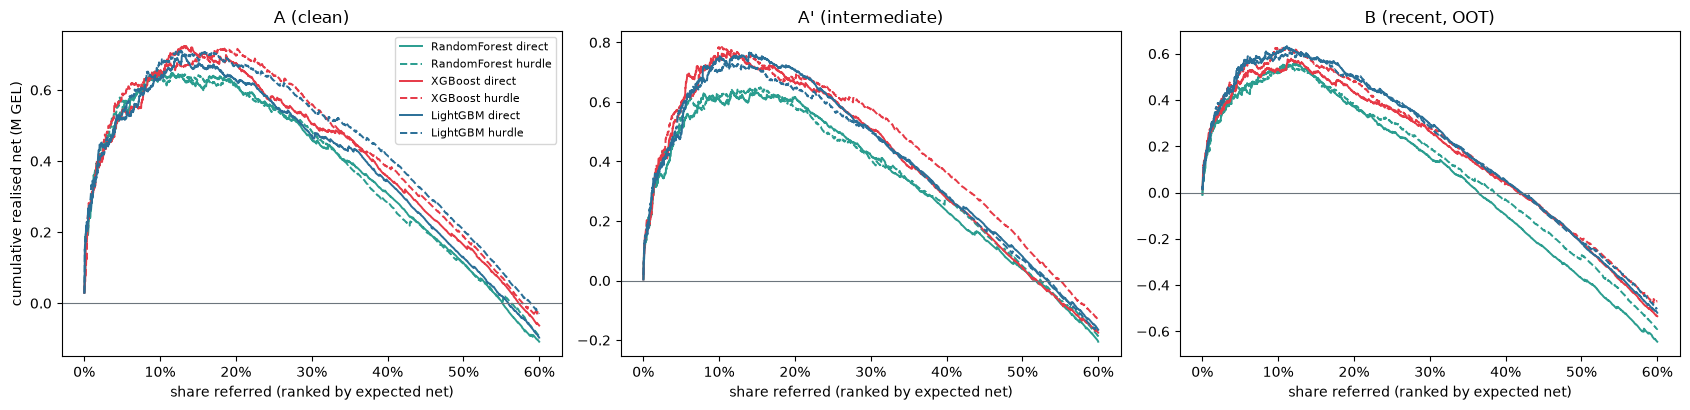

In [56]:
def referred_net(test: pd.DataFrame, pred_rate: np.ndarray, margin: float = 0.0) -> np.ndarray:
    """Realised net per client-period if referred under the rule, else 0."""
    net = expected_net(test["total_outstanding"].to_numpy(), pred_rate)
    return np.where(net > margin, test["net"].to_numpy(), 0.0)


def paired_bootstrap(test: pd.DataFrame, pred_a: np.ndarray, pred_b: np.ndarray, n_boot: int = 2000) -> tuple:
    """Net(A) - net(B) on the same test client-periods, with a 95% bootstrap CI."""
    diff = referred_net(test, pred_a) - referred_net(test, pred_b)
    idx = np.random.default_rng(SEED).integers(0, len(diff), size=(n_boot, len(diff)))
    boot = diff[idx].sum(axis=1)
    return diff.sum(), np.percentile(boot, 2.5), np.percentile(boot, 97.5)


test_a = splits[LAYER_A][1]
ranking_a = model_results.loc[LAYER_A, "net_gel"].sort_values(ascending=False)
leader = ranking_a.index[0]

vs_leader = []
for model in ranking_a.index[1:]:
    diff, lo, hi = paired_bootstrap(test_a, predictions[(LAYER_A, leader)]["pred_rate"].to_numpy(),
                                    predictions[(LAYER_A, model)]["pred_rate"].to_numpy())
    vs_leader.append({"model": model, "leader_minus_model": diff, "ci_low": lo, "ci_high": hi, "tied": lo <= 0 <= hi})
vs_leader = pd.DataFrame(vs_leader).set_index("model")
display(vs_leader.style.format({"leader_minus_model": "{:,.0f}", "ci_low": "{:,.0f}", "ci_high": "{:,.0f}"})
        .set_caption(f"Layer A leader: {leader}"))

hurdle_vs_direct = []
for family in FAMILIES:
    for layer in LAYERS:
        test = splits[layer][1]
        diff, lo, hi = paired_bootstrap(test, predictions[(layer, f"{family} hurdle")]["pred_rate"].to_numpy(),
                                        predictions[(layer, f"{family} direct")]["pred_rate"].to_numpy())
        hurdle_vs_direct.append({"family": family, "layer": layer, "hurdle_minus_direct": diff,
                                 "ci_low": lo, "ci_high": hi})
display(pd.DataFrame(hurdle_vs_direct).set_index(["family", "layer"]).style.format("{:,.0f}"))

ranks = model_results["net_gel"].unstack("layer")[list(LAYERS)].rank(ascending=False)
ranks["mean_rank"] = ranks.mean(axis=1)
tied = [leader] + vs_leader.index[vs_leader["tied"]].tolist()
selection = (ranks.loc[tied]
             .assign(simpler=[0 if m.endswith("direct") else 1 for m in tied])
             .sort_values(["mean_rank", "simpler"]))
display(selection)

TIE_BREAK_MODEL, RUNNER_UP_MODEL = selection.index[0], selection.index[1]
print(f"pre-declared tie-break: {TIE_BREAK_MODEL} | runner-up: {RUNNER_UP_MODEL}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, layer in zip(axes, LAYERS):
    test = splits[layer][1]
    outst, net = test["total_outstanding"].to_numpy(), test["net"].to_numpy()
    share = np.arange(1, len(test) + 1) / len(test)
    visible = share <= 0.6
    for family, color in zip(FAMILIES, ("#2A9D8F", "#E63946", "#2A6F97")):
        for approach, line in zip(APPROACHES, ("-", "--")):
            pred = predictions[(layer, f"{family} {approach}")]["pred_rate"].to_numpy()
            order = np.argsort(-expected_net(outst, pred), kind="stable")
            ax.plot(share[visible], np.cumsum(net[order])[visible] / 1e6, color=color, linestyle=line,
                    linewidth=1.4, label=f"{family} {approach}")
    ax.axhline(0, color="#6C757D", linewidth=0.8)
    ax.set_title(layer)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlabel("share referred (ranked by expected net)")
axes[0].set_ylabel("cumulative realised net (M GEL)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Summary of the modelling results

The goal of the modelling was not simply to predict the recovery rate accurately, but to select the clients whose referral to court will be financially profitable.

### Business result

With the models, the loss-making refer-all result becomes positive in all three periods: in Layer A the net result is about 639 to 699 thousand GEL, in Layer A′ 622 to 751 thousand GEL, and in Layer B 542 to 609 thousand GEL. Compared to the refer-all strategy, the model creates on average 640 to 707 GEL of additional value per client-period.

The models also clearly beat the best simple business rule: in Layer B the combination of outstanding and bureau score gives only about 51 thousand GEL of net result, while the models reach 542 to 609 thousand GEL. This shows that the size of the debt or one strong score alone is not enough for the decision, and the additional value comes from using several features together.

### Why we do not choose the model by AUC alone

The main metric is realised net GEL, because what matters for the business is how much financial value is left after taking recovery and court costs into account. AUC, precision, recall, Spearman correlation and calibration are used as additional diagnostics, but they do not measure the final business result directly. A model can have a good AUC, but if it gives a high score to clients whose court cost is higher than the recovery, such a model will still be ineffective for the business.

### Choice of the final model

At the final stage two models turned out to be especially close: XGBoost hurdle and LightGBM direct. Their financial results are practically identical on all three layers: in Layer A XGBoost hurdle gives about 670 thousand GEL and LightGBM direct 672 thousand GEL; in Layer A′ both reach about 751 thousand GEL, and in Layer B 609 and 604 thousand GEL.

None of these differences is statistically significant: the confidence interval of the paired bootstrap includes 0 on all three layers. In practice the models also behave almost the same, the correlation of their predicted recovery rates is about 0.96, and the referral decisions match in about 97 percent of the client-periods.

Under these conditions **LightGBM direct** was selected as the final model. The reason for the choice is operational simplicity given a statistically equal business result: LightGBM direct is one model that predicts the recovery rate directly, while XGBoost hurdle requires managing two separate components and combining their predictions. So it is simpler for deployment, monitoring and later maintenance, while we lose practically nothing in terms of net GEL.

For transparency I note that the mean rank tie-break defined in advance favored XGBoost hurdle. However, the additional analysis showed that their financial result is statistically identical and the referral decisions also match almost completely, so the final choice was deliberately made in favor of the simpler architecture. XGBoost hurdle stays as the challenger model and is especially interesting under a strict capacity limit, because it shows a small but stable advantage in the top 10 percent selection.

### Result of the selected model

In Layer A, LightGBM direct selects about 15 percent of the client-periods for court referral and the resulting net result is about 672 thousand GEL. In Layer B the net result is about 604 thousand GEL, which means an improvement of about 3.41 million GEL compared to the refer-all strategy. The model significantly reduces the number of cases to be referred to court and at the same time selects cases of much higher quality.

In the most recent Layer B the full 24-month outcome is not yet available and the label is partly based on extrapolation, so the ranking was additionally checked in Layer C, only on the actually observed 6-month results. In this case too the model keeps its signal, which confirms that the ranking is not just an effect of the extrapolated target.

There are small differences between the models, but they are much smaller than the difference the models create compared to the simple rules. The most stable finding is that a multivariate tree based model selects the clients to be referred to court much more effectively than refer-all or simple cutoff rules.

## 7. Sensitivity analysis

In [57]:
SELECTED_MODEL, SELECTED_FAMILY, SELECTED_APPROACH = "LightGBM direct", "LightGBM", "direct"
MARGINS = (0, 100, 250, 500)

best_params = {layer: model_results.loc[(layer, SELECTED_MODEL), "best_params"] for layer in LAYERS}

rows = []
for layer in LAYERS:
    train, test = splits[layer]
    fold_preds = [(val, fit_predict(SELECTED_APPROACH, SELECTED_FAMILY, best_params[layer], fit, val)["pred_rate"])
                  for fit, val in inner_folds(train)]
    test_pred = predictions[(layer, SELECTED_MODEL)]["pred_rate"]
    for margin in MARGINS:
        inner = np.mean([evaluate_model(val, pred, margin=margin)["net_gel"] for val, pred in fold_preds])
        out = evaluate_model(test, test_pred, margin=margin)
        rows.append({"layer": layer, "margin": margin, "inner_net_mean": inner, "test_net": out["net_gel"],
                     "share_referred": out["share_referred"], "precision": out["precision"]})

margin_table = pd.DataFrame(rows).set_index(["layer", "margin"])
display(margin_table.style.format({"inner_net_mean": "{:,.0f}", "test_net": "{:,.0f}",
                                   "share_referred": "{:.1%}", "precision": "{:.1%}"}))
display(margin_table.groupby("margin")["inner_net_mean"].mean().to_frame("mean inner net across layers")
        .style.format("{:,.0f}"))

,mean inner net across layers
margin,
0,"353,525"
100,"348,297"
250,"346,238"
500,"331,499"


In [58]:
rows = []
for layer in LAYERS:
    test = splits[layer][1]
    pred = np.clip(predictions[(layer, SELECTED_MODEL)]["pred_rate"].to_numpy(), 0, 1)
    outst = test["total_outstanding"].to_numpy()
    for name, cost in (("per client-period (base)", test["cost"].to_numpy()),
                       ("per loan", target.loc[test.index, "cost_per_loan"].to_numpy())):
        net = test["rate"].to_numpy() * outst - cost
        refer = pred * outst - cost > 0
        rows.append({"layer": layer, "cost rule": name, "refer_all_net": net.sum(), "model_net": net[refer].sum(),
                     "vs_refer_all": net[refer].sum() - net.sum(), "share_referred": refer.mean(),
                     "profitable_share": (net > 0).mean()})

fee_table = pd.DataFrame(rows).set_index(["layer", "cost rule"])
display(fee_table.style.format({"refer_all_net": "{:,.0f}", "model_net": "{:,.0f}", "vs_refer_all": "{:,.0f}",
                                "share_referred": "{:.1%}", "profitable_share": "{:.1%}"}))

In [59]:
rows = []
for layer in LAYERS:
    train, test = splits[layer]
    full_train = train[train["months_observed"] == 24]
    pred_full = fit_predict(SELECTED_APPROACH, SELECTED_FAMILY, best_params[layer], full_train, test)["pred_rate"]
    for name, pred, n in (("all training rows (>= 12m)", predictions[(layer, SELECTED_MODEL)]["pred_rate"], len(train)),
                          ("fully observed only", pred_full, len(full_train))):
        rows.append({"layer": layer, "training": name, "train_rows": n,
                     **{k: evaluate_model(test, pred)[k] for k in ("net_gel", "share_referred", "precision")}})

train_table = pd.DataFrame(rows).set_index(["layer", "training"])
display(train_table.style.format({"train_rows": "{:,}", "net_gel": "{:,.0f}",
                                  "share_referred": "{:.1%}", "precision": "{:.1%}"}))

In [60]:
rows = []
for layer in LAYERS:
    train, test = splits[layer]
    folds = list(inner_folds(train))
    for n in (150, 300, 600):
        params = {**best_params[layer], "n_estimators": n}
        inner = np.mean([evaluate_model(val, fit_predict(SELECTED_APPROACH, SELECTED_FAMILY, params, fit, val)["pred_rate"])["net_gel"]
                         for fit, val in folds])
        test_net = evaluate_model(test, fit_predict(SELECTED_APPROACH, SELECTED_FAMILY, params, train, test)["pred_rate"])["net_gel"]
        rows.append({"layer": layer, "n_estimators": n, "inner_net_mean": inner, "test_net": test_net})

trees_table = pd.DataFrame(rows).set_index(["layer", "n_estimators"])
display(trees_table.style.format("{:,.0f}"))

To check the robustness of the selected LightGBM direct model we evaluated four alternative scenarios.

**Decision threshold.** We checked whether a client should be sent to court only when the expected net result exceeds a threshold of 0, 100, 250 or 500 GEL. Based on the inner fold results of all three layers, the 0 GEL margin had the best average net. A higher threshold increases precision, but it reduces the number of referred cases and makes the overall financial result worse. So the final rule stays as simple as possible: `Predicted Recovery > Court Cost`.

**Alternative cost scenario.** We checked a stricter assumption, where the fixed cost of 500 GEL is charged to each loan and not to each client-period. In this case the loss of the refer-all strategy grows significantly and the share of profitable clients goes down, while the model automatically becomes more selective and still keeps a positive net result on all three layers. This shows that the decision rule naturally takes the change in cost into account, because the court cost goes directly into the expected net formula.

**Training on fully observed data only.** On Layer B the training sample shrank from 16,790 to 9,023 client-periods, and the net result fell from 603.7 thousand GEL to 507.3 thousand GEL, by about 16 percent. So using the partially observed and extrapolated cases with 12 to 23 months in training really improves the result and supports the earlier decision not to limit ourselves to fully observed data only.

**Number of trees.** For LightGBM we compared 150, 300 and 600 trees. 300 trees show a better result on the inner validation of all three layers, while with 600 trees the result already gets worse, which can be seen as a sign of excess complexity and possible overfitting. So 300 trees is not a value picked by chance at the edge of the tuning grid, but the best configuration in the tested range.

Overall, the sensitivity analysis showed that the selected policy is robust to changes in the main assumptions.

## 8. Interpretation of the results

In [61]:
fitted = {}
for layer in LAYERS:
    train, _ = splits[layer]
    model = make_model(SELECTED_FAMILY, "reg", best_params[layer])
    model.fit(train[PREDICTORS], train["rate"])
    fitted[layer] = model

In [62]:
def segment_performance(test: pd.DataFrame, pred_rate: np.ndarray, groups: dict) -> pd.DataFrame:
    """Net, referral share and precision per segment, against refer-all on the same rows."""
    refer = expected_net(test["total_outstanding"].to_numpy(), pred_rate) > 0
    net, prof = test["net"].to_numpy(), test["profitable"].to_numpy()
    rows = []
    for name, keys in groups.items():
        frame = pd.DataFrame({"key": np.asarray(keys), "net": net, "prof": prof, "refer": refer})
        for key, g in frame.groupby("key", observed=True):
            rows.append({"segment": name, "group": str(key), "client_periods": len(g),
                         "refer_all_net": g["net"].sum(), "model_net": g.loc[g["refer"], "net"].sum(),
                         "share_referred": g["refer"].mean(),
                         "precision": g.loc[g["refer"], "prof"].mean() if g["refer"].any() else np.nan,
                         "profitable_share": g["prof"].mean()})
    out = pd.DataFrame(rows)
    out["vs_refer_all"] = out["model_net"] - out["refer_all_net"]
    return out.set_index(["segment", "group"])


SEG_FMT = {"client_periods": "{:,}", "refer_all_net": "{:,.0f}", "model_net": "{:,.0f}", "vs_refer_all": "{:,.0f}",
           "share_referred": "{:.1%}", "precision": "{:.1%}", "profitable_share": "{:.1%}"}

for layer in (LAYER_A, LAYER_B):
    test = splits[layer][1]
    pred = predictions[(layer, SELECTED_MODEL)]["pred_rate"].to_numpy()
    groups = {
        "outstanding quintile": pd.qcut(test["total_outstanding"], 5, labels=[f"Q{i}" for i in range(1, 6)]),
        "n_loans": target.loc[test.index, "n_loans"].clip(upper=4).map(lambda n: "4+" if n == 4 else str(n)).to_numpy(),
        "prior case": np.where(test["has_prior_case"] == 0, "none",
                               np.where(test["prior_rate_known"] > 0, "paid before", "nothing paid before")),
        "declared income": np.where(test["feature_039"].isna(), "missing", "present"),
        "deposit balance": np.where(test["feature_011"].isna(), "missing", "present"),
    }
    display(segment_performance(test, pred, groups).style.format(SEG_FMT).set_caption(layer))

In [63]:
test = splits[LAYER_B][1]
pred = np.clip(predictions[(LAYER_B, SELECTED_MODEL)]["pred_rate"].to_numpy(), 0, 1)
refer = expected_net(test["total_outstanding"].to_numpy(), pred) > 0
err = (test.assign(pred_rate=pred, referred=refer)
           [["total_outstanding", "rate", "pred_rate", "net", "referred", "months_observed"]])

losses = err[err["referred"] & (err["net"] < 0)]
missed = err[~err["referred"] & (err["net"] > 0)]
zero_big = losses[(losses["rate"] == 0) & (losses["total_outstanding"] > losses["total_outstanding"].median())]

print(f"referred: {refer.sum():,} | losing referrals: {len(losses):,} ({len(losses) / refer.sum():.1%}), total loss {losses['net'].sum():,.0f}")
print(f"not referred but profitable: {len(missed):,}, forgone profit {missed['net'].sum():,.0f}")
print(f"large zero-recovery cases: {len(zero_big):,} = {zero_big['net'].sum() / losses['net'].sum():.1%} of referred losses")

ERR_FMT = {"total_outstanding": "{:,.0f}", "rate": "{:.3f}", "pred_rate": "{:.3f}", "net": "{:,.0f}"}
display(losses.nsmallest(10, "net").style.format(ERR_FMT))
display(missed.nlargest(10, "net").style.format(ERR_FMT))

not_referred = err[~err["referred"]]
cost_avoided = (COST_FIXED + COST_PCT * not_referred["total_outstanding"]).sum()
recovery_forgone = (not_referred["rate"] * not_referred["total_outstanding"]).sum()
print(f"cost avoided {cost_avoided:,.0f} minus recovery forgone {recovery_forgone:,.0f} = {cost_avoided - recovery_forgone:,.0f}")

referred: 626 | losing referrals: 359 (57.3%), total loss -548,356
not referred but profitable: 427, forgone profit 708,802
large zero-recovery cases: 112 = 49.1% of referred losses


,,total_outstanding,rate,pred_rate,net,referred,months_observed
CLIENT_KEY,PERIOD,,,,,,
716702,2025/11,"99,871",0.000,0.250,"-10,487",True,9
720472,2026/01,"56,936",0.003,0.217,"-6,016",True,7
711037,2025/10,"55,159",0.000,0.188,"-6,016",True,10
705072,2025/11,"48,883",0.000,0.138,"-5,388",True,9
710620,2025/09,"46,852",0.000,0.161,"-5,185",True,11
714733,2026/01,"46,168",0.000,0.285,"-5,117",True,7
704482,2025/12,"39,046",0.000,0.150,"-4,405",True,8
704685,2025/11,"37,985",0.000,0.148,"-4,298",True,9
716662,2025/11,"36,696",0.000,0.268,"-4,170",True,9


,,total_outstanding,rate,pred_rate,net,referred,months_observed
CLIENT_KEY,PERIOD,,,,,,
701181,2025/12,"25,625",0.708,0.053,"15,070",False,8
706094,2025/12,"26,561",0.621,0.107,"13,349",False,8
707609,2025/11,"16,102",0.898,0.019,"12,345",False,9
721146,2025/11,"18,196",0.724,0.099,"10,853",False,9
700275,2025/09,"15,110",0.758,0.039,"9,441",False,11
701783,2025/10,"17,793",0.626,0.100,"8,864",False,10
721427,2026/01,"14,501",0.735,0.041,"8,702",False,7
714180,2025/09,"20,236",0.542,0.049,"8,439",False,11
710600,2025/11,"22,782",0.459,0.112,"7,678",False,9


cost avoided 4,874,991 minus recovery forgone 1,465,708 = 3,409,282


,gain_share,mean_abs_shap,net_drop_mean,group
feature_039,12.0%,0.0292,"201,010",declared income
feature_019,8.9%,0.0212,"133,381",repayment history on other loans
feature_031,8.6%,0.0205,"124,224",credit bureau history
feature_034,6.8%,0.0164,"114,164",credit bureau history
feature_012,6.8%,0.0178,"147,228",account balances
feature_011,6.3%,0.0146,"135,918",account balances
feature_003,5.2%,0.0155,"118,098",transaction activity
feature_021,4.0%,0.0132,"43,833",repayment history on other loans
feature_036,3.1%,0.0123,"55,324",credit bureau history
feature_006,3.1%,0.0100,"58,031",transaction activity


,gain_share
group,
account balances,20.9%
credit bureau history,20.7%
repayment history on other loans,20.3%
declared income,15.1%
transaction activity,11.6%
digital channel usage,4.7%
recent credit applications,3.8%
engineered,2.9%


,net_drop_mean,net_drop_sd
feature,,
feature_039,"201,010","44,230"
feature_012,"147,228","33,537"
feature_011,"135,918","28,658"
feature_019,"133,381","18,205"
feature_031,"124,224","20,708"
feature_003,"118,098","11,144"
feature_034,"114,164","29,139"
feature_006,"58,031","22,736"
feature_036,"55,324","16,534"


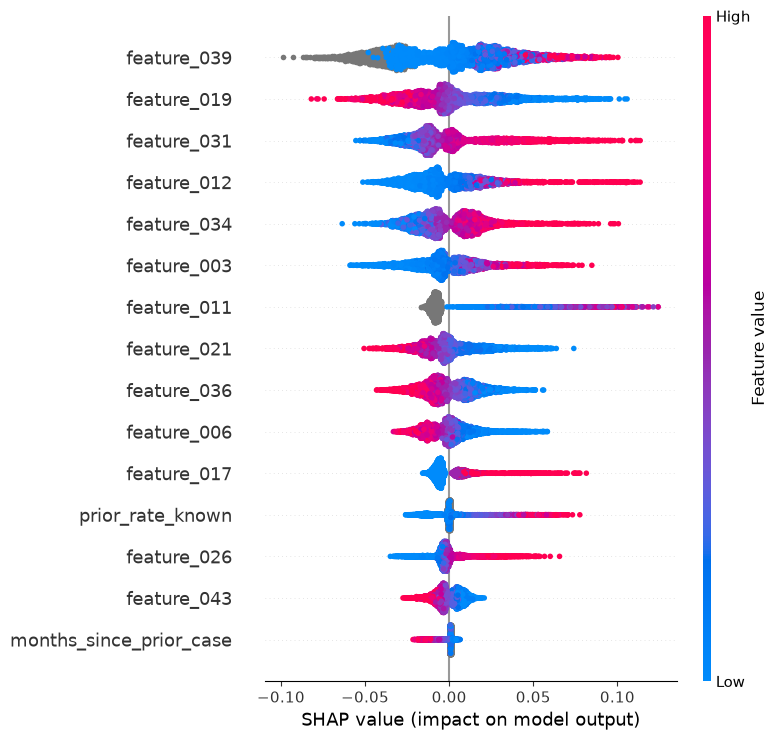

,shap_direction,spearman_with_rate,description
feature_039,+1,0.109,Declared monthly income stated at the client's last credit application.
feature_019,-1,-0.149,Share of scheduled instalments paid late over the last 12 months.
feature_031,+1,0.157,Credit bureau score at the last refresh before enforcement.
feature_012,+1,0.149,"Maximum end-of-day total balance across all accounts, 6 months."
feature_034,+1,0.162,Internal behavioural score at the last monthly refresh before enforcement.
feature_003,+1,0.082,"Total credit turnover across all accounts, monthly average over 3 months."
feature_011,+1,0.080,"Average end-of-month savings and deposit balance, 6 months. Populated only for customers holding a deposit or savings product."
feature_021,-1,-0.121,"Number of times 30+ days past due on any facility, last 24 months."
feature_036,-1,0.003,Share of total bureau-reported exposure that is currently overdue.
feature_006,-1,0.012,"Share of cash withdrawals in total account outflow, 9 months."


In [64]:
test = splits[LAYER_B][1]
model = fitted[LAYER_B]
gain = model.booster_.feature_importance("gain")
gain_share = pd.Series(gain / gain.sum(), index=PREDICTORS, name="gain_share")

rng = np.random.default_rng(SEED)
base_net = evaluate_model(test, model.predict(test[PREDICTORS]))["net_gel"]
perm_rows = []
for col in PREDICTORS:
    drops = []
    for _ in range(3):
        X = test[PREDICTORS].copy()
        X[col] = rng.permutation(X[col].to_numpy())
        drops.append(base_net - evaluate_model(test, model.predict(X))["net_gel"])
    perm_rows.append({"feature": col, "net_drop_mean": np.mean(drops), "net_drop_sd": np.std(drops)})
perm = pd.DataFrame(perm_rows).set_index("feature").sort_values("net_drop_mean", ascending=False)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(test[PREDICTORS])
shap_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=PREDICTORS, name="mean_abs_shap")

dict_group = feat_dict.set_index("column")["group"]
dict_description = feat_dict.set_index("column")["description"]

importance = pd.concat([gain_share, shap_abs, perm["net_drop_mean"]], axis=1)
importance["group"] = [dict_group.get(f, "engineered") for f in importance.index]
display(importance.sort_values("gain_share", ascending=False).head(15)
        .style.format({"gain_share": "{:.1%}", "mean_abs_shap": "{:.4f}", "net_drop_mean": "{:,.0f}"}))
display(importance.groupby("group")["gain_share"].sum().sort_values(ascending=False).to_frame().style.format("{:.1%}"))
display(perm.head(10).style.format("{:,.0f}"))

shap.summary_plot(shap_values, test[PREDICTORS], max_display=15)

top = importance.sort_values("mean_abs_shap", ascending=False).head(10).index
shap_df = pd.DataFrame(shap_values, columns=PREDICTORS, index=test.index)
direction = pd.DataFrame({
    "shap_direction": [np.sign(test[c].corr(shap_df[c], method="spearman")) for c in top],
    "spearman_with_rate": [test[c].corr(test["rate"], method="spearman") for c in top],
    "description": [dict_description.get(c, "engineered feature") for c in top],
}, index=top)
display(direction.style.format({"shap_direction": "{:+.0f}", "spearman_with_rate": "{:.3f}"}))

In [65]:
test = splits[LAYER_B][1]
pred = np.clip(predictions[(LAYER_B, SELECTED_MODEL)]["pred_rate"].to_numpy(), 0, 1)
decile = pd.qcut(pd.Series(pred, index=test.index).rank(method="first"), 10, labels=range(1, 11))
calibration = test.assign(pred_rate=pred, decile=decile).groupby("decile", observed=True).apply(
    lambda g: pd.Series({"client_periods": len(g), "mean_pred_rate": g["pred_rate"].mean(),
                         "actual_pooled_rate": (g["rate"] * g["total_outstanding"]).sum() / g["total_outstanding"].sum(),
                         "profitable_share": g["profitable"].mean(), "net_if_all_referred": g["net"].sum()}))
display(calibration.style.format({"client_periods": "{:,.0f}", "mean_pred_rate": "{:.1%}",
                                  "actual_pooled_rate": "{:.1%}", "profitable_share": "{:.1%}",
                                  "net_if_all_referred": "{:,.0f}"}))

,client_periods,mean_pred_rate,actual_pooled_rate,profitable_share,net_if_all_referred
decile,,,,,
1,483,0.2%,1.0%,0.8%,"-565,790"
2,483,1.6%,1.7%,2.5%,"-548,036"
3,483,3.2%,3.4%,5.4%,"-488,567"
4,483,4.7%,4.9%,6.6%,"-419,597"
5,483,6.5%,4.9%,9.7%,"-434,278"
6,483,8.6%,5.5%,13.3%,"-403,018"
7,483,11.2%,9.7%,14.7%,"-252,029"
8,483,14.6%,13.6%,21.7%,"-119,943"
9,483,19.7%,18.8%,26.5%,"47,507"


### Analysis and interpretation of the results

The selected LightGBM direct model improves the financial result compared to the refer-all strategy in all the main segments, but its effect differs considerably between groups.

The shortest business interpretation is this: on Layer B the model selects only 13 percent of the clients for court referral. These clients account for about 22 percent of the total outstanding and 53 percent of the possible recovery of the portfolio, while we pay only 18 percent of the court cost. In other words, compared to the refer-all strategy we save about 82 percent of the court cost and give up 47 percent of the recovery in return. The positive difference between these two effects is what creates the financial value of the model, which on Layer B is about 706 GEL per client-period on average.

| Metric | Layer A | Layer B |
| --- | ---: | ---: |
| Share of clients referred to court | 15.3% | 13.0% |
| Their share of total outstanding | 26.4% | 21.6% |
| Share of total recovery kept | 58.2% | 53.4% |
| Share of the refer-all court cost spent | 21.9% | 18.1% |
| Share of profitable cases kept | 43.0% | 38.5% |
| Loss-making among the referred | 54.3% | 57.4% |
| Below the break-even threshold | 4.8% | 4.7% |

### Behavior by segment

The size of the debt plays an important role in the final decision. In the first quintile, with the smallest outstanding, the model refers only 0.3 percent of the clients, then the referral rate grows consistently and reaches 27.3 percent in the fifth quintile. This follows naturally from the structure of the court cost, because for a large debt the share of the fixed cost of 500 GEL becomes much smaller.

With a previous court case too, what matters is not its existence but the client's historical behavior. Among those who paid on the previous case, the model refers 17.2 percent and the precision is 44.7 percent. Among the clients who paid nothing on the previous case, the referral rate is only 7.0 percent and the precision drops to 24.6 percent. The latter is the only significant segment where the result on Layer B is still negative, so for this group an additional threshold or manual review could be considered in the future.

Missing values also carry important information. Among the clients without declared income the referral rate is only 1.7 percent, which matches the low profitability of this group, 7.1 percent. In contrast, among the clients with a deposit the referral rate is 30.4 percent and the precision reaches 47 percent. This is the only large segment where even the refer-all strategy gives a positive financial result.

### Where the model makes mistakes

On Layer B about 57 percent of the referred cases end up loss-making, but the financial result of the remaining profitable 43 percent fully covers this loss.

The most important risk is concentrated in a relatively small number of large cases: about 49 percent of the total loss comes from the cases where the outstanding is high but the actual recovery is zero. Such cases make up about 18 percent of the referred cases.

On the other side are the missed opportunities: the model does not refer about 61 percent of the cases that are actually profitable. Among them are clients who eventually repaid a significant part of the debt, but the model predicted a low recovery rate for them. So the task for further improvement has two sides: we need to recognize the large zero recovery cases better and at the same time miss fewer of the clients with high recovery.

### Which information matters most

About 60 percent of the predictive signal is split across three groups: account balances about 21 percent, credit bureau history about 21 percent and payment history on other loans about 20 percent. Next come declared income with about 15 percent and transaction activity with about 12 percent. The information on digital channels and recent credit applications adds relatively little value.

The strongest single feature is `feature_039`, declared income: its gain is about 12 percent, and by permutation importance losing this information makes the net result about one third worse.

Among the derived variables the most valuable turned out to be `prior_rate_known`, followed by `months_since_prior_case` and `total_outstanding`. `has_prior_case` adds practically no information, which also confirms the EDA result: what matters is not whether the client had a previous court case, but how the client behaved during that case.

### Consistency with business logic

The directions of the most important features match business intuition. Higher income, a better credit score, higher balances, more turnover and having a deposit increase the expected recovery. In contrast, a high share of late instalments, delinquencies of more than 30 days, a high share of overdue exposure and a high share of cash withdrawals reduce recovery. This matters for the credibility of the model, because the result is based on economically explainable patterns and not only on technically discovered relationships.

### Calibration and ranking

Across the deciles of predicted recovery the actual recovery grows almost monotonically from about 1 percent to 27 percent, while the share of profitable cases is 0.8 percent in the first decile and reaches about 42 percent in the last one.

The financial value is concentrated practically entirely in the top deciles: if the department can only process 10 percent of the clients, the model keeps almost the full net result. This is especially important under limited operational capacity.

At the same time, in the highest decile the model slightly overestimates recovery: the prediction is about 31.3 percent, while the actual result is 27.4 percent. This matches the calibration coefficient of 0.92 on Layer B and should stay one of the main monitoring indicators.

### Strengths and weaknesses

The main strength of the model is the significant financial improvement compared to the refer-all strategy, about 632 to 706 GEL per client-period. The ranking also works on actually observed short-term outcomes, the directions of the features match business logic, the results stay stable under the sensitivity analysis, and the economic value is strongly concentrated in the best cases.

The main limitation is that the model uses only about 29 to 40 percent of the oracle potential. 57 percent of the referred cases are still loss-making, a large part of the loss comes from a few large zero recovery cases, a significant part of the profitable cases is missed, and recovery is slightly overestimated on the most recent cohorts.

Finally, all historical evaluations are based only on the clients who had already been selected for court referral by the expert rule. So with this data we cannot assess whether there are additional profitable clients in the population rejected by the expert.

## 9. Decision rule and backtest

In [66]:
MARGIN = 0.0
ALWAYS_MISSING_OK = ["feature_011", "feature_039", "months_since_prior_case", "prior_months_known", "prior_rate_known"]
CRITICAL_PREDICTORS = [c for c in PREDICTORS if c not in ALWAYS_MISSING_OK]


def apply_decision_rule(frame: pd.DataFrame, pred_rate: np.ndarray, margin: float = MARGIN,
                        capacity: int | None = None) -> pd.DataFrame:
    """Rank a monthly batch and decide who goes to court.
    Refer if expected_net > margin; never below the break-even balance; rows with missing critical
    inputs go to manual handling. With a capacity limit only the top-K positive cases are referred."""
    pred_rate = np.clip(np.asarray(pred_rate, dtype=float), 0, 1)
    outst = frame["total_outstanding"].to_numpy()
    cost = COST_FIXED + COST_PCT * outst
    net = pred_rate * outst - cost

    needs_manual = frame[CRITICAL_PREDICTORS].isna().any(axis=1).to_numpy()
    below_break_even = outst < BREAK_EVEN
    conditions = [needs_manual, below_break_even, net > margin]

    out = pd.DataFrame({"total_outstanding": outst, "pred_rate": pred_rate, "court_cost": cost,
                        "expected_net": net}, index=frame.index)
    out["decision"] = np.select(conditions, ["manual review", "no-go", "refer"], default="no-go")
    out["reason"] = np.select(
        conditions,
        ["missing critical inputs", f"outstanding below break-even ({BREAK_EVEN:,.0f} GEL)", "expected net above margin"],
        default="expected net below margin")

    order = out.assign(_client=out.index.get_level_values("CLIENT_KEY")).sort_values(
        ["expected_net", "total_outstanding", "_client"], ascending=[False, False, True]).index
    out["rank"] = pd.Series(range(1, len(out) + 1), index=order)

    if capacity is not None:
        over_capacity = (out["decision"] == "refer") & (out["rank"] > capacity)
        out.loc[over_capacity, ["decision", "reason"]] = ["no-go", "capacity limit"]
    return out.sort_values("rank")

In [67]:
rows = []
for layer in (LAYER_A, LAYER_B):
    test = splits[layer][1]
    decisions = apply_decision_rule(test, predictions[(layer, SELECTED_MODEL)]["pred_rate"].to_numpy())
    referred = decisions["decision"].eq("refer").reindex(test.index).to_numpy()
    net, rate, outst = test["net"].to_numpy(), test["rate"].to_numpy(), test["total_outstanding"].to_numpy()
    cost = COST_FIXED + COST_PCT * outst
    rows.append({"layer": layer, "client_periods": len(test), "referred": referred.sum(),
                 "share_referred": referred.mean(), "model_net": net[referred].sum(), "refer_all_net": net.sum(),
                 "vs_refer_all": net[referred].sum() - net.sum(),
                 "court_cost_avoided": cost[~referred].sum(), "recovery_forgone": (rate * outst)[~referred].sum(),
                 "court_cost_spent": cost[referred].sum(), "recovery_collected": (rate * outst)[referred].sum()})

backtest = pd.DataFrame(rows).set_index("layer")
backtest["identity_check"] = backtest["court_cost_avoided"] - backtest["recovery_forgone"] - backtest["vs_refer_all"]
display(backtest.style.format({c: "{:,.0f}" for c in backtest.columns if c != "share_referred"}
                              | {"share_referred": "{:.1%}"}))

for layer in (LAYER_A, LAYER_B):
    test = splits[layer][1]
    d = apply_decision_rule(test, predictions[(layer, SELECTED_MODEL)]["pred_rate"].to_numpy())
    display(d.groupby(["decision", "reason"]).size().to_frame("client_periods").style.set_caption(layer))

,client_periods,referred,share_referred,model_net,refer_all_net,vs_refer_all,court_cost_avoided,recovery_forgone,court_cost_spent,recovery_collected,identity_check
layer,,,,,,,,,,,
A (clean),"3,514",536,15.3%,"671,621","-1,547,985","2,219,606","3,382,792","1,163,186","946,437","1,618,059",0
"B (recent, OOT)","4,830",626,13.0%,"603,706","-2,805,577","3,409,282","4,874,991","1,465,708","1,076,221","1,679,926",0


In [68]:
LOCO_MAE_6M = 0.0157
noise_sd = LOCO_MAE_6M * 1.2533

test = splits[LAYER_B][1]
pred = np.clip(predictions[(LAYER_B, SELECTED_MODEL)]["pred_rate"].to_numpy(), 0, 1)
outst = test["total_outstanding"].to_numpy()
cost = COST_FIXED + COST_PCT * outst
simple_rule = baseline_params.loc[(LAYER_B, "outstanding + bureau score")]
rng = np.random.default_rng(SEED)

policies = {
    "model rule": pred * outst - cost > 0,
    "outstanding + bureau score": ((test["total_outstanding"] >= simple_rule["min_outstanding"])
                                   & (test["feature_031"] >= simple_rule["min_feature_031"])).to_numpy(),
    "refer-all": np.ones(len(test), bool),
}

stress = {name: [] for name in policies}
for _ in range(300):
    noisy_net = np.clip(test["rate"].to_numpy() + rng.normal(0, noise_sd, len(test)), 0, 1) * outst - cost
    for name, refer in policies.items():
        stress[name].append(noisy_net[refer].sum())

display(pd.DataFrame({n: {"mean": np.mean(v), "p5": np.percentile(v, 5), "p95": np.percentile(v, 95)}
                      for n, v in stress.items()}).T.style.format("{:,.0f}"))

,mean,p5,p95
model rule,"629,974","619,699","640,416"
outstanding + bureau score,"71,312","63,730","79,388"
refer-all,"-2,617,323","-2,635,602","-2,599,448"


In [69]:
batch_period = model_frame.index.get_level_values("PERIOD").max()
batch = model_frame[model_frame.index.get_level_values("PERIOD") == batch_period]
batch_pred = fitted[LAYER_B].predict(batch[PREDICTORS])

scored = apply_decision_rule(batch, batch_pred)
display(scored.groupby(["decision", "reason"]).size().to_frame("client_periods").style.set_caption(f"batch {batch_period}"))
print(f"expected net of referred: {scored.loc[scored['decision'] == 'refer', 'expected_net'].sum():,.0f} GEL")

capped = apply_decision_rule(batch, batch_pred, capacity=100)
print(f"expected net under a capacity of 100 cases: {capped.loc[capped['decision'] == 'refer', 'expected_net'].sum():,.0f} GEL")

display(scored.head(10).style.format({"total_outstanding": "{:,.0f}", "pred_rate": "{:.2f}",
                                      "court_cost": "{:,.0f}", "expected_net": "{:,.0f}"}))

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
scored.to_csv(OUTPUTS_DIR / f"scored_batch_{batch_period.replace('/', '_')}.csv")

expected net of referred: 123,748 GEL
expected net under a capacity of 100 cases: 123,349 GEL


,,total_outstanding,pred_rate,court_cost,expected_net,decision,reason,rank
CLIENT_KEY,PERIOD,,,,,,,
714652,2026/02,"42,621",0.33,"4,762","9,460",refer,expected net above margin,1
718982,2026/02,"34,661",0.35,"3,966","8,111",refer,expected net above margin,2
701948,2026/02,"22,841",0.42,"2,784","6,733",refer,expected net above margin,3
719779,2026/02,"19,599",0.46,"2,460","6,507",refer,expected net above margin,4
717004,2026/02,"26,333",0.32,"3,133","5,274",refer,expected net above margin,5
710746,2026/02,"29,481",0.28,"3,448","4,703",refer,expected net above margin,6
719105,2026/02,"19,227",0.32,"2,423","3,754",refer,expected net above margin,7
706303,2026/02,"30,935",0.23,"3,593","3,439",refer,expected net above margin,8
721563,2026/02,"14,938",0.36,"1,994","3,417",refer,expected net above margin,9


### Decision rule

A client is referred to court only when the predicted recovery exceeds the expected court cost:

`expected_net = predicted rate × total_outstanding - (500 + 10% × total_outstanding)`

The final threshold is 0 GEL, so any positive expected net result is enough for a referral.

A few hard business rules apply independently of the model. If `total_outstanding` is below 556 GEL, the case is not referred to court, because even a 100 percent recovery would not cover the cost. If critical information is missing, the case is not automatically classified as negative and goes to manual review. At the same time, missing values that are explained by business logic, such as `feature_011`, `feature_039` and the prior case variables, are not treated as critical missing values.

Each month the eligible cases are sorted by `expected_net` in descending order. If operational capacity is limited, only the top K cases with the best positive net are referred to court.

### Backtest result

In Layer A the model selects 536 cases out of 3,514 client-periods, or 15.3 percent, and the resulting net result is about 671.6 thousand GEL, which is an improvement of 2.22 million GEL compared to the refer-all strategy. In Layer B the model selects 626 cases out of 4,830 client-periods, about 13 percent, the net result is 603.7 thousand GEL, and the improvement reaches 3.41 million GEL.

In Layer B this improvement breaks down directly into two components: about 4.87 million GEL of court cost is saved on the cases that are not referred, while the recovery given up on the same cases is about 1.47 million GEL. The difference is exactly 3.41 million GEL. This shows the business logic of the model well: value is created not only by finding good cases, but especially by avoiding loss-making court processes.

### Robustness to target uncertainty

To account for the possible error of the extrapolation, we ran a noise sensitivity simulation on the target. Even with a random error of about 2 percentage points the net result of the model stays between 620 and 640 thousand GEL, while the result of the best simple rule is only 64 to 79 thousand GEL, and refer-all still gives a loss of about 2.6 million GEL. So a realistic level of extrapolation uncertainty does not change the main business conclusion either.

### Practical example on the latest cohort

In the 2026/02 cohort the model selects 111 cases out of 841 client-periods for court referral, or 13.2 percent, and their total expected net is about 123.7 thousand GEL. 31 cases are excluded automatically because of the break-even rule.

If the capacity of the department is only 100 cases, the expected net stays at about 123.3 thousand GEL. So the last 11 cases add almost no financial value, which shows that the ranking correctly concentrates the best opportunities at the top of the list.

## 10. Potential business benefit

We translate the backtest result into an annual financial effect: we multiply the volume of candidates in the last 12 cohorts by the improvement per candidate. The benefit is decomposed in two independent ways and both decompositions have to match each other exactly, which checks that the result is not an accounting artifact.

In [71]:
BENEFIT_COHORTS = 12

cohort_periods = sorted(model_frame.index.get_level_values("PERIOD").unique())
benefit_window = cohort_periods[-BENEFIT_COHORTS:]
annual_volume = int(model_frame.index.get_level_values("PERIOD").isin(benefit_window).sum())
monthly_volume = annual_volume / BENEFIT_COHORTS


def policy_split(test: pd.DataFrame, pred_rate: np.ndarray, cost: np.ndarray, rate: np.ndarray):
    """Referral decision and realised net per client-period under a given cost and recovery scenario."""
    outst = test["total_outstanding"].to_numpy()
    refer = np.clip(pred_rate, 0, 1) * outst - cost > 0
    return refer, rate * outst - cost, outst


def benefit_breakdown(test: pd.DataFrame, pred_rate: np.ndarray) -> dict:
    """Uplift against refer-all, its two exact decompositions, and the annualised figure."""
    cost, rate = test["cost"].to_numpy(), test["rate"].to_numpy()
    refer, net, outst = policy_split(test, pred_rate, cost, rate)
    skipped = ~refer
    uplift = net[refer].sum() - net.sum()
    return {
        "test_client_periods": len(test),
        "share_referred": refer.mean(),
        "uplift_total": uplift,
        "uplift_per_candidate": uplift / len(test),
        "annual_candidates": annual_volume,
        "annual_benefit": uplift / len(test) * annual_volume,
        "court_cost_avoided": cost[skipped].sum(),
        "recovery_forgone": (rate * outst)[skipped].sum(),
        "avoided_losses": -net[skipped & (net < 0)].sum(),
        "forgone_profit": net[skipped & (net > 0)].sum(),
    }


benefit = pd.DataFrame({layer: benefit_breakdown(splits[layer][1],
                                                 predictions[(layer, SELECTED_MODEL)]["pred_rate"].to_numpy())
                        for layer in (LAYER_A, LAYER_B)}).T
benefit["identity_cash"] = benefit["court_cost_avoided"] - benefit["recovery_forgone"] - benefit["uplift_total"]
benefit["identity_cases"] = benefit["avoided_losses"] - benefit["forgone_profit"] - benefit["uplift_total"]

print(f"candidate volume, {benefit_window[0]} to {benefit_window[-1]}: {annual_volume:,} client-periods ({monthly_volume:,.0f} per month)")
display(benefit.style.format({"test_client_periods": "{:,.0f}", "annual_candidates": "{:,.0f}",
                              "share_referred": "{:.1%}"} |
                             {c: "{:,.0f}" for c in benefit.columns
                              if c not in ("test_client_periods", "annual_candidates", "share_referred")}))

candidate volume, 2025/03 to 2026/02: 9,244 client-periods (770 per month)


,test_client_periods,share_referred,uplift_total,uplift_per_candidate,annual_candidates,annual_benefit,court_cost_avoided,recovery_forgone,avoided_losses,forgone_profit,identity_cash,identity_cases
A (clean),"3,514",15.3%,"2,219,606",632,"9,244","5,838,941","3,382,792","1,163,186","2,821,218","601,612",0,-0
"B (recent, OOT)","4,830",13.0%,"3,409,282",706,"9,244","6,524,929","4,874,991","1,465,708","4,118,085","708,802",0,0


In [72]:
def scenario_benefit(test: pd.DataFrame, pred_rate: np.ndarray, cost: np.ndarray,
                     rate: np.ndarray, refer: np.ndarray | None = None) -> dict:
    """Benefit under an alternative cost or recovery assumption; the rule re-optimises against the new cost."""
    fitted_refer, net, _ = policy_split(test, pred_rate, cost, rate)
    refer = fitted_refer if refer is None else refer
    uplift = net[refer].sum() - net.sum()
    return {"refer_all_net": net.sum(), "policy_net": net[refer].sum(), "share_referred": refer.mean(),
            "uplift_per_candidate": uplift / len(test), "annual_benefit": uplift / len(test) * annual_volume}


scenario_rows = []
for layer in (LAYER_A, LAYER_B):
    test = splits[layer][1]
    pred = predictions[(layer, SELECTED_MODEL)]["pred_rate"].to_numpy()
    base_cost, base_rate = test["cost"].to_numpy(), test["rate"].to_numpy()
    scenarios = {
        "base": (base_cost, base_rate, None),
        "per-loan fee": (target.loc[test.index, "cost_per_loan"].to_numpy(), base_rate, None),
        "recovery -20%": (base_cost, np.clip(base_rate * 0.8, 0, 1), None),
        "recovery +20%": (base_cost, np.clip(base_rate * 1.2, 0, 1), None),
        "oracle ceiling": (base_cost, base_rate, test["profitable"].to_numpy()),
    }
    for name, (cost, rate, refer) in scenarios.items():
        scenario_rows.append({"layer": layer, "scenario": name,
                              **scenario_benefit(test, pred, cost, rate, refer)})

benefit_scenarios = pd.DataFrame(scenario_rows).set_index(["layer", "scenario"])
display(benefit_scenarios.style.format({"refer_all_net": "{:,.0f}", "policy_net": "{:,.0f}",
                                        "share_referred": "{:.1%}", "uplift_per_candidate": "{:,.0f}",
                                        "annual_benefit": "{:,.0f}"}))

ASSUMPTIONS = [
    ("candidate volume", f"{annual_volume:,} client-periods per year",
     f"in-scope cohorts {benefit_window[0]} to {benefit_window[-1]}", "linear: benefit scales with volume"),
    ("uplift per candidate", "Layer A and Layer B backtest",
     "realised net minus refer-all net, divided by test rows", "Layer B is the conservative figure"),
    ("court cost", "500 GEL + 10% of total_outstanding", "task brief",
     "per-loan fee shown as a separate scenario"),
    ("recovery horizon", "24 months from enforcement start", "task brief",
     "post-24m tail not modelled, so the benefit is understated"),
    ("non-referred recovery", "assumed zero", "no court process means no enforced recovery",
     "voluntary payments would raise the benefit"),
    ("discounting", "none, nominal GEL", "simplification",
     "cost is up front and recovery is slow, so discounting lowers the benefit"),
    ("population", "expert-approved unsecured client-periods only", "historical data",
     "no claim about expert-rejected clients"),
]
display(pd.DataFrame(ASSUMPTIONS, columns=["assumption", "value", "source", "sensitivity"]).set_index("assumption"))

,value,source,sensitivity
assumption,,,
candidate volume,"9,244 client-periods per year",in-scope cohorts 2025/03 to 2026/02,linear: benefit scales with volume
uplift per candidate,Layer A and Layer B backtest,"realised net minus refer-all net, divided by t...",Layer B is the conservative figure
court cost,500 GEL + 10% of total_outstanding,task brief,per-loan fee shown as a separate scenario
recovery horizon,24 months from enforcement start,task brief,"post-24m tail not modelled, so the benefit is ..."
non-referred recovery,assumed zero,no court process means no enforced recovery,voluntary payments would raise the benefit
discounting,"none, nominal GEL",simplification,"cost is up front and recovery is slow, so disc..."
population,expert-approved unsecured client-periods only,historical data,no claim about expert-rejected clients


In the last 12 cohorts (2025/03 to 2026/02) the volume of in-scope candidates is **9,244 client-periods**, or 770 per month on average. The improvement per candidate compared to the refer-all strategy is 632 GEL on Layer A and 706 GEL on Layer B, which gives an annual benefit of **5.84 million GEL** and **6.52 million GEL**. We take Layer B as the conservative estimate, because it relies on the most recent cohorts, where the overall level of recovery is lower.

The benefit is decomposed in two independent ways and both give exactly the same number (Layer B):

| Decomposition | Calculation | Result |
| --- | --- | ---: |
| Cash | Court cost saved 4,874,991 minus recovery given up 1,465,708 | 3,409,282 |
| Cases | Loss avoided 4,118,085 minus profit missed 708,802 | 3,409,282 |

The `identity_cash` and `identity_cases` columns are equal to zero, which confirms that the benefit is fully explained by the difference between these two effects.

The scenario results show that the conclusion is robust. Under the per-loan cost the rule becomes much more selective (referral falls from 13% to 6%), but the benefit grows to 12.19 million GEL, because refer-all becomes much more loss-making. If the real recovery gets 20% worse, the benefit grows to 7.09 million, and if it improves by 20%, it goes down to 5.98 million. So the worse the environment, the higher the value of the model, which is logical: avoiding the cost is worth the most when the recovery prospects are weak.

The ceiling of ideal selection is 8.93 million GEL in annual terms, so the rule captures about three quarters of this additional value. Note that in terms of realised net the same comparison gives 32%: the difference comes from the fact that the uplift is counted from the loss of refer-all, while realised net measures the absolute result. Both numbers are correct, they just answer different questions.

**What this number means and what it does not.** 6.52 million GEL is the final 24-month value of one year's flow and not the cash flow of the coming year. The cost is saved right away, while the recovery accumulates over 24 months, so discounting would reduce the result. The 1.47 million GEL of recovery given up is a real loss and the business has to accept this trade-off consciously. Finally, the calculation applies only to the population already approved by the expert.

## 11. Pilot campaign plan

The backtest compares the model with the refer-all strategy on historical data, but it cannot check three assumptions: that a client who is not referred really pays nothing, that the production pipeline produces the same prediction, and that no additional profitable clients are hidden among those rejected by the expert. Checking these three is only possible with a prospective experiment.

In [73]:
PILOT_ALPHA, PILOT_POWER = 0.05, 0.80
PILOT_HORIZONS = (6, 12, 24)
Z_SUM = stats.norm.ppf(1 - PILOT_ALPHA / 2) + stats.norm.ppf(PILOT_POWER)


def pilot_arms(test: pd.DataFrame, pred_rate: np.ndarray, horizon_share: float):
    """Arm outcomes at a read-out horizon: court cost is paid up front, recovery accrues on the curve."""
    outst = test["total_outstanding"].to_numpy()
    cost = test["cost"].to_numpy()
    recovered = test["rate"].to_numpy() * outst * horizon_share
    refer = expected_net(outst, pred_rate) > 0
    return recovered - cost, np.where(refer, recovered - cost, 0.0), recovered, refer


test_b = splits[LAYER_B][1]
pred_b = predictions[(LAYER_B, SELECTED_MODEL)]["pred_rate"].to_numpy()

power_rows = []
for horizon in PILOT_HORIZONS:
    control, treatment, _, _ = pilot_arms(test_b, pred_b, curve.loc[horizon])
    effect = treatment.mean() - control.mean()
    var_sum = control.var(ddof=1) + treatment.var(ddof=1)
    n_per_arm = Z_SUM ** 2 * var_sum / effect ** 2
    power_rows.append({
        "horizon_months": horizon, "curve_share": curve.loc[horizon],
        "control_mean_net": control.mean(), "treatment_mean_net": treatment.mean(),
        "effect_per_client": effect, "control_sd": control.std(ddof=1), "treatment_sd": treatment.std(ddof=1),
        "n_per_arm": np.ceil(n_per_arm), "months_of_intake": 2 * n_per_arm / monthly_volume,
        "mde_at_3_months": Z_SUM * np.sqrt(var_sum / (1.5 * monthly_volume)),
    })

pilot_power = pd.DataFrame(power_rows).set_index("horizon_months")
print(f"training net sd: {target_train['net'].std():,.0f} GEL | monthly intake: {monthly_volume:,.0f} clients")
display(pilot_power.style.format({"curve_share": "{:.1%}", "control_mean_net": "{:,.0f}",
                                  "treatment_mean_net": "{:,.0f}", "effect_per_client": "{:,.0f}",
                                  "control_sd": "{:,.0f}", "treatment_sd": "{:,.0f}", "n_per_arm": "{:,.0f}",
                                  "months_of_intake": "{:.2f}", "mde_at_3_months": "{:,.0f}"}))

training net sd: 2,525 GEL | monthly intake: 770 clients


,curve_share,control_mean_net,treatment_mean_net,effect_per_client,control_sd,treatment_sd,n_per_arm,months_of_intake,mde_at_3_months
horizon_months,,,,,,,,,
6,41.2%,-964,-79,884,"1,020",656,15,0.04,100
12,71.4%,-767,25,793,"1,519","1,101",44,0.11,155
24,100.0%,-581,125,706,"2,077","1,608",109,0.28,217


In [74]:
RETENTION_SIMS = 1000

_, _, recovered_12m, referred_12m = pilot_arms(test_b, pred_b, curve.loc[12])
retention_point = recovered_12m[referred_12m].sum() / recovered_12m.sum()
rng_pilot = np.random.default_rng(SEED)

retention_rows = []
for n_per_arm in (500, 1000, 2000, 4000, 8000):
    ratios = []
    for _ in range(RETENTION_SIMS):
        control_draw = rng_pilot.integers(0, len(recovered_12m), n_per_arm)
        treatment_draw = rng_pilot.integers(0, len(recovered_12m), n_per_arm)
        ratios.append(np.where(referred_12m[treatment_draw], recovered_12m[treatment_draw], 0.0).sum()
                      / recovered_12m[control_draw].sum())
    retention_rows.append({"n_per_arm": n_per_arm, "months_of_intake": 2 * n_per_arm / monthly_volume,
                           "retention_p5": np.percentile(ratios, 5),
                           "retention_p50": np.percentile(ratios, 50),
                           "retention_p95": np.percentile(ratios, 95)})

retention = pd.DataFrame(retention_rows).set_index("n_per_arm")
print(f"retained share of recovered GEL at 12 months, point estimate: {retention_point:.1%}")
display(retention.style.format({"months_of_intake": "{:.1f}", "retention_p5": "{:.1%}",
                                "retention_p50": "{:.1%}", "retention_p95": "{:.1%}"}))

retained share of recovered GEL at 12 months, point estimate: 53.4%


,months_of_intake,retention_p5,retention_p50,retention_p95
n_per_arm,,,,
500,1.3,31.7%,53.1%,84.0%
1000,2.6,37.7%,53.1%,74.7%
2000,5.2,41.9%,53.0%,68.1%
4000,10.4,44.9%,53.3%,62.3%
8000,20.8,47.0%,53.1%,59.5%


In [75]:
def build_enrolment(test: pd.DataFrame) -> pd.DataFrame:
    """One row per client, at its first pilot period, blocked by intake month and outstanding quintile."""
    frame = (test.reset_index()[["CLIENT_KEY", "PERIOD", "total_outstanding"]]
                 .sort_values(["CLIENT_KEY", "PERIOD"])
                 .drop_duplicates("CLIENT_KEY", keep="first"))
    quintile = pd.qcut(frame["total_outstanding"], 5, labels=range(1, 6)).astype(str)
    return frame.assign(block=frame["PERIOD"] + " | Q" + quintile)


def assign_arms(frame: pd.DataFrame, salt: str = "pilot-v1") -> np.ndarray:
    """Deterministic blocked 50/50 allocation: inside each block clients are ordered by a hash of the
    client key and assigned alternately, so every block is balanced to within one client."""
    draw = frame["CLIENT_KEY"].astype(str).map(
        lambda key: int.from_bytes(hashlib.sha256(f"{salt}:{key}".encode()).digest()[:8], "big"))
    position = frame.assign(_draw=draw).groupby("block")["_draw"].rank(method="first")
    return np.where(position % 2 == 1, "treatment", "control")


enrolment = build_enrolment(test_b)
enrolment["arm"] = assign_arms(enrolment)

block_balance = (enrolment.groupby(["block", "arm"]).size().unstack(fill_value=0)
                 .assign(clients=lambda d: d.sum(axis=1)))
block_balance["treatment_share"] = block_balance["treatment"] / block_balance["clients"]

print(f"clients enrolled: {len(enrolment):,} | treatment share: {(enrolment['arm'] == 'treatment').mean():.1%}")
print(f"blocks: {enrolment['block'].nunique()} | median block size: {block_balance['clients'].median():.0f}")
print(f"largest imbalance inside a block: {int((block_balance['treatment'] - block_balance['control']).abs().max())} clients")
print(f"assignment reproduces on a re-run: {bool((assign_arms(enrolment) == enrolment['arm']).all())}")
display(block_balance.head(10).style.format({"treatment_share": "{:.1%}"}))

clients enrolled: 4,653 | treatment share: 50.1%
blocks: 30 | median block size: 155
largest imbalance inside a block: 1 clients
assignment reproduces on a re-run: True


arm,control,treatment,clients,treatment_share
block,,,,
2025/09 | Q1,82,82,164,50.0%
2025/09 | Q2,76,76,152,50.0%
2025/09 | Q3,80,81,161,50.3%
2025/09 | Q4,80,81,161,50.3%
2025/09 | Q5,76,77,153,50.3%
2025/10 | Q1,71,72,143,50.3%
2025/10 | Q2,74,74,148,50.0%
2025/10 | Q3,75,76,151,50.3%
2025/10 | Q4,80,80,160,50.0%


### Design

**Arms.** The control arm gets the current practice, so every approved client is referred to court. The model rule applies to the treatment arm and only those with `expected_net > 0` are referred.

**The unit of randomization is the client and not the client-period.** 35.3% of the clients appear in two periods, so with randomization at the period level the same client would end up in both arms and the results would get mixed. The `assign_arms` function hashes the client identifier, so the client is assigned to the pilot once, in the very first period, and stays in the same arm afterwards. The decision is deterministic and does not require storing state in a database.

**Blocking.** A block is defined by the combination of the flow month and the outstanding quintile, because these two factors determine both the variability of the outcome and the referral rate. On the most recent test population this gives 30 blocks with a median size of 155 clients, and inside a block the difference between the arms is at most one client.

**Analysis by the ITT principle.** A client is analyzed according to the arm they were assigned to, even if the department overrode the recommendation in a particular case. Otherwise exactly the selection bias we are trying to remove comes back. The model and the recovery curve are frozen for the duration of the pilot.

### Primary endpoint and power

The primary endpoint is the observed 12-month net per client, including voluntary payments. This is especially important: the backtest is forced to assume that a client who is not referred pays zero, while the pilot measures it. The test is a Welch two-sample test, plus a bootstrap CI at the client level.

The power calculation was done for three read-out horizons. On the training data the standard deviation of the net is 2,525 GEL, and the monthly flow is 770 clients.

| Horizon | curve | Effect | n per arm | Months of flow |
| ---: | ---: | ---: | ---: | ---: |
| 6 months | 41.2% | 884 GEL | 15 | 0.04 |
| 12 months | 71.4% | 793 GEL | 44 | 0.11 |
| 24 months | 100% | 706 GEL | 109 | 0.28 |

**Main conclusion: the limiting factor is the length of observation and not the sample size.** Statistical power is reached with less than one month of flow, but the 12-month endpoint needs 12 months of observation. So the length of the pilot is defined not by the flow, but by the natural pace of recovery.

**The 6-month interim is used only to check for harm.** At 6 months the model looks better (884 GEL) than in the final 24-month view (706 GEL), because the cost is paid in full at the start, while only 41% of the recovery has accumulated so far. So a positive result at 6 months will not be treated as evidence of success, and at this point only the question of early stopping is considered.

### Recovery retention guard

The rule deliberately gives up part of the recovery, so a separate endpoint measures what share of the recovered amount is kept compared to the control arm. In the 12-month view this share is 53.4%.

This indicator is a ratio of sums on a very asymmetric distribution, so it requires a much larger sample than the primary endpoint. The bootstrap shows that with 2,000 clients per arm (about 5 months of flow) a 40% threshold can be established reliably, while confirming a 50% threshold would take about 32,000 clients per arm, which is practically unreachable. So the realistic threshold to agree with the business is 40% and not 50%.

### Success criteria and stopping rules

Below are the proposed starting values, which the business should approve before the pilot starts.

On the 12-month endpoint the average net of the treatment arm should be higher than that of the control arm and the 95% CI of the difference should not include zero. The share of recovery kept should not fall below 40%. The calibration ratio should stay within the agreed range. The pilot is stopped early if at the 6-month interim the treatment arm is statistically significantly worse than control, or if the share of recovery kept falls sharply below what is expected.

### Phase 2: the population rejected by the expert

After a separate approval, a small and limited part of the clients rejected by the expert is referred to court at random. This is the only way to find out whether profitable clients are hidden in this population. No financial benefit is claimed in advance for this experiment at this stage, because we do not have the data for such an estimate.

## 12. Model monitoring plan

The goal of monitoring is to detect in time a deterioration in data quality, changes in the input features, a drop in prediction quality and a deterioration in the financial effect of the model.

**Changes in the input features** are assessed with PSI, using bins fixed in advance on the training data. The initial operational thresholds will be:

`PSI < 0.10` stable

`0.10 ≤ PSI < 0.25` a change worth attention

`PSI ≥ 0.25` a significant change that requires further investigation

Missing values are tracked as a separate category.

**Referral volume.** The historical share of clients referred to court will be used as a reference benchmark, and before the pilot an acceptable range will be defined that takes into account both the historical behavior of the model and the monthly capacity of the department. The share of clients with a financially positive `expected_net` and the share of clients actually referred after the capacity limit should be tracked separately. This is needed to tell whether the behavior of the model has changed or only the operational resource.

**Calibration.** The 6-month recovery will be used as an early signal, with special attention to a possible downward trend in recovery. Calibration is assessed with the formula:

`Calibration Ratio = Actual 12M Recovery / Predicted 12M Recovery`

The predicted 12 month recovery is obtained from the 24 month prediction and the corresponding share of the recovery curve fixed in advance. `Calibration Ratio < 1` means that the model is too optimistic about recovery, and `Calibration Ratio > 1` means that the model underestimates recovery. The acceptable range is defined based on the historical backtest and the pilot results.

**Financial results** should always be compared on the same horizon: the 6-month actual result with the 6-month benchmark, the 12-month actual result with the 12-month benchmark, while the 24-month extrapolated outcome is tracked separately.

Full versioning of the model version, the feature processing rules, the recovery curve and the decision rule should also be kept, so that the results can be reproduced.

### Recommendations for further development of the model

The existing data mostly describes clients who were already referred to court, so the reasons for the decisions, the later payments and the outcomes of the expert rejected population need to be stored systematically. To estimate the causal effect of court referral on this population, a limited randomized pilot could be run in the future.

Besides the final 24-month recovery rate, a prediction of the payment start time and of the monthly cash flow would also be useful. At a later stage it would be good to collect the real costs of court, enforcement and administration, and the decision could be based on discounted net value and not only on nominal recovery minus cost.

In the future the referral policy could take into account not only the `expected_net > 0` rule, but also operational capacity, a minimum recovery to keep and the risk of individual segments. The repeat court case segment is especially interesting, where a separate decision rule may be justified. The production model should be regularly compared with a challenger model in the same out-of-time framework.